# Exploratory Data Analysis of Bank Marketing

## Section 1: Project Overview

This assignment explores a real bank-marketing dataset before any data cleaning or model building. The goals of this first phase are to load the data correctly, understand its columns and values, check basic data quality, and create an initial set of visualizations.

The records describe clients and telephone marketing contacts made by a Portuguese banking institution. The outcome `y` records whether a client subscribed to a term deposit. This notebook is initial EDA only: it does not remove records, train a model, or make final conclusions.

The accompanying `bank-names.txt` describes 16 input attributes plus the target. The dataset source requests citation to Moro, Laureano, and Cortez (2011), *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology*.

## Section 2: Import Libraries

These libraries are used for tabular data, numerical work, plots, and filesystem paths. Packages are not installed from this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## Section 3: Load Dataset

The CSV uses a semicolon (`;`) delimiter. The project-root lookup checks the current working directory and each of its parent directories, so it works when the notebook is started from the project root, the `notebooks` folder, or another folder inside the project. It stops with a clear error if the expected file cannot be found.

In [2]:
def find_project_root(start_path: Path) -> Path:
    """Find the nearest parent containing the expected bank dataset."""
    start_path = start_path.resolve()
    if start_path.is_file():
        start_path = start_path.parent

    for candidate in (start_path, *start_path.parents):
        expected_dataset = candidate / "data" / "bank" / "bank-full.csv"
        if expected_dataset.is_file():
            return candidate

    raise FileNotFoundError(
        "Could not find data/bank/bank-full.csv from the current working "
        f"directory ({Path.cwd().resolve()}). Open/run this notebook from "
        "the project folder or one of its subfolders."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_PATH = PROJECT_ROOT / "data" / "bank" / "bank-full.csv"
PLOTS_DIR = PROJECT_ROOT / "outputs" / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, sep=";")

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print("First five records:")
display(df.head())
print("Last five records:")
display(df.tail())

print(f"\nDataset shape (rows, columns): {df.shape}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Project root: /Users/dhananjaymandal/EDA-Bank-Marketing
Dataset path: /Users/dhananjaymandal/EDA-Bank-Marketing/data/bank/bank-full.csv
First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Last five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no



Dataset shape (rows, columns): (45211, 17)
Number of rows: 45,211
Number of columns: 17
Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-n

## Section 4: Dataset Description

The target column is `y`. The assignment's input-feature count excludes this target. The numeric and categorical groups below are identified from the loaded DataFrame's data types.

In [3]:
target_column = "y"
if target_column not in df.columns:
    raise KeyError(f"Expected target column {target_column!r} was not found.")

input_feature_columns = [column for column in df.columns if column != target_column]
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print(f"Input feature count (excluding {target_column!r}): {len(input_feature_columns)}")
print(f"Input features: {input_feature_columns}")
if len(input_feature_columns) < 15:
    raise ValueError(
        "This dataset has fewer than the required 15 input features. "
        "Stop and confirm the correct dataset before making assignment claims."
    )
print("The dataset meets the minimum requirement of 15 input features.")

print("\nNumerical columns:")
print(numeric_columns)
print("\nCategorical columns:")
print(categorical_columns)

print("\nDescriptive statistics for numerical columns:")
display(df[numeric_columns].describe().T)
print("Descriptive statistics for categorical columns:")
display(df[categorical_columns].describe().T)

print("\nTarget meaning: y indicates whether the client subscribed to a term deposit.")
print("Unique target values:", sorted(df[target_column].dropna().unique().tolist()))
print("Target frequencies:")
display(df[target_column].value_counts(dropna=False).rename_axis("y").to_frame("count"))

Input feature count (excluding 'y'): 16
Input features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']
The dataset meets the minimum requirement of 15 input features.

Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Descriptive statistics for numerical columns:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


Descriptive statistics for categorical columns:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922



Target meaning: y indicates whether the client subscribed to a term deposit.
Unique target values: ['no', 'yes']
Target frequencies:


,count
y,
no,39922
yes,5289


## Section 5: Data Quality Analysis

This section reports conventional null values, exact duplicate rows, and literal `unknown` values in categorical columns. In this dataset, `unknown` is a recorded category (for example, an unknown contact type), so it is counted separately and is not automatically converted to missing data or removed.

The accompanying data description defines valid categories and notes that `pdays = -1` means the client was not previously contacted. The checks below use those documented conventions where applicable; they flag values for investigation rather than changing the data.

In [4]:
missing_by_column = df.isna().sum()
print("Conventional missing values by column:")
display(missing_by_column.rename("missing_count").to_frame())
print(f"Total conventional missing values: {int(missing_by_column.sum()):,}")

duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count:,}")

categorical_data_columns = [
    column for column in categorical_columns if column != target_column
]
unknown_counts = (
    df[categorical_data_columns]
    .apply(lambda column: column.astype("string").str.strip().str.lower().eq("unknown").sum())
    .astype("int64")
)
unknown_summary = pd.DataFrame(
    {
        "unknown_count": unknown_counts,
        "unknown_percentage": (unknown_counts / len(df) * 100).round(2),
    }
)
print("Literal 'unknown' values per categorical input feature:")
display(unknown_summary.sort_values("unknown_count", ascending=False))

# Check values against documented domains and basic numeric constraints.
valid_categories = {
    "job": {
        "admin.", "unknown", "unemployed", "management", "housemaid",
        "entrepreneur", "student", "blue-collar", "self-employed",
        "retired", "technician", "services",
    },
    "marital": {"married", "divorced", "single"},
    "education": {"unknown", "secondary", "primary", "tertiary"},
    "default": {"yes", "no"},
    "housing": {"yes", "no"},
    "loan": {"yes", "no"},
    "contact": {"unknown", "telephone", "cellular"},
    "month": {"jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"},
    "poutcome": {"unknown", "other", "failure", "success"},
    "y": {"yes", "no"},
}

invalid_category_counts = {
    column: int((~df[column].isin(allowed_values)).sum())
    for column, allowed_values in valid_categories.items()
    if column in df.columns
}
print("\nCategorical values outside the documented categories (count per column):")
display(pd.Series(invalid_category_counts, name="invalid_category_count").to_frame())

numeric_checks = {
    "age below 0": df["age"] < 0,
    "day outside 1-31": ~df["day"].between(1, 31),
    "campaign below 1": df["campaign"] < 1,
    "pdays below -1": df["pdays"] < -1,
    "previous below 0": df["previous"] < 0,
    "duration below 0": df["duration"] < 0,
}
numeric_check_counts = {
    check_name: int(invalid_mask.sum())
    for check_name, invalid_mask in numeric_checks.items()
}
print("\nNumeric values outside basic/documented constraints (count per check):")
display(pd.Series(numeric_check_counts, name="flagged_count").to_frame())
print("Note: negative balance values are possible and are not flagged as invalid here.")
print("Note: pdays = -1 is a documented sentinel, not an invalid value.")

Conventional missing values by column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Total conventional missing values: 0
Exact duplicate rows: 0


Literal 'unknown' values per categorical input feature:


,unknown_count,unknown_percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
marital,0,0.00
default,0,0.00
housing,0,0.00
loan,0,0.00
month,0,0.00



Categorical values outside the documented categories (count per column):


,invalid_category_count
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
poutcome,0
y,0



Numeric values outside basic/documented constraints (count per check):


,flagged_count
age below 0,0
day outside 1-31,0
campaign below 1,0
pdays below -1,0
previous below 0,0
duration below 0,0


Note: negative balance values are possible and are not flagged as invalid here.
Note: pdays = -1 is a documented sentinel, not an invalid value.


## Section 6: Target Distribution

The table reports counts and percentages for each target class. The count plot is saved in the project's `outputs/plots` folder.

Target class distribution:


,count,percentage
y,,
no,39922,88.3
yes,5289,11.7


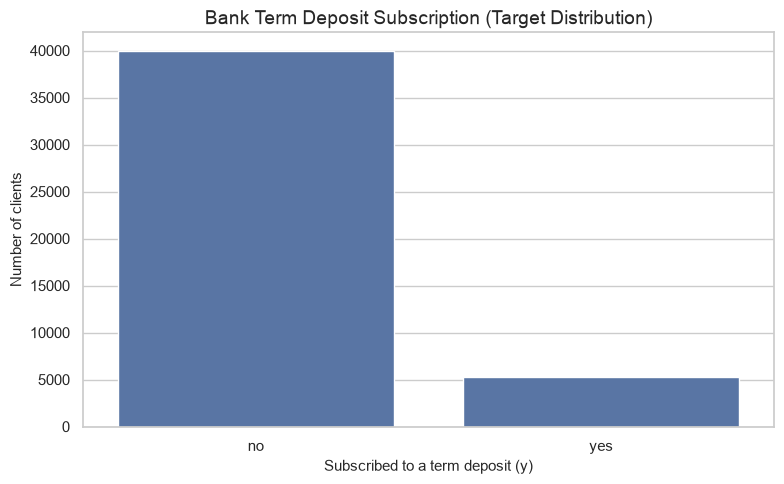

Saved chart to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/02_target_distribution.png


In [5]:
target_counts = df[target_column].value_counts(dropna=False)
target_percentages = df[target_column].value_counts(normalize=True, dropna=False) * 100
target_summary = pd.DataFrame(
    {
        "count": target_counts,
        "percentage": target_percentages.round(2),
    }
)
print("Target class distribution:")
display(target_summary)

target_order = target_counts.index.tolist()
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x=target_column, order=target_order, color=sns.color_palette()[0], ax=ax)
ax.set_title("Bank Term Deposit Subscription (Target Distribution)")
ax.set_xlabel("Subscribed to a term deposit (y)")
ax.set_ylabel("Number of clients")
ax.ticklabel_format(axis="y", style="plain")
fig.tight_layout()
target_plot_path = PLOTS_DIR / "02_target_distribution.png"
fig.savefig(target_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved chart to: {target_plot_path}")

## Section 7: Numerical Feature Overview

The summary and histogram grid cover the dataset's numerical columns. Histograms provide a first look at the distributions; they are descriptive and do not imply that the features need any particular transformation.

Descriptive statistics for numerical features:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


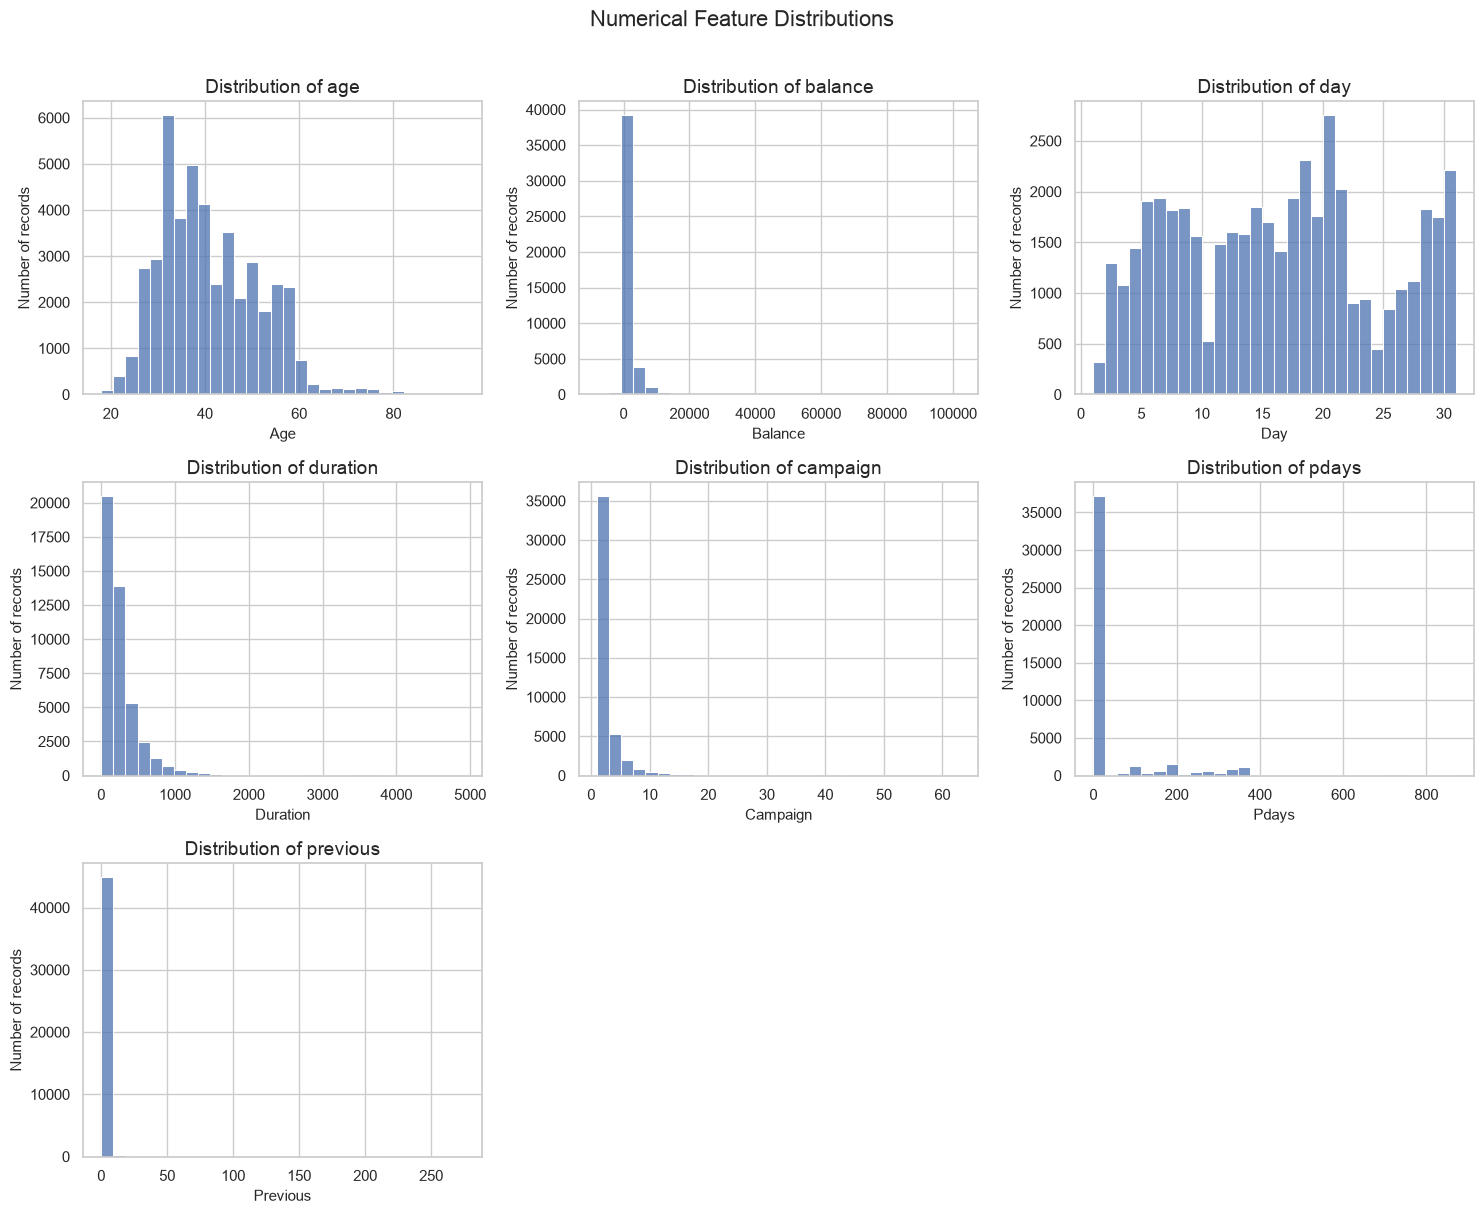

Saved chart to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/01_numerical_distributions.png


In [6]:
print("Descriptive statistics for numerical features:")
display(df[numeric_columns].describe().T)

number_of_columns = 3
number_of_rows = int(np.ceil(len(numeric_columns) / number_of_columns))
fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(15, 4 * number_of_rows),
)
axes = np.array(axes).reshape(-1)

for axis, column in zip(axes, numeric_columns):
    sns.histplot(data=df, x=column, bins=30, color=sns.color_palette()[0], ax=axis)
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column.replace("_", " ").title())
    axis.set_ylabel("Number of records")

for axis in axes[len(numeric_columns):]:
    axis.remove()

fig.suptitle("Numerical Feature Distributions", fontsize=16, y=1.01)
fig.tight_layout()
numerical_plot_path = PLOTS_DIR / "01_numerical_distributions.png"
fig.savefig(numerical_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved chart to: {numerical_plot_path}")

## Section 8: Initial Findings

This summary is generated from the loaded data and the checks above. It is an initial EDA snapshot, not a final analysis or a model result.

In [7]:
nonzero_unknowns = unknown_summary[unknown_summary["unknown_count"] > 0]
unknown_findings = (
    "; ".join(
        f"{column}: {int(row['unknown_count']):,} ({row['unknown_percentage']:.2f}%)"
        for column, row in nonzero_unknowns.iterrows()
    )
    if not nonzero_unknowns.empty
    else "No literal 'unknown' values were found in categorical input features."
)
target_findings = "; ".join(
    f"{label}: {int(target_summary.loc[label, 'count']):,} "
    f"({target_summary.loc[label, 'percentage']:.2f}%)"
    for label in target_summary.index
)

print(f"Dataset dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns.")
print(
    f"Input features: {len(input_feature_columns)} (target '{target_column}' "
    "is excluded from this count)."
)
print(f"Target distribution: {target_findings}.")
print(f"Conventional missing values: {int(missing_by_column.sum()):,}.")
print(f"Exact duplicate rows: {duplicate_count:,}.")
print(f"Categorical input features with literal 'unknown' values: {unknown_findings}.")
print(
    "Initial EDA only: no rows were deleted, no values were changed, and "
    "no predictive model was trained."
)

Dataset dimensions: 45,211 rows and 17 columns.
Input features: 16 (target 'y' is excluded from this count).
Target distribution: no: 39,922 (88.30%); yes: 5,289 (11.70%).
Conventional missing values: 0.
Exact duplicate rows: 0.
Categorical input features with literal 'unknown' values: job: 288 (0.64%); education: 1,857 (4.11%); contact: 13,020 (28.80%); poutcome: 36,959 (81.75%).
Initial EDA only: no rows were deleted, no values were changed, and no predictive model was trained.


## Section 9: Next Steps

- **Phase 2:** Data cleaning and preprocessing.
- **Phase 3:** Advanced EDA and at least five visualizations.
- **Phase 4:** Feature engineering and data splitting.
- **Phase 5:** MLP deep-learning model.
- **Phase 6:** Hyperparameter tuning.
- **Phase 7:** Model evaluation and result visualizations.
- **Phase 8:** Feature importance and interpretation.
- **Phase 9:** Final report and GitHub submission.

Those phases are future work; this notebook completes Phase 1 only.

## Section 10: Phase 2 — Data Quality Review

Data cleaning is intended to identify missing, duplicated, inconsistent, or unusual records before preprocessing. This review rechecks the loaded dataset rather than assuming Phase 1 results are still current. The checks are diagnostic only: this phase does not drop rows or rewrite source values.

In [8]:
# Recheck the loaded data and basic dataset structure.
print(f"Current dataset dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Input feature count (excluding target): {df.shape[1] - 1}")

phase2_missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
})
print("\nMissing values by column:")
display(phase2_missing)
print(f"Total missing values: {int(df.isna().sum().sum()):,}")

phase2_duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows: {phase2_duplicate_count:,}")

phase2_numeric_columns = df.select_dtypes(include="number").columns.tolist()
phase2_categorical_columns = [
    column for column in df.select_dtypes(exclude="number").columns
    if column != target_column
]
phase2_data_types = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
})
print("\nData types and non-null counts:")
display(phase2_data_types)

# Recheck literal unknown labels without treating them as null values.
phase2_unknown_counts = df[phase2_categorical_columns].apply(
    lambda column: column.astype("string").str.strip().str.lower().eq("unknown").sum()
).astype("int64")
phase2_unknown_summary = pd.DataFrame({
    "categorical_feature": phase2_unknown_counts.index,
    "unknown_count": phase2_unknown_counts.values,
    "unknown_percentage": (phase2_unknown_counts.values / len(df) * 100).round(2),
})
print("\nUnknown-value counts for categorical input features:")
display(phase2_unknown_summary)

# Validate recorded category labels against the dataset documentation.
phase2_valid_categories = {
    "job": {"admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services"},
    "marital": {"married", "divorced", "single"},
    "education": {"unknown", "secondary", "primary", "tertiary"},
    "default": {"yes", "no"},
    "housing": {"yes", "no"},
    "loan": {"yes", "no"},
    "contact": {"unknown", "telephone", "cellular"},
    "month": {"jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"},
    "poutcome": {"unknown", "other", "failure", "success"},
    "y": {"yes", "no"},
}
phase2_unexpected_categories = {
    column: sorted(df.loc[~df[column].isin(allowed), column].dropna().unique().tolist())
    for column, allowed in phase2_valid_categories.items()
    if column in df.columns
}
print("\nUnexpected categorical values (empty lists mean none found):")
display(pd.Series(phase2_unexpected_categories, name="unexpected_values").to_frame())

# Review numeric ranges and distribution summaries, not just data types.
phase2_numeric_summary = df[phase2_numeric_columns].describe().T
phase2_numeric_summary["minimum"] = df[phase2_numeric_columns].min()
phase2_numeric_summary["maximum"] = df[phase2_numeric_columns].max()
print("\nNumerical distributions and ranges:")
display(phase2_numeric_summary)

print("\nNo records or values have been removed or changed in this review.")

Current dataset dimensions: 45,211 rows x 17 columns
Input feature count (excluding target): 16

Missing values by column:


,missing_count,missing_percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


Total missing values: 0
Exact duplicate rows: 0

Data types and non-null counts:


,data_type,non_null_count
age,int64,45211
job,str,45211
marital,str,45211
education,str,45211
default,str,45211
balance,int64,45211
housing,str,45211
loan,str,45211
contact,str,45211
day,int64,45211



Unknown-value counts for categorical input features:


...


Unexpected categorical values (empty lists mean none found):

,unexpected_values
job,[]
marital,[]
education,[]
default,[]
housing,[]
loan,[]
contact,[]
month,[]
poutcome,[]
y,[]



Numerical distributions and ranges:


,count,mean,std,min,25%,50%,75%,max,minimum,maximum
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0,18,95
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0,-8019,102127
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0,1,31
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0,0,4918
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0,1,63
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0,-1,871
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0,0,275



No records or values have been removed or changed in this review.


## Section 11: Unknown Category Analysis

The table below reports literal `unknown` values as counts and as a percentage of all records in each categorical input feature. An `unknown` value can mean that a value was not recorded or was not known in the source process; it is still an explicit dataset label, not necessarily a conventional null. In particular, this dataset documentation lists `unknown` among valid categories for several fields. We preserve it as a category for this initial analysis and do not replace it with an invented value.

In [9]:
# Show unknown counts and percentages in a compact feature-oriented table.
unknown_category_table = phase2_unknown_summary[
    ["categorical_feature", "unknown_count", "unknown_percentage"]
].sort_values("unknown_count", ascending=False).reset_index(drop=True)
display(unknown_category_table)

,categorical_feature,unknown_count,unknown_percentage
0,poutcome,36959,81.75
1,contact,13020,28.80
2,education,1857,4.11
3,job,288,0.64
4,marital,0,0.00
5,default,0,0.00
6,housing,0,0.00
7,loan,0,0.00
8,month,0,0.00


## Section 12: Numerical Outlier Investigation

The interquartile range (IQR) rule marks values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR for investigation. These are statistical flags, not proof that an observation is invalid. The boxplots use a separate axis for each feature because their numerical scales differ substantially. No observations flagged by IQR are removed.

Interpretation needs domain context: `pdays = -1` is a documented sentinel for a customer who was not previously contacted. Repeated `-1` values affect its quartiles and IQR flags, so those flags should not be interpreted as invalid contact history. Negative account balances can be valid and are not removed merely for being negative.

Numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


IQR fences and flagged-value counts (flags are for investigation only):


,q1,q3,iqr,lower_fence,upper_fence,flagged_count,flagged_percentage
feature,,,,,,,
age,33.0,48.0,15.0,10.5,70.5,487,1.08
balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
day,8.0,21.0,13.0,-11.5,40.5,0,0.00
duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16
campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78
pdays,-1.0,-1.0,0.0,-1.0,-1.0,8257,18.26
previous,0.0,0.0,0.0,0.0,0.0,8257,18.26


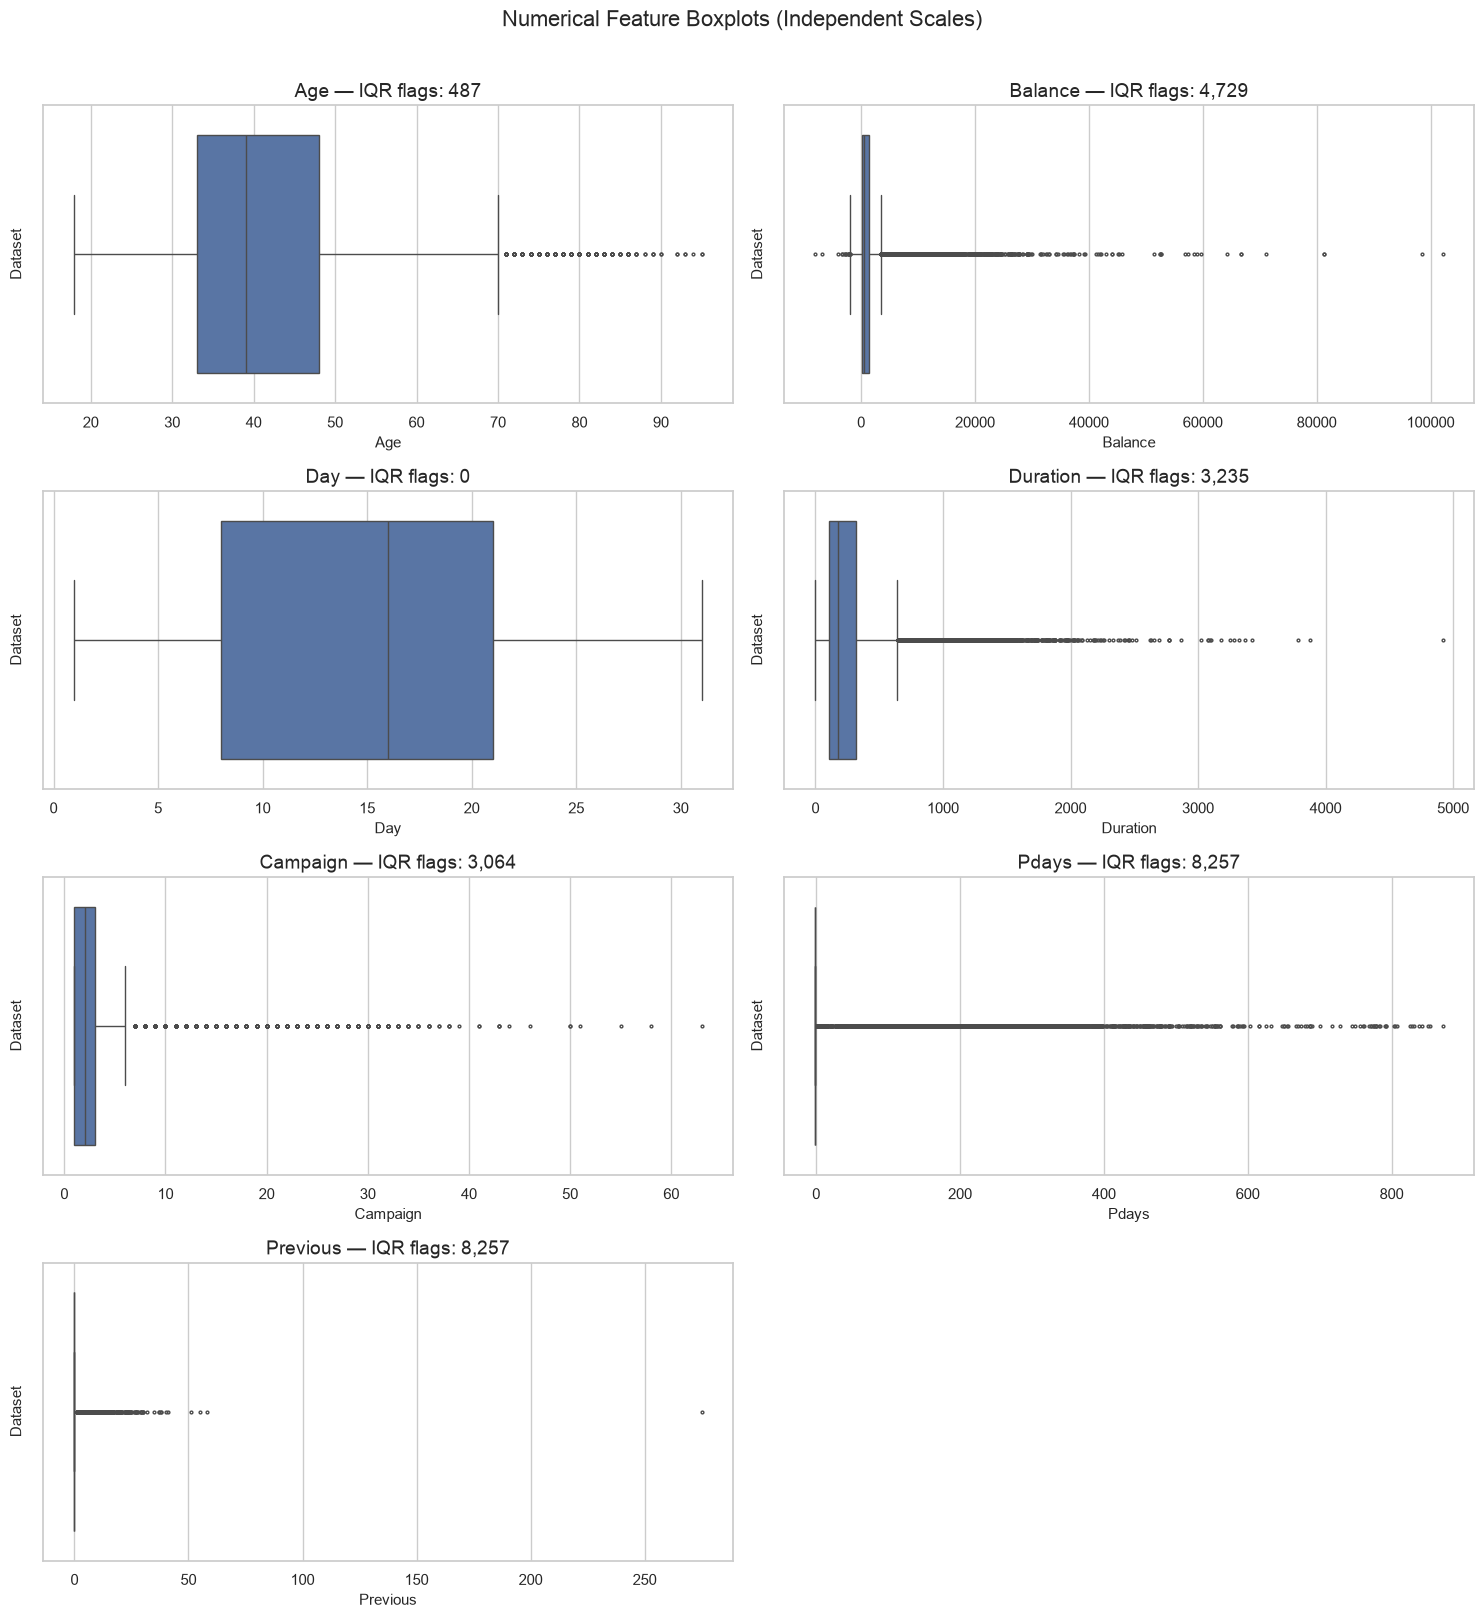

Saved boxplot figure to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/03_outlier_analysis.png
Note: IQR flags do not establish that a record is invalid; no rows were removed.


In [10]:
# Calculate the IQR bounds and number of flagged values for each numeric feature.
iqr_rows = []
for column in phase2_numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flagged_count = int(((df[column] < lower_fence) | (df[column] > upper_fence)).sum())
    iqr_rows.append({
        "feature": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "flagged_count": flagged_count,
        "flagged_percentage": flagged_count / len(df) * 100,
    })

iqr_summary = pd.DataFrame(iqr_rows).set_index("feature")
print("Numerical feature statistics:")
display(df[phase2_numeric_columns].describe().T)
print("IQR fences and flagged-value counts (flags are for investigation only):")
display(iqr_summary.round(2))

# Plot each feature on its own x-axis scale so large values in one field
# do not compress the boxes for other fields.
boxplot_columns = 2
boxplot_rows = int(np.ceil(len(phase2_numeric_columns) / boxplot_columns))
fig, axes = plt.subplots(
    boxplot_rows,
    boxplot_columns,
    figsize=(15, 4 * boxplot_rows),
    squeeze=False,
)
for axis, column in zip(axes.flat, phase2_numeric_columns):
    sns.boxplot(
        data=df,
        x=column,
        color=sns.color_palette()[0],
        fliersize=2,
        linewidth=1,
        ax=axis,
    )
    axis.set_title(f"{column.title()} — IQR flags: {iqr_summary.loc[column, 'flagged_count']:,}")
    axis.set_xlabel(column.replace("_", " ").title())
    axis.set_ylabel("Dataset")
for axis in axes.flat[len(phase2_numeric_columns):]:
    axis.remove()
fig.suptitle("Numerical Feature Boxplots (Independent Scales)", fontsize=16, y=1.01)
fig.tight_layout()
outlier_plot_path = PLOTS_DIR / "03_outlier_analysis.png"
fig.savefig(outlier_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved boxplot figure to: {outlier_plot_path}")
print("Note: IQR flags do not establish that a record is invalid; no rows were removed.")

## Section 13: Categorical Feature Frequencies

Frequency tables show the number and share of records for each category. For this review, a category occurring in less than 1% of the full dataset is flagged as relatively rare; this is a descriptive threshold, not a rule for dropping or combining categories. In later one-hot encoding, rare categories can produce sparse indicator columns and may be represented by very few training examples. Keep category decisions evidence-based and fit any encoder using training data only.

In [11]:
# Display full frequency tables and flag categories below the descriptive 1% threshold.
rare_category_threshold = 1.0
rare_category_rows = []
for column in phase2_categorical_columns:
    category_counts = df[column].value_counts(dropna=False)
    category_table = pd.DataFrame({
        "count": category_counts,
        "percentage": (category_counts / len(df) * 100).round(2),
    })
    category_table.index.name = column
    print(f"\nFrequency table for {column}:")
    display(category_table)
    for category, row in category_table.iterrows():
        if row["percentage"] < rare_category_threshold:
            rare_category_rows.append({
                "feature": column,
                "category": category,
                "count": int(row["count"]),
                "percentage": row["percentage"],
            })

rare_category_table = pd.DataFrame(
    rare_category_rows,
    columns=["feature", "category", "count", "percentage"],
)
print(f"Categories below {rare_category_threshold:.1f}% of all records:")
if rare_category_table.empty:
    print("None")
else:
    display(rare_category_table.sort_values(["feature", "percentage"]))
print("Rare categories are identified for review only; none were combined or removed.")


Frequency table for job:


,count,percentage
job,,
blue-collar,9732,21.53
management,9458,20.92
technician,7597,16.80
admin.,5171,11.44
services,4154,9.19
retired,2264,5.01
self-employed,1579,3.49
entrepreneur,1487,3.29
unemployed,1303,2.88



Frequency table for marital:


,count,percentage
marital,,
married,27214,60.19
single,12790,28.29
divorced,5207,11.52



Frequency table for education:


...


Frequency table for poutcome:


,count,percentage
poutcome,,
unknown,36959,81.75
failure,4901,10.84
other,1840,4.07
success,1511,3.34


Categories below 1.0% of all records:


,feature,category,count,percentage
0,job,unknown,288,0.64
1,month,dec,214,0.47


Rare categories are identified for review only; none were combined or removed.


## Section 14: Categorical Features and Subscription

For each selected category, the subscription rate is calculated as the number of `y == 'yes'` observations divided by the total observations in that category. Tables show both positive and negative counts, the group total, and the resulting percentage. The charts show observed counts and rates; they describe associations in this dataset and do not show that a feature causes subscription.


Subscription counts and rate by job:


,subscribed,not_subscribed,total,subscription_rate_pct
job,,,,
student,269,669,938,28.68
retired,516,1748,2264,22.79
unemployed,202,1101,1303,15.50
management,1301,8157,9458,13.76
admin.,631,4540,5171,12.20
self-employed,187,1392,1579,11.84
unknown,34,254,288,11.81
technician,840,6757,7597,11.06
services,369,3785,4154,8.88



Subscription counts and rate by education:


,subscribed,not_subscribed,total,subscription_rate_pct
education,,,,
tertiary,1996,11305,13301,15.01
unknown,252,1605,1857,13.57
secondary,2450,20752,23202,10.56
primary,591,6260,6851,8.63



Subscription counts and rate by marital:


...

,subscribed,not_subscribed,total,subscription_rate_pct
housing,,,,
no,3354,16727,20081,16.7
yes,1935,23195,25130,7.7



Subscription counts and rate by loan:


,subscribed,not_subscribed,total,subscription_rate_pct
loan,,,,
no,4805,33162,37967,12.66
yes,484,6760,7244,6.68



Subscription counts and rate by poutcome:


,subscribed,not_subscribed,total,subscription_rate_pct
poutcome,,,,
success,978,533,1511,64.73
other,307,1533,1840,16.68
failure,618,4283,4901,12.61
unknown,3386,33573,36959,9.16


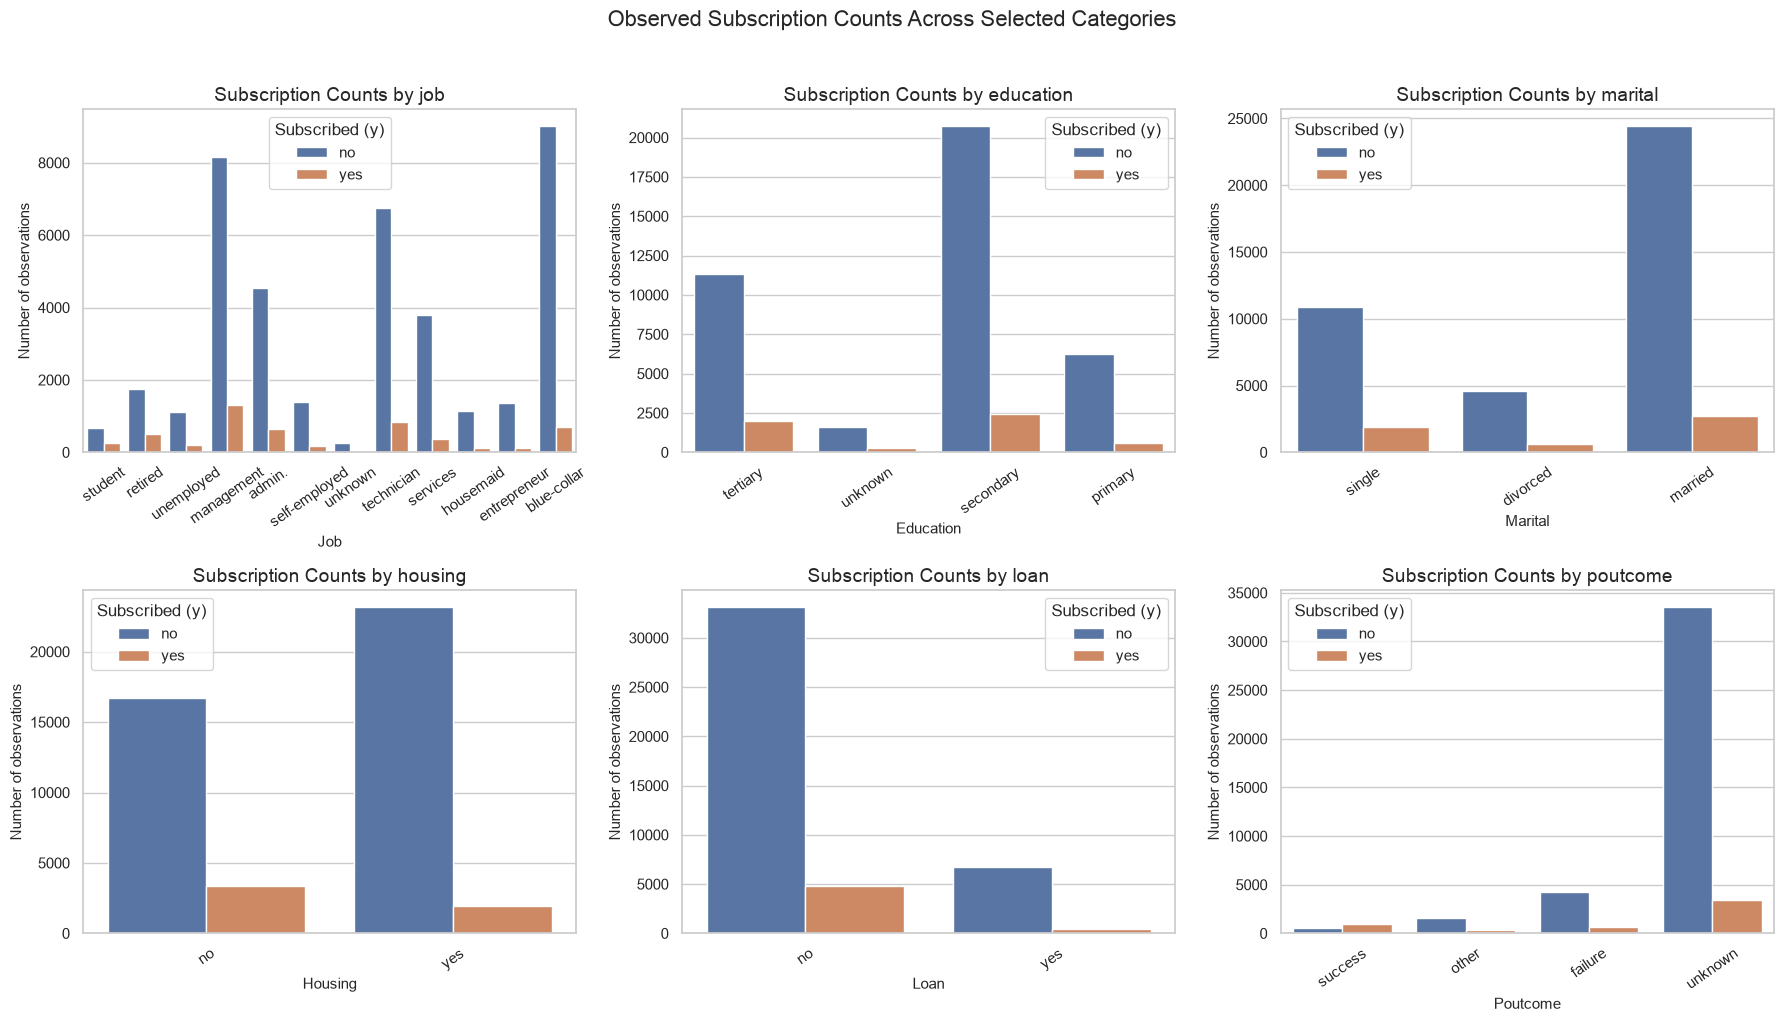

Saved count comparison to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/04_categorical_subscription_analysis.png


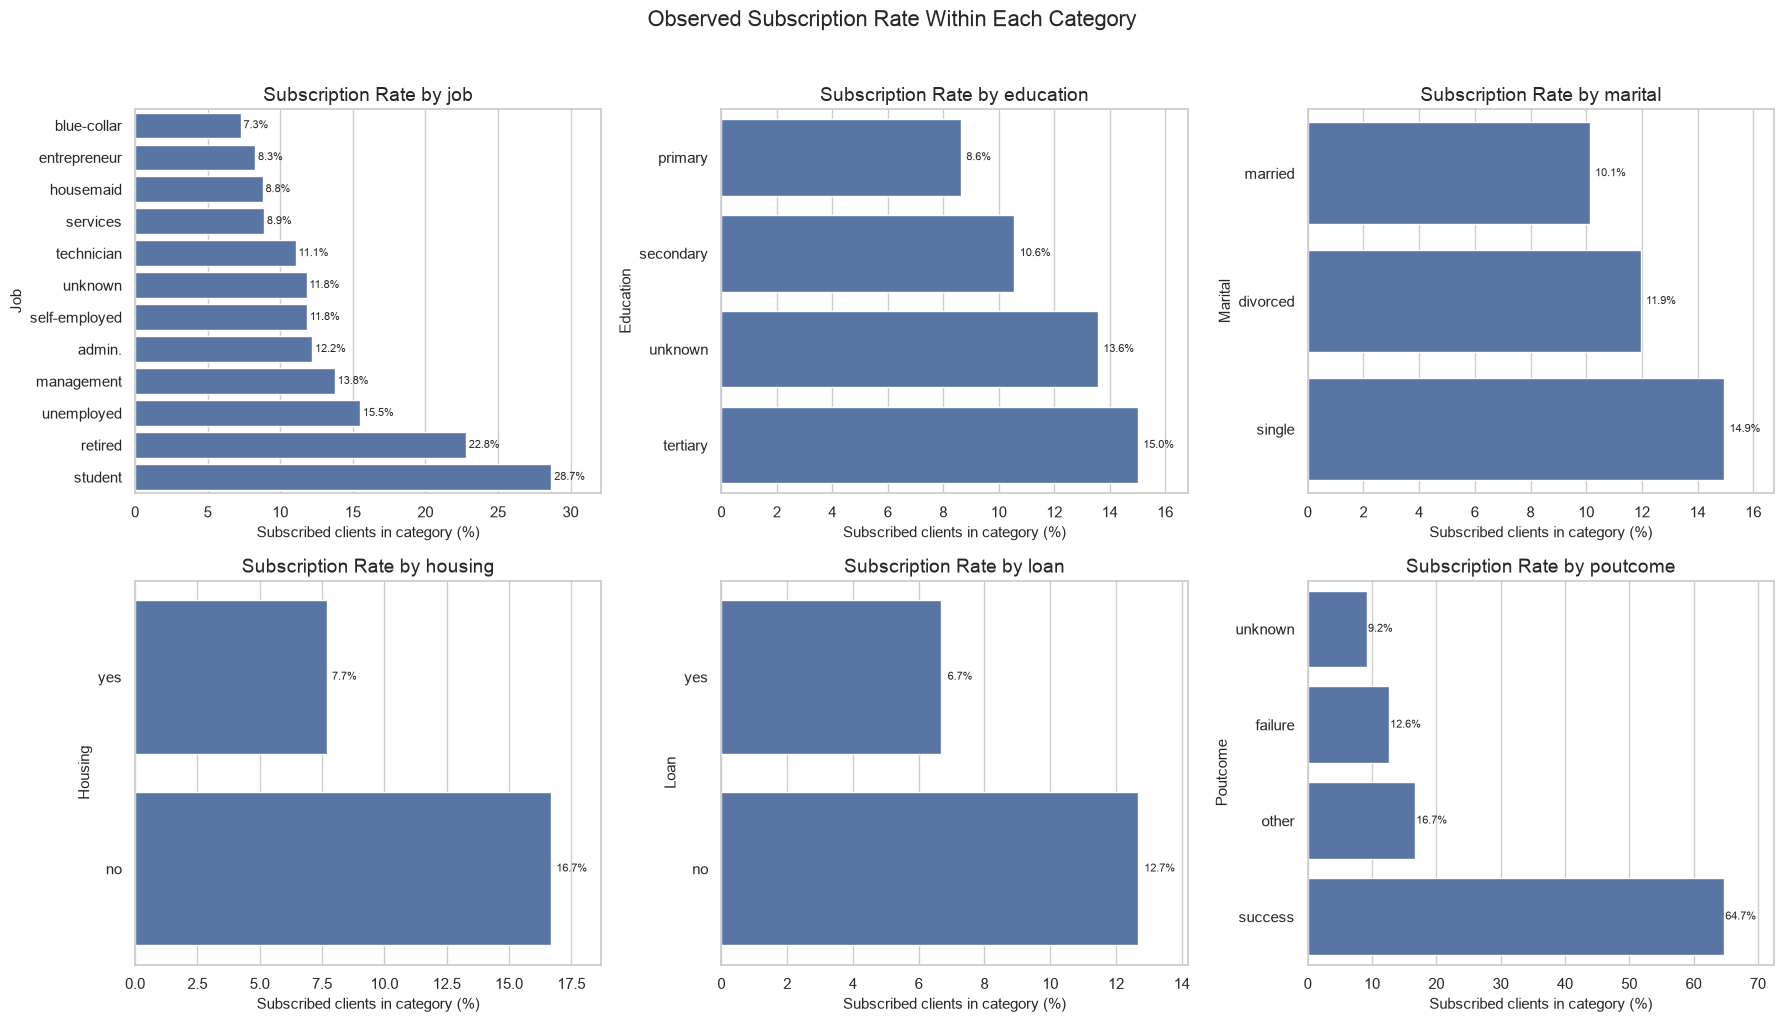

Saved rate comparison to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/05_subscription_rates.png
These are observed associations, not causal effects.


In [12]:
selected_categorical_features = ["job", "education", "marital", "housing", "loan", "poutcome"]
subscription_rate_frames = {}

for feature in selected_categorical_features:
    grouped = df.groupby(feature, dropna=False)[target_column].agg(
        total="size",
        subscribed=lambda values: values.eq("yes").sum(),
    )
    grouped["not_subscribed"] = grouped["total"] - grouped["subscribed"]
    grouped["subscription_rate_pct"] = (
        grouped["subscribed"] / grouped["total"] * 100
    ).round(2)
    grouped = grouped[["subscribed", "not_subscribed", "total", "subscription_rate_pct"]]
    grouped = grouped.sort_values("subscription_rate_pct", ascending=False)
    subscription_rate_frames[feature] = grouped.reset_index()
    print(f"\nSubscription counts and rate by {feature}:")
    display(grouped)

subscription_rates_long = pd.concat(
    [
        frame.assign(feature=feature).rename(columns={feature: "category"})
        for feature, frame in subscription_rate_frames.items()
    ],
    ignore_index=True,
)

# Figure 04 compares subscribed/not-subscribed counts within each feature.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, feature in zip(axes.flat, selected_categorical_features):
    sns.countplot(
        data=df,
        x=feature,
        hue=target_column,
        order=subscription_rate_frames[feature][feature].tolist(),
        hue_order=["no", "yes"],
        ax=axis,
    )
    axis.set_title(f"Subscription Counts by {feature}")
    axis.set_xlabel(feature.replace("_", " ").title())
    axis.set_ylabel("Number of observations")
    axis.tick_params(axis="x", rotation=35)
    axis.legend(title="Subscribed (y)")
fig.suptitle("Observed Subscription Counts Across Selected Categories", fontsize=16, y=1.02)
fig.tight_layout()
category_analysis_path = PLOTS_DIR / "04_categorical_subscription_analysis.png"
fig.savefig(category_analysis_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved count comparison to: {category_analysis_path}")

# Figure 05 compares category-level rates; each panel has its own category axis.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, feature in zip(axes.flat, selected_categorical_features):
    rate_data = subscription_rate_frames[feature].sort_values("subscription_rate_pct")
    sns.barplot(
        data=rate_data,
        x="subscription_rate_pct",
        y=feature,
        color=sns.color_palette()[0],
        ax=axis,
    )
    axis.set_title(f"Subscription Rate by {feature}")
    axis.set_xlabel("Subscribed clients in category (%)")
    axis.set_ylabel(feature.replace("_", " ").title())
    axis.set_xlim(0, max(10, float(rate_data["subscription_rate_pct"].max()) * 1.12))
    for patch, rate in zip(axis.patches, rate_data["subscription_rate_pct"]):
        axis.text(
            patch.get_width() + 0.2,
            patch.get_y() + patch.get_height() / 2,
            f"{rate:.1f}%",
            va="center",
            fontsize=8,
        )
fig.suptitle("Observed Subscription Rate Within Each Category", fontsize=16, y=1.02)
fig.tight_layout()
subscription_rate_plot_path = PLOTS_DIR / "05_subscription_rates.png"
fig.savefig(subscription_rate_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved rate comparison to: {subscription_rate_plot_path}")
print("These are observed associations, not causal effects.")

## Section 15: Future Preprocessing Decisions

The following are plans for later phases, not preprocessing operations performed here:

- **One-hot encoding:** encode categorical predictors as indicator columns while preserving recorded labels such as `unknown`. Review rare categories, because their indicator columns may be sparse. Learn encoder categories from training data and define how unseen categories are handled.
- **Numerical scaling:** use `StandardScaler` for numerical features where appropriate for the selected model. Fit its means and standard deviations on the training partition only, then use the fitted scaler to transform validation and test partitions.
- **Target encoding:** map binary target `y` to numeric labels consistently (for example, `no` → 0 and `yes` → 1). This is target-label encoding, not an input feature transformation.
- **Data split:** in the later splitting phase, create training, validation, and test partitions with stratification on `y` to preserve class proportions. Split before fitting preprocessing transformations.
- **Prevent leakage:** fit imputers, encoders, scalers, feature selection, and any other learned preprocessing only on training data. Apply those fitted transformations to validation/test data without refitting. This avoids allowing held-out information to influence training.

**Important `duration` limitation:** `duration` is the length of the last call in seconds and is only known after the marketing call. A primary model intended to predict subscription *before* a call must exclude `duration`, because it would not be available at prediction time and can leak post-contact information. Keep `duration` in the original DataFrame and use it only for EDA or a clearly labeled post-call comparison; do not delete or overwrite it in this phase.

## Section 16: Phase 2 Summary

The summary below is generated from the data and calculations above. Category-level differences are descriptive associations, not causal conclusions. This phase investigates data quality and prepares documented preprocessing decisions; it does not clean by deleting records, split the data, or train a model.

In [13]:
# Summarize actual checks and category-rate patterns from this run.
print(f"Dataset: {df.shape[0]:,} rows, {df.shape[1]} columns, {df.shape[1] - 1} input features.")
print(f"Conventional missing values: {int(df.isna().sum().sum()):,}.")
print(f"Exact duplicate rows: {phase2_duplicate_count:,}.")
print("Unknown values in categorical input features:")
for row in phase2_unknown_summary.itertuples(index=False):
    if row.unknown_count:
        print(f"  {row.categorical_feature}: {row.unknown_count:,} ({row.unknown_percentage:.2f}%).")

print("\nIQR investigation (statistical flags, not invalidity decisions):")
for feature, row in iqr_summary.iterrows():
    print(
        f"  {feature}: {int(row['flagged_count']):,} flagged "
        f"({row['flagged_percentage']:.2f}%; fences {row['lower_fence']:.2f} to {row['upper_fence']:.2f})."
    )
print("  pdays = -1 is a documented not-previously-contacted sentinel; negative balances can be valid.")

print("\nObserved category-rate comparisons (highest and lowest rates per feature):")
for feature, rates in subscription_rate_frames.items():
    highest = rates.iloc[0]
    lowest = rates.iloc[-1]
    print(
        f"  {feature}: highest {highest[feature]!r} = {highest['subscribed']:,}/"
        f"{highest['total']:,} ({highest['subscription_rate_pct']:.2f}%); "
        f"lowest {lowest[feature]!r} = {lowest['subscribed']:,}/"
        f"{lowest['total']:,} ({lowest['subscription_rate_pct']:.2f}%)."
    )
print("These observed rates do not establish that any category causes subscription.")
print("\nPlanned later steps: preserve unknown categories; assess rare categories; one-hot encode predictors; scale numeric features where appropriate; encode y as binary; use stratified train/validation/test partitions; fit all learned preprocessing on training data only.")
print("Primary pre-call prediction plan: exclude duration because it is measured after the call; retain it in the source DataFrame.")
print("Phase 2 complete: no source records were removed, no final data split was created, and no model was trained.")

Dataset: 45,211 rows, 17 columns, 16 input features.
Conventional missing values: 0.
Exact duplicate rows: 0.
Unknown values in categorical input features:
  job: 288 (0.64%).
  education: 1,857 (4.11%).
  contact: 13,020 (28.80%).
  poutcome: 36,959 (81.75%).

IQR investigation (statistical flags, not invalidity decisions):
  age: 487 flagged (1.08%; fences 10.50 to 70.50).
  balance: 4,729 flagged (10.46%; fences -1962.00 to 3462.00).
  day: 0 flagged (0.00%; fences -11.50 to 40.50).
  duration: 3,235 flagged (7.16%; fences -221.00 to 643.00).
  campaign: 3,064 flagged (6.78%; fences -2.00 to 6.00).
  pdays: 8,257 flagged (18.26%; fences -1.00 to -1.00).
  previous: 8,257 flagged (18.26%; fences 0.00 to 0.00).
  pdays = -1 is a documented not-previously-contacted sentinel; negative balances can be valid.

Observed category-rate comparisons (highest and lowest rates per feature):
  job: highest 'student' = 269/938 (28.68%); lowest 'blue-collar' = 708/9,732 (7.27%).
  education: highes

# Phase 3: Advanced EDA and Data Visualization

This phase extends the earlier descriptive analysis with a numerical correlation heatmap and focused views of age and campaign contacts against subscription. All results are observational: charts summarize the recorded data and do not establish causal effects. The existing project-root detection and plot directory from Phase 1 are reused.

## Section 17: Numerical Correlation Heatmap

Correlation measures the direction and strength of a linear relationship between two numerical variables; values near +1 indicate a strong positive linear association, values near -1 a strong negative association, and values near 0 little linear association. Correlation does not prove causation and may miss non-linear relationships.

The heatmap below uses numerical input features only. The target `y` is categorical (`yes`/`no`) in the source data. Including it in a numeric correlation requires encoding it first, and the result would then measure association under that encoding rather than a general causal or predictive effect. It is therefore excluded from this feature-to-feature heatmap.

Numerical feature correlation matrix:


,age,balance,day,duration,campaign,pdays,previous
age,1.000,0.098,-0.009,-0.005,0.005,-0.024,0.001
balance,0.098,1.000,0.005,0.022,-0.015,0.003,0.017
day,-0.009,0.005,1.000,-0.030,0.162,-0.093,-0.052
duration,-0.005,0.022,-0.030,1.000,-0.085,-0.002,0.001
campaign,0.005,-0.015,0.162,-0.085,1.000,-0.089,-0.033
pdays,-0.024,0.003,-0.093,-0.002,-0.089,1.000,0.455
previous,0.001,0.017,-0.052,0.001,-0.033,0.455,1.000


Strongest absolute off-diagonal correlation: pdays and previous (r = 0.455).


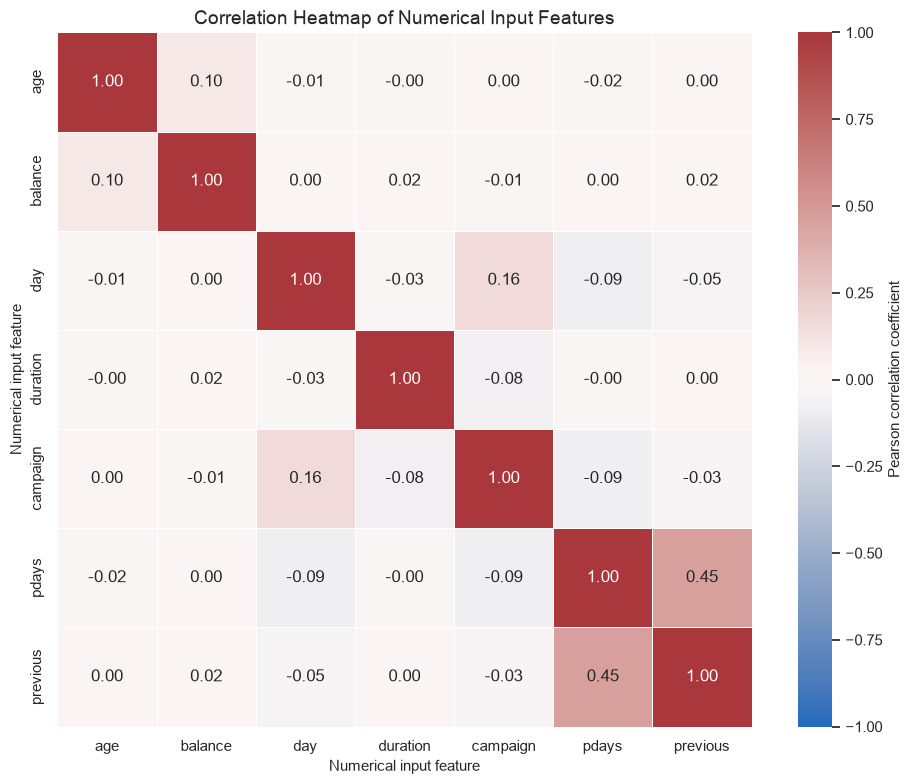

Saved correlation heatmap to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/06_correlation_heatmap.png


In [14]:
# Compute correlations only for numerical input features; y is not numeric here.
numeric_input_columns = [column for column in df.select_dtypes(include="number").columns if column != target_column]
numerical_correlation = df[numeric_input_columns].corr(method="pearson")

# Identify the strongest off-diagonal pair from this dataset.
upper_triangle = numerical_correlation.where(
    np.triu(np.ones(numerical_correlation.shape, dtype=bool), k=1)
)
strongest_correlation_pair = upper_triangle.stack().abs().idxmax()
strongest_correlation_value = numerical_correlation.loc[
    strongest_correlation_pair[0], strongest_correlation_pair[1]
]
print("Numerical feature correlation matrix:")
display(numerical_correlation.round(3))
print(
    f"Strongest absolute off-diagonal correlation: {strongest_correlation_pair[0]} "
    f"and {strongest_correlation_pair[1]} (r = {strongest_correlation_value:.3f})."
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    numerical_correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)
ax.set_title("Correlation Heatmap of Numerical Input Features")
ax.set_xlabel("Numerical input feature")
ax.set_ylabel("Numerical input feature")
fig.tight_layout()
correlation_plot_path = PLOTS_DIR / "06_correlation_heatmap.png"
fig.savefig(correlation_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved correlation heatmap to: {correlation_plot_path}")

### Figure 06 — Correlation Heatmap of Numerical Input Features

- **What it shows:** Pearson correlations between the seven numerical input features, without the categorical target.
- **Why it was created:** to quickly identify pairs of numerical variables with stronger linear associations.
- **Actual insight:** `pdays` and `previous` have the strongest absolute correlation (approximately **0.455**, positive). The next largest is `day` with `campaign` (approximately **0.162**, positive); remaining pairwise correlations are smaller in magnitude in this dataset.
- **Practical interpretation and limitations:** these values describe linear co-movement only. Correlation is not evidence that one feature causes another, and a small coefficient does not rule out a non-linear relationship. The target was excluded because it is categorical; encoding it would require a specifically interpreted analysis.

## Section 18: Age and Subscription

Compare customer age distributions for `y = yes` and `y = no`. The overlaid histograms use density rather than raw counts so that the larger `no` group does not dominate solely because it contains more records. The curves describe the observed sample; age differences do not show that age causes subscription.

Age summary by subscription outcome:


,observations,mean_age,median_age,standard_deviation
y,,,,
no,39922,40.84,39.0,10.17
yes,5289,41.67,38.0,13.50


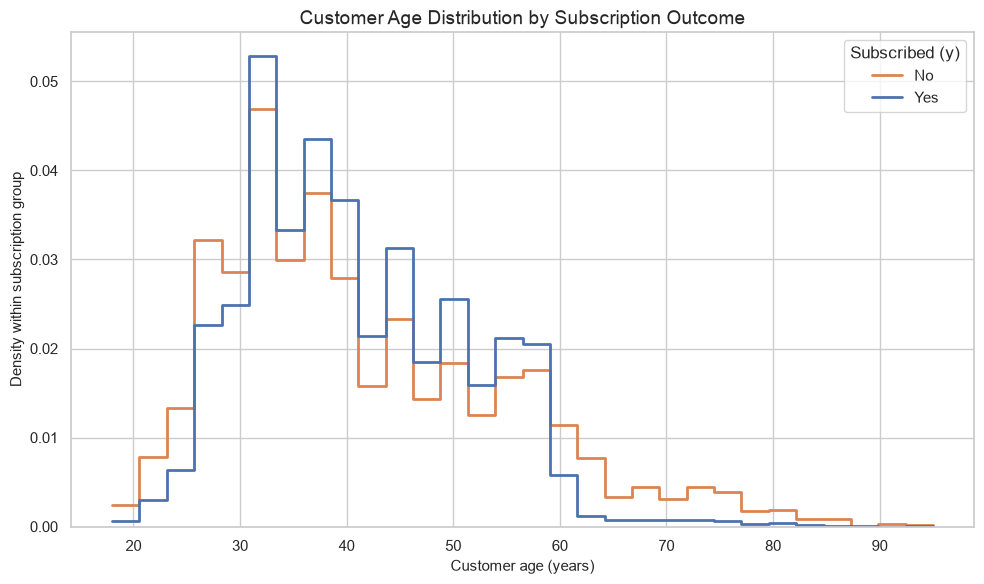

Saved age comparison to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/07_age_vs_subscription.png


In [15]:
age_summary_by_target = df.groupby(target_column)["age"].agg(
    observations="size",
    mean_age="mean",
    median_age="median",
    standard_deviation="std",
).round(2)
print("Age summary by subscription outcome:")
display(age_summary_by_target)

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    data=df,
    x="age",
    hue=target_column,
    hue_order=["no", "yes"],
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    linewidth=2,
    ax=ax,
)
ax.set_title("Customer Age Distribution by Subscription Outcome")
ax.set_xlabel("Customer age (years)")
ax.set_ylabel("Density within subscription group")
ax.legend(title="Subscribed (y)", labels=["No", "Yes"])
fig.tight_layout()
age_subscription_plot_path = PLOTS_DIR / "07_age_vs_subscription.png"
fig.savefig(age_subscription_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved age comparison to: {age_subscription_plot_path}")

### Figure 07 — Customer Age Distribution by Subscription Outcome

- **What it shows:** within-group age distributions for clients who subscribed and those who did not; each group's histogram is density-normalized.
- **Why it was created:** to compare the shape and central ages without letting the much larger non-subscriber group dominate the chart by count alone.
- **Actual insight:** in this dataset, the mean age is **41.67** for subscribers and **40.84** for non-subscribers, while the medians are **38** and **39** respectively. The groups have broadly overlapping age ranges (18–95).
- **Practical interpretation and limitations:** the difference in means is small relative to the overlapping distributions, and the larger subscriber-group spread (standard deviation **13.50** versus **10.17**) indicates additional variation. These descriptive summaries do not establish a causal relationship or the value of age in a future model.

## Section 19: Campaign Contacts and Subscription

`campaign` is the number of contacts made during the current campaign for a client. The table below reports every observed contact-count group, its total observations, subscribed count, and subscription rate calculated as subscribed / total. Because some high-contact groups contain only a handful of records, the rate panel only plots groups with at least 100 observations. This display threshold is for readability and stability of the descriptive comparison; it does not remove those records from the data or analysis table.

Campaign contact groups (all observed values; rate = subscribed / observations):

,observations,subscribed,not_subscribed,subscription_rate_pct
campaign,,,,
1,17544,2561,14983,14.60
2,12505,1401,11104,11.20
3,5521,618,4903,11.19
4,3522,317,3205,9.00
5,1764,139,1625,7.88
6,1291,92,1199,7.13
7,735,47,688,6.39
8,540,32,508,5.93
9,327,21,306,6.42


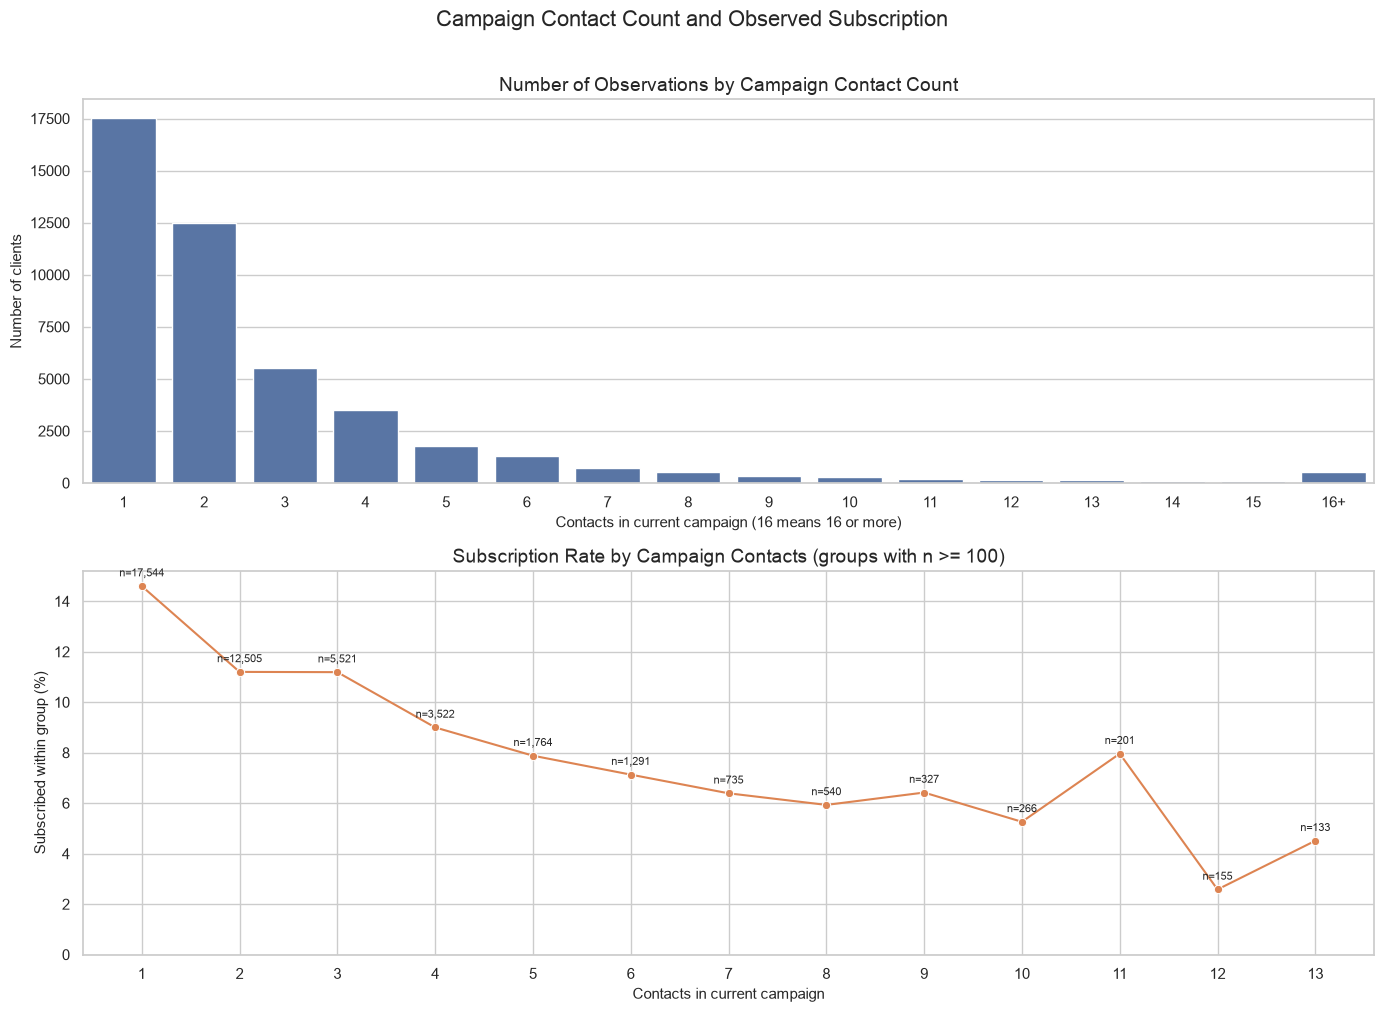

Saved campaign analysis to: /Users/dhananjaymandal/EDA-Bank-Marketing/outputs/plots/08_campaign_vs_subscription.png
Rate chart includes 13 of 48 exact contact-count groups with at least 100 observations.


In [16]:
campaign_summary = df.groupby("campaign")[target_column].agg(
    observations="size",
    subscribed=lambda values: values.eq("yes").sum(),
)
campaign_summary["not_subscribed"] = campaign_summary["observations"] - campaign_summary["subscribed"]
campaign_summary["subscription_rate_pct"] = (
    campaign_summary["subscribed"] / campaign_summary["observations"] * 100
).round(2)
print("Campaign contact groups (all observed values; rate = subscribed / observations):")
display(campaign_summary)

# Combine campaign values 16 and above only in the all-groups count panel to
# keep category labels readable. The rate panel uses exact values and a clear
# minimum-group-size threshold; the table above retains every exact group.
campaign_count_plot_data = campaign_summary["observations"].rename("observations").reset_index()
campaign_count_plot_data["campaign_group"] = campaign_count_plot_data["campaign"].where(
    campaign_count_plot_data["campaign"] <= 15,
    16,
)
campaign_count_plot_data["campaign_group"] = campaign_count_plot_data["campaign_group"].map(
    lambda value: "16+" if value == 16 else str(int(value))
)
campaign_count_plot_data = (
    campaign_count_plot_data.groupby("campaign_group", sort=False)["observations"]
    .sum()
    .reindex([*(str(value) for value in range(1, 16)), "16+"])
    .dropna()
    .rename_axis("campaign_group")
    .reset_index()
)

minimum_group_size_for_rate_plot = 100
campaign_rate_plot_data = campaign_summary[
    campaign_summary["observations"] >= minimum_group_size_for_rate_plot
].reset_index()

fig, (count_ax, rate_ax) = plt.subplots(2, 1, figsize=(14, 10))
sns.barplot(
    data=campaign_count_plot_data,
    x="campaign_group",
    y="observations",
    color=sns.color_palette()[0],
    ax=count_ax,
)
count_ax.set_title("Number of Observations by Campaign Contact Count")
count_ax.set_xlabel("Contacts in current campaign (16 means 16 or more)")
count_ax.set_ylabel("Number of clients")
count_ax.tick_params(axis="x", rotation=0)

sns.lineplot(
    data=campaign_rate_plot_data,
    x="campaign",
    y="subscription_rate_pct",
    marker="o",
    color=sns.color_palette()[1],
    ax=rate_ax,
)
for row in campaign_rate_plot_data.itertuples(index=False):
    rate_ax.annotate(
        f"n={row.observations:,}",
        (row.campaign, row.subscription_rate_pct),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8,
    )
rate_ax.set_title(
    f"Subscription Rate by Campaign Contacts (groups with n >= {minimum_group_size_for_rate_plot})"
)
rate_ax.set_xlabel("Contacts in current campaign")
rate_ax.set_ylabel("Subscribed within group (%)")
rate_ax.set_xticks(campaign_rate_plot_data["campaign"])
rate_ax.tick_params(axis="x", rotation=0)
rate_ax.set_ylim(bottom=0)

fig.suptitle("Campaign Contact Count and Observed Subscription", fontsize=16, y=1.01)
fig.tight_layout()
campaign_subscription_plot_path = PLOTS_DIR / "08_campaign_vs_subscription.png"
fig.savefig(campaign_subscription_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved campaign analysis to: {campaign_subscription_plot_path}")
print(
    f"Rate chart includes {len(campaign_rate_plot_data)} of {len(campaign_summary)} "
    f"exact contact-count groups with at least {minimum_group_size_for_rate_plot} observations."
)

### Figure 08 — Campaign Contact Count and Observed Subscription

- **What it shows:** the upper panel displays observation counts for each contact count from 1 to 15 and a combined `16+` display bin. The lower panel plots exact campaign-count subscription rates only for groups with at least 100 observations; each point is labeled with its group size. The accompanying table retains exact counts and rates for every campaign value.
- **Why it was created:** group size is essential context for interpreting a rate. Very small groups can produce extreme percentages from only one or two outcomes.
- **Actual insight:** the rate is **14.60%** for one contact, **11.20%** for two, **9.00%** for four, and **5.26%** for ten. Rates do not decrease smoothly: for example, nine contacts is **6.42%** and eleven is **7.96%**. Only **21 of 48** exact contact-count groups have at least 30 observations; groups with high contact counts are sparse.
- **Practical interpretation and limitations:** this is an observed association, not evidence that changing the number of calls causes a change in subscription. Contact count may be related to other campaign circumstances, and rates in sparse groups are uncertain. `16+` is a visual aggregation for the count panel only; the printed table and rate calculations preserve exact contact-count groups.

## Section 20: Seven Stages of Visualization

The seven stages describe a useful workflow for turning project data into visual evidence:

1. **Acquire:** obtain the Bank Marketing records from the provided `data/bank/bank-full.csv` file and consult `bank-names.txt` for field meanings.
2. **Parse:** read the semicolon-delimited file into a pandas DataFrame, check its dimensions and data types, and recognize categorical labels such as `unknown` and the `pdays = -1` sentinel.
3. **Filter:** choose relevant records or variables for a particular question. In this phase, the heatmap uses numerical features and the focused charts select age or campaign count; the source rows are not deleted.
4. **Mine:** calculate summaries such as category-level subscription rates, IQR flags, and numerical correlations to identify patterns worth examining.
5. **Represent:** map these results to visual forms: a correlation heatmap, age-density comparison, and campaign count/rate panels.
6. **Refine:** improve readability with titles, labels, meaningful scales, group-size context, and clear caveats. The new plots use separate numerical scales in the heatmap and density normalization for the imbalanced age groups.
7. **Interact:** allow viewers to explore or filter the visualized values. Matplotlib and Seaborn produce the static PNG charts used in this notebook. **Optional extension:** if Plotly is installed later, create a Plotly Express chart from the campaign summary (for example, campaign count on x, subscription rate on y, observation count as marker size, and hover fields for subscribed/total); render it in the notebook or export it as HTML. Plotly is not installed in the current environment, so no interactive chart is created in this phase.

These stages can be revisited as questions develop; they are a workflow aid rather than a one-way process.

## Section 21: Phase 3 EDA Summary

This summary is calculated from the currently loaded dataset and the outputs above. Correlations, rates, and distribution differences are observational associations; they do not establish causation. The survey/campaign data also has class imbalance, recorded `unknown` categories, and a post-call `duration` field that limits pre-call prediction.

In [17]:
# Summarize main Phase 1–3 findings directly from the loaded data and analyses.
phase3_target_counts = df[target_column].value_counts()
phase3_target_percentages = df[target_column].value_counts(normalize=True) * 100
phase3_yes_percentage = float(phase3_target_percentages.get("yes", 0.0))
phase3_no_percentage = float(phase3_target_percentages.get("no", 0.0))

print(f"Dataset dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns ({df.shape[1] - 1} input features).")
print(
    f"Target distribution: yes = {int(phase3_target_counts.get('yes', 0)):,} "
    f"({phase3_yes_percentage:.2f}%); no = {int(phase3_target_counts.get('no', 0)):,} "
    f"({phase3_no_percentage:.2f}%)."
)
print("The target is imbalanced: the yes class is the minority class.")

print("\nNumerical distribution context:")
for column in ["age", "balance", "duration", "campaign", "pdays", "previous"]:
    values = df[column]
    print(
        f"  {column}: median={values.median():,.2f}, IQR="
        f"{values.quantile(0.75) - values.quantile(0.25):,.2f}, "
        f"range={values.min():,.2f} to {values.max():,.2f}."
    )
print("  Earlier IQR checks flagged possible statistical outliers; they were not removed.")

print("\nSelected categorical associations (highest observed subscription rate per feature):")
for feature, rate_frame in subscription_rate_frames.items():
    top = rate_frame.loc[rate_frame["subscription_rate_pct"].idxmax()]
    print(
        f"  {feature}: {top[feature]!r}, {int(top['subscribed']):,}/"
        f"{int(top['total']):,} = {top['subscription_rate_pct']:.2f}%."
    )

print("\nNumerical correlation:")
print(
    f"  Strongest absolute pair: {strongest_correlation_pair[0]} and "
    f"{strongest_correlation_pair[1]} (r={strongest_correlation_value:.3f})."
)
print("  Correlation describes linear association, not causation; y was excluded because it is categorical.")

print("\nCampaign contact analysis:")
print(
    f"  Exact contact-count groups: {len(campaign_summary)}; groups with at least "
    f"{minimum_group_size_for_rate_plot} observations: {len(campaign_rate_plot_data)}."
)
print(
    f"  At one contact: {int(campaign_summary.loc[1, 'subscribed']):,}/"
    f"{int(campaign_summary.loc[1, 'observations']):,} = "
    f"{campaign_summary.loc[1, 'subscription_rate_pct']:.2f}%."
)
print(
    f"  At ten contacts: {int(campaign_summary.loc[10, 'subscribed']):,}/"
    f"{int(campaign_summary.loc[10, 'observations']):,} = "
    f"{campaign_summary.loc[10, 'subscription_rate_pct']:.2f}%."
)
print("  Rates are not smoothly decreasing and do not show that contact count causes subscription.")

print("\nData quality and interpretation limits:")
print(f"  Conventional missing values: {int(df.isna().sum().sum()):,}; exact duplicates: {int(df.duplicated().sum()):,}.")
unknown_features_present = phase2_unknown_summary.loc[phase2_unknown_summary["unknown_count"] > 0]
print(
    "  Unknown-category input features: "
    + (", ".join(unknown_features_present["categorical_feature"].tolist()) if not unknown_features_present.empty else "none")
    + "; unknown labels are preserved as categories."
)
print("  duration is measured after the call and should be excluded from a primary pre-call prediction feature set.")
print("All patterns above are observational associations. Phase 3 performs no model training or data splitting.")

Dataset dimensions: 45,211 rows x 17 columns (16 input features).
Target distribution: yes = 5,289 (11.70%); no = 39,922 (88.30%).
The target is imbalanced: the yes class is the minority class.

Numerical distribution context:
  age: median=39.00, IQR=15.00, range=18.00 to 95.00.
  balance: median=448.00, IQR=1,356.00, range=-8,019.00 to 102,127.00.
  duration: median=180.00, IQR=216.00, range=0.00 to 4,918.00.
  campaign: median=2.00, IQR=2.00, range=1.00 to 63.00.
  pdays: median=-1.00, IQR=0.00, range=-1.00 to 871.00.
  previous: median=0.00, IQR=0.00, range=0.00 to 275.00.
  Earlier IQR checks flagged possible statistical outliers; they were not removed.

Selected categorical associations (highest observed subscription rate per feature):
  job: 'student', 269/938 = 28.68%.
  education: 'tertiary', 1,996/13,301 = 15.01%.
  marital: 'single', 1,912/12,790 = 14.95%.
  housing: 'no', 3,354/20,081 = 16.70%.
  loan: 'no', 4,805/37,967 = 12.66%.
  poutcome: 'success', 978/1,511 = 64.73%.


# Phase 4: Feature Engineering and Data Preprocessing

Raw records contain categorical text labels and numerical columns with different scales. A neural network needs numerical input, and scaled numerical values can make optimization more stable. In this phase we define a pre-call prediction feature set, encode the binary target, create stratified train/validation/test partitions, and fit a reusable scikit-learn preprocessing pipeline. No neural network is trained in this phase.

The source DataFrame `df` is preserved. In particular, `duration` remains present in `df`, but it is excluded from the primary model feature matrix because call duration is only known after a call and would leak post-call information into a pre-call prediction task.

## Section 22: Define Target, Features, and Stratified Splits

The target is `y`, encoded as `no = 0` and `yes = 1`. Unexpected or missing target labels stop the workflow with a clear error. The primary prediction features include all original input fields except `duration`, leaving 15 original features. We separate target and input features before any preprocessing.

A stratified split maintains approximately the same target-class proportions across partitions. First, 70% of records are allocated to training; the remaining 30% are split equally into validation and test sets. Both splits use `random_state=42` for reproducibility. The test set is held out for final evaluation and is not used to fit preprocessing or tune future model choices.

In [18]:
from sklearn.model_selection import train_test_split

TARGET_COLUMN = "y"
TARGET_ENCODING = {"no": 0, "yes": 1}

if TARGET_COLUMN not in df.columns:
    raise KeyError(f"Required target column {TARGET_COLUMN!r} is missing from the dataset.")
if "duration" not in df.columns:
    raise KeyError("Expected 'duration' feature is missing; cannot apply the pre-call leakage safeguard.")

unexpected_target_mask = df[TARGET_COLUMN].isna() | ~df[TARGET_COLUMN].isin(TARGET_ENCODING)
if unexpected_target_mask.any():
    unexpected_target_values = df.loc[unexpected_target_mask, TARGET_COLUMN].unique().tolist()
    raise ValueError(
        "Target column 'y' must contain only 'no' and 'yes' with no missing values. "
        f"Unexpected values found: {unexpected_target_values}"
    )

# Exclude target and post-call duration while leaving the original df unchanged.
model_feature_columns = [
    column for column in df.columns
    if column not in {TARGET_COLUMN, "duration"}
]
X = df[model_feature_columns].copy()
y = df[TARGET_COLUMN].map(TARGET_ENCODING).astype("int64")

X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining,
)

print(f"Original dataset shape: {df.shape}")
print(f"Primary model input feature count: {len(model_feature_columns)}")
print(f"duration in original DataFrame: {'duration' in df.columns}")
print(f"duration in primary model features: {'duration' in model_feature_columns}")

split_targets = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test),
}
for split_name, (split_X, split_y) in split_targets.items():
    class_counts = split_y.value_counts().reindex([0, 1], fill_value=0)
    class_percentages = (split_y.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100)
    print(f"\n{split_name} set: X={split_X.shape}, y={split_y.shape}")
    print(
        f"  no (0): {int(class_counts.loc[0]):,} ({class_percentages.loc[0]:.2f}%) | "
        f"yes (1): {int(class_counts.loc[1]):,} ({class_percentages.loc[1]:.2f}%)"
    )

assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert "duration" not in X.columns
assert set(y.unique()) == {0, 1}

Original dataset shape: (45211, 17)
Primary model input feature count: 15
duration in original DataFrame: True
duration in primary model features: False

Training set: X=(31647, 15), y=(31647,)
  no (0): 27,945 (88.30%) | yes (1): 3,702 (11.70%)

Validation set: X=(6782, 15), y=(6782,)
  no (0): 5,988 (88.29%) | yes (1): 794 (11.71%)

Test set: X=(6782, 15), y=(6782,)
  no (0): 5,989 (88.31%) | yes (1): 793 (11.69%)


## Section 23: Identify Numerical and Categorical Features

Feature types are inferred from the actual input DataFrame dtypes after the target and `duration` have been excluded. Numerical columns are scaled; categorical columns must be encoded because their text labels cannot be directly interpreted as numeric measurements by an MLP. One-hot encoding creates a separate indicator for each category without inventing an order between labels.

In [19]:
# Infer column groups from the actual training feature data types.
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

if set(numerical_features).union(categorical_features) != set(X_train.columns):
    raise ValueError("Numerical and categorical groups do not cover all training features.")
if set(numerical_features).intersection(categorical_features):
    raise ValueError("A feature was assigned to both numerical and categorical groups.")

print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("Feature dtypes used for grouping:")
display(X_train.dtypes.astype(str).rename("data_type").to_frame())

Numerical features (6): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Feature dtypes used for grouping:


,data_type
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


## Section 24: Build and Fit the Preprocessing Pipeline

The numerical branch imputes with the median and then applies `StandardScaler`. The categorical branch imputes with the most frequent training value and one-hot encodes labels using `handle_unknown='ignore'`. Since this dataset currently has no conventional missing values, the imputers leave its valid observations unchanged; they are included so the pipeline can handle missing values consistently if encountered in future data.

The `ColumnTransformer` and its component pipelines are fitted **only** on `X_train`. The fitted transformer is then applied to all three partitions. This prevents validation/test distributions or category sets from influencing training preprocessing. We use a dense one-hot output here so that transformed arrays can be directly checked for numerical finiteness and passed to a typical TensorFlow/Keras MLP input layer.

In [20]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

# Fit exactly once, using training features only.
X_train_transformed = preprocessor.fit_transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

transformed_feature_names = preprocessor.get_feature_names_out()
transformed_feature_count = len(transformed_feature_names)

print(f"Original training feature count: {X_train.shape[1]}")
print(f"Number of transformed features: {transformed_feature_count}")
print(f"Transformed training shape: {X_train_transformed.shape}")
print(f"Transformed validation shape: {X_val_transformed.shape}")
print(f"Transformed test shape: {X_test_transformed.shape}")
print(f"Target array shapes: train={y_train.shape}, validation={y_val.shape}, test={y_test.shape}")
print(f"Transformed array type: {type(X_train_transformed).__name__}")
print(f"Transformed dtype: {X_train_transformed.dtype}")

transformed_splits = {
    "training": X_train_transformed,
    "validation": X_val_transformed,
    "test": X_test_transformed,
}
for split_name, transformed_array in transformed_splits.items():
    if not isinstance(transformed_array, np.ndarray):
        raise TypeError(f"Expected a dense NumPy array for {split_name} features.")
    if not np.issubdtype(transformed_array.dtype, np.number):
        raise TypeError(f"Transformed {split_name} features are not numeric.")
    if not np.isfinite(transformed_array).all():
        raise ValueError(f"Non-finite values remain in transformed {split_name} features.")
    print(f"{split_name.title()} transformed inputs are numeric and finite: True")

# The target arrays are integer labels suitable for binary classification loss functions.
y_train_array = y_train.to_numpy(dtype=np.int64)
y_val_array = y_val.to_numpy(dtype=np.int64)
y_test_array = y_test.to_numpy(dtype=np.int64)
for split_name, target_array in {
    "training": y_train_array,
    "validation": y_val_array,
    "test": y_test_array,
}.items():
    if not set(np.unique(target_array)).issubset({0, 1}):
        raise ValueError(f"Unexpected encoded target value found in {split_name} target array.")
    print(f"{split_name.title()} target array shape: {target_array.shape}; dtype: {target_array.dtype}")

print("\nFirst transformed feature names:")
print(transformed_feature_names[:20].tolist())

Original training feature count: 15
Number of transformed features: 50
Transformed training shape: (31647, 50)
Transformed validation shape: (6782, 50)
Transformed test shape: (6782, 50)
Target array shapes: train=(31647,), validation=(6782,), test=(6782,)
Transformed array type: ndarray
Transformed dtype: float64
Training transformed inputs are numeric and finite: True
Validation transformed inputs are numeric and finite: True
Test transformed inputs are numeric and finite: True
Training target array shape: (31647,); dtype: int64
Validation target array shape: (6782,); dtype: int64
Test target array shape: (6782,); dtype: int64

First transformed feature names:
['numerical__age', 'numerical__balance', 'numerical__day', 'numerical__campaign', 'numerical__pdays', 'numerical__previous', 'categorical__job_admin.', 'categorical__job_blue-collar', 'categorical__job_entrepreneur', 'categorical__job_housemaid', 'categorical__job_management', 'categorical__job_retired', 'categorical__job_self-

## Section 25: Save the Fitted Preprocessor and Phase 4 Summary

The fitted `ColumnTransformer` is saved with joblib so later phases can apply the exact training-fitted transformations to new records. The artifact is written only after all three transformed partitions have passed shape, numeric-type, finite-value, and target-label checks. The test features are transformed using the training-fitted preprocessor, but are not used to fit any transformation, select features, or evaluate a model in this phase. Keep the test set untouched for final evaluation after model development is complete.

In [21]:
import joblib

MODELS_DIR = PROJECT_ROOT / "models"
PREPROCESSOR_PATH = MODELS_DIR / "bank_marketing_preprocessor.joblib"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(preprocessor, PREPROCESSOR_PATH)

print("Phase 4 preprocessing summary")
print(f"Training rows: {len(X_train):,} ({len(X_train) / len(df) * 100:.1f}%)")
print(f"Validation rows: {len(X_val):,} ({len(X_val) / len(df) * 100:.1f}%)")
print(f"Test rows: {len(X_test):,} ({len(X_test) / len(df) * 100:.1f}%)")
print(f"Original model features: {len(model_feature_columns)}")
print(f"Transformed model features: {transformed_feature_count}")
print(f"Transformations: median imputation + StandardScaler for numerical features; most-frequent imputation + one-hot encoding for categorical features.")
print("Target encoding: no=0, yes=1.")
print("Stratified split random_state: 42.")
print("duration excluded from model features and retained in the original DataFrame: True.")
print("Preprocessor fitted using training features only: True.")
print(f"Saved fitted preprocessor to: {PREPROCESSOR_PATH}")
print("No neural network was trained and no model evaluation was performed in Phase 4.")

Phase 4 preprocessing summary
Training rows: 31,647 (70.0%)
Validation rows: 6,782 (15.0%)
Test rows: 6,782 (15.0%)
Original model features: 15
Transformed model features: 50
Transformations: median imputation + StandardScaler for numerical features; most-frequent imputation + one-hot encoding for categorical features.
Target encoding: no=0, yes=1.
Stratified split random_state: 42.
duration excluded from model features and retained in the original DataFrame: True.
Preprocessor fitted using training features only: True.
Saved fitted preprocessor to: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_preprocessor.joblib
No neural network was trained and no model evaluation was performed in Phase 4.


# PHASE 5: MODEL TRAINING AND EVALUATION

This phase compares a simple baseline with three supervised classifiers. The validation set is used for model comparison and selection; the test set remains held out until the selected model is evaluated once for a final estimate. The pre-call feature definition from Phase 4 is retained: `duration` is not supplied to any classifier because it is known only after the marketing call. No model performance is guaranteed to transfer identically to a real campaign.

## Section 26: Verify Phase 4 Data and Preprocessing

The train/validation/test partitions were created in Phase 4 with a stratified 70% / 15% / 15% split and `random_state=42`. The target uses `no = 0` and `yes = 1`; the target and post-call `duration` must not be model inputs. Phase 4 saved the fitted preprocessor at `models/bank_marketing_preprocessor.joblib`.

Before training, we confirm the saved transformer has the expected training feature names and output width. Its transformed arrays are used for model comparison, so classifiers do not refit preprocessing on validation or test records.

In [22]:
from pathlib import Path

expected_feature_columns = [column for column in df.columns if column not in {"y", "duration"}]
assert len(df) == 45_211, f"Unexpected source row count: {len(df):,}"
assert X_train.index.is_unique and X_val.index.is_unique and X_test.index.is_unique
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert model_feature_columns == expected_feature_columns
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert "y" not in X_train.columns and "duration" not in X_train.columns
assert set(y_train.unique()) == {0, 1}

phase4_preprocessor_path = PROJECT_ROOT / "models" / "bank_marketing_preprocessor.joblib"
if not phase4_preprocessor_path.is_file():
    raise FileNotFoundError(f"Phase 4 preprocessor artifact not found: {phase4_preprocessor_path}")
phase4_preprocessor = joblib.load(phase4_preprocessor_path)
if list(phase4_preprocessor.feature_names_in_) != expected_feature_columns:
    raise ValueError("Saved Phase 4 preprocessor feature names do not match the current model feature columns.")
if len(phase4_preprocessor.get_feature_names_out()) != X_train_transformed.shape[1]:
    raise ValueError("Saved Phase 4 preprocessor output width does not match the transformed training matrix.")

for split_name, transformed in {
    "training": X_train_transformed,
    "validation": X_val_transformed,
    "test": X_test_transformed,
}.items():
    if transformed.shape[1] != X_train_transformed.shape[1]:
        raise ValueError(f"Transformed {split_name} feature count differs from training.")
    if not np.isfinite(transformed).all():
        raise ValueError(f"Non-finite transformed feature values found in {split_name} data.")

print(f"Feature count: {len(expected_feature_columns)} raw model features; duration excluded.")
print(f"Transformed feature count: {X_train_transformed.shape[1]}.")
print(f"Split sizes: train={len(X_train):,}, validation={len(X_val):,}, test={len(X_test):,}.")
print(f"Loaded compatible Phase 4 preprocessor: {phase4_preprocessor_path}")
print("Training, validation, and test transformed columns are aligned, numeric, and finite.")

Feature count: 15 raw model features; duration excluded.
Transformed feature count: 50.
Split sizes: train=31,647, validation=6,782, test=6,782.
Loaded compatible Phase 4 preprocessor: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_preprocessor.joblib
Training, validation, and test transformed columns are aligned, numeric, and finite.


## Section 27: Baseline Model — DummyClassifier

A baseline is a simple reference model that shows how much performance is possible without learning useful relationships from the input features. We use `DummyClassifier(strategy='prior')`: it learns the training class proportions and predicts the most frequent class, while exposing the prior positive probability for score-based metrics.

Accuracy alone is misleading here: about 88.3% of records are `no`, so predicting `no` for every client can appear accurate while finding no subscribers. Recall, F1, and especially Average Precision help assess the minority positive class. **Average Precision (AP)** is `sklearn.metrics.average_precision_score`; it summarizes precision across recall thresholds and is not the trapezoidal area under the precision-recall curve.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)

CLASSIFICATION_THRESHOLD = 0.5
POSITIVE_CLASS = 1
baseline_model = DummyClassifier(strategy="prior")
baseline_model.fit(X_train_transformed, y_train_array)
baseline_prediction = baseline_model.predict(X_val_transformed)
baseline_positive_scores = baseline_model.predict_proba(X_val_transformed)[:, list(baseline_model.classes_).index(POSITIVE_CLASS)]
baseline_metrics = {
    "Accuracy": accuracy_score(y_val_array, baseline_prediction),
    "Precision": precision_score(y_val_array, baseline_prediction, pos_label=POSITIVE_CLASS, zero_division=0),
    "Recall": recall_score(y_val_array, baseline_prediction, pos_label=POSITIVE_CLASS, zero_division=0),
    "F1-score": f1_score(y_val_array, baseline_prediction, pos_label=POSITIVE_CLASS, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_array, baseline_positive_scores),
    "Average Precision (AP)": average_precision_score(y_val_array, baseline_positive_scores),
}
print(f"Baseline validation metrics at classification threshold {CLASSIFICATION_THRESHOLD:.2f}:")
display(pd.DataFrame([baseline_metrics], index=["DummyClassifier (prior)"]))

Baseline validation metrics at classification threshold 0.50:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP)
DummyClassifier (prior),0.882925,0.0,0.0,0.0,0.5,0.117075


## Section 28: Train Logistic Regression

Logistic Regression is a useful starting classifier because it is relatively simple and interpretable, and its predicted scores can examine how well a linear decision boundary separates the classes. `class_weight='balanced'` increases the penalty for mistakes on the less frequent subscription class. The model is fitted to the Phase 4 transformed training matrix only.

In [24]:
from sklearn.linear_model import LogisticRegression

logistic_regression_model = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)
logistic_regression_model.fit(X_train_transformed, y_train_array)
print("Logistic Regression fitted using training rows only.")

Logistic Regression fitted using training rows only.


## Section 29: Train Decision Tree

A Decision Tree learns a sequence of feature-based rules and can represent nonlinear relationships and feature interactions. Restricting depth and requiring a minimum number of samples per leaf helps control complexity at this initial comparison stage. Class weights are balanced to account for the minority subscription class.

In [25]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(class_weight="balanced", max_depth=12, min_samples_leaf=10, random_state=42)
decision_tree_model.fit(X_train_transformed, y_train_array)
print("Decision Tree fitted using training rows only.")

Decision Tree fitted using training rows only.


## Section 30: Train Random Forest

A Random Forest combines predictions from many decision trees trained with randomized samples/features. This can reduce the instability of a single tree and capture nonlinear patterns. We use 200 trees, balanced class weights, a depth limit and minimum leaf size to keep the first experiment practical on a student laptop. No hyperparameter search is performed in this phase.

In [26]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", max_depth=18,
    min_samples_leaf=5, random_state=42, n_jobs=-1,
)
random_forest_model.fit(X_train_transformed, y_train_array)
print("Random Forest fitted using training rows only.")

Random Forest fitted using training rows only.


## Section 31: Compare Models on the Validation Set

All models use the same training-fitted Phase 4 preprocessing and are evaluated on validation rows only. Class predictions use the initial threshold **0.50**; this conventional threshold is not necessarily optimal for an imbalanced dataset. For ROC-AUC and Average Precision we use the positive-class probability from `predict_proba` when available, or the continuous `decision_function` score otherwise—never hard predictions.

The comparison table is sorted by **Average Precision (AP)**, the chosen primary selection metric. AP is computed by `average_precision_score`; it is not the trapezoidal area under the plotted precision-recall curve.

In [27]:
validation_models = {
    "DummyClassifier (prior)": baseline_model,
    "Logistic Regression": logistic_regression_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
}


def get_positive_class_scores(model, feature_matrix):
    # Return continuous scores for positive class 1.
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(feature_matrix)
        positive_index = list(model.classes_).index(POSITIVE_CLASS)
        return probabilities[:, positive_index]
    if hasattr(model, "decision_function"):
        return model.decision_function(feature_matrix)
    raise TypeError(f"{type(model).__name__} provides neither predict_proba nor decision_function.")


validation_predictions = {}
validation_scores = {}
validation_metric_rows = []
for model_name, model in validation_models.items():
    predicted_labels = model.predict(X_val_transformed)
    positive_scores = get_positive_class_scores(model, X_val_transformed)
    validation_predictions[model_name] = predicted_labels
    validation_scores[model_name] = positive_scores
    validation_metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val_array, predicted_labels),
        "Precision": precision_score(y_val_array, predicted_labels, pos_label=POSITIVE_CLASS, zero_division=0),
        "Recall": recall_score(y_val_array, predicted_labels, pos_label=POSITIVE_CLASS, zero_division=0),
        "F1-score": f1_score(y_val_array, predicted_labels, pos_label=POSITIVE_CLASS, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_array, positive_scores),
        "Average Precision (AP)": average_precision_score(y_val_array, positive_scores),
        "Classification threshold": CLASSIFICATION_THRESHOLD,
    })

validation_metrics = pd.DataFrame(validation_metric_rows).set_index("Model")
validation_metrics = validation_metrics.sort_values("Average Precision (AP)", ascending=False)
RESULTS_DIR = PROJECT_ROOT / "results"
PHASE5_FIGURES_DIR = RESULTS_DIR / "figures" / "phase5"
PHASE5_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
validation_metrics_path = RESULTS_DIR / "phase5_validation_metrics.csv"
validation_metrics.to_csv(validation_metrics_path, index=True)
print(f"Validation metrics at threshold {CLASSIFICATION_THRESHOLD:.2f}, sorted by Average Precision (AP):")
display(validation_metrics.round(4))
print(f"Saved validation metrics to: {validation_metrics_path}")
if validation_metrics.isna().any().any():
    raise ValueError("Validation metrics contain missing values; investigate before proceeding.")

Validation metrics at threshold 0.50, sorted by Average Precision (AP):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP),Classification threshold
Model,,,,,,,
Random Forest,0.8303,0.3671,0.6209,0.4614,0.8016,0.4667,0.5
Logistic Regression,0.7566,0.2688,0.6272,0.3763,0.7720,0.4162,0.5
Decision Tree,0.7527,0.2665,0.6348,0.3754,0.7542,0.3917,0.5
DummyClassifier (prior),0.8829,0.0000,0.0000,0.0000,0.5000,0.1171,0.5


Saved validation metrics to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase5_validation_metrics.csv


### Figure 09 — Validation Average Precision Comparison

This bar chart compares **Average Precision (AP)** across validation-set models. AP summarizes the precision-recall trade-off across score thresholds and is informative when subscribers are the minority class. The selected classification threshold does not affect AP, which uses continuous scores.

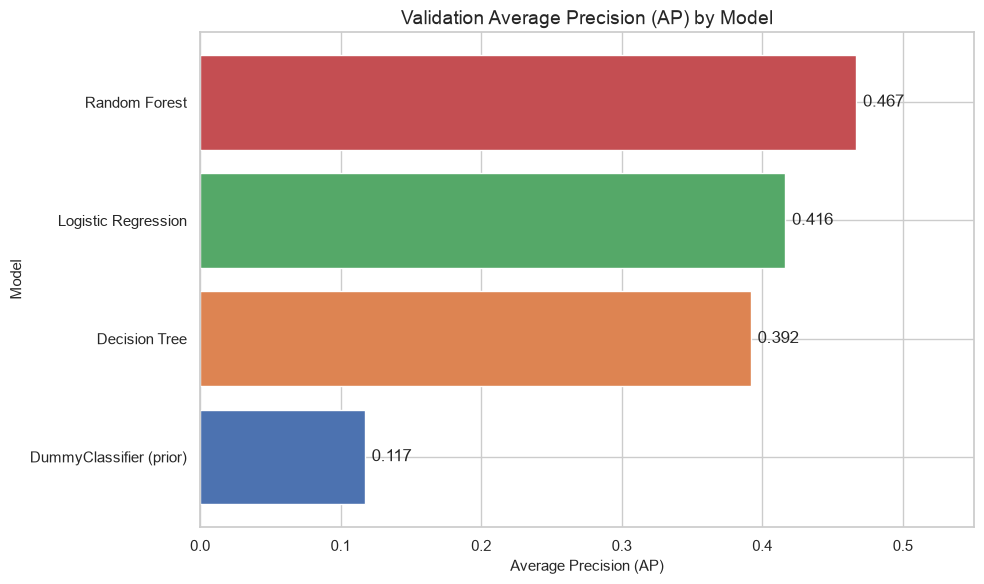

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/validation_average_precision.png


In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
ap_plot_data = validation_metrics["Average Precision (AP)"].sort_values()
bars = ax.barh(ap_plot_data.index, ap_plot_data.values, color=sns.color_palette("deep", len(ap_plot_data)))
ax.set_title("Validation Average Precision (AP) by Model")
ax.set_xlabel("Average Precision (AP)")
ax.set_ylabel("Model")
ax.set_xlim(0, min(1.0, max(0.2, float(ap_plot_data.max()) * 1.18)))
for bar, value in zip(bars, ap_plot_data.values):
    ax.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
fig.tight_layout()
validation_ap_plot_path = PHASE5_FIGURES_DIR / "validation_average_precision.png"
fig.savefig(validation_ap_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {validation_ap_plot_path}")

### Figure 10 — Validation F1-Score Comparison

F1-score is the harmonic mean of precision and recall at the documented 0.50 classification threshold. It gives a single threshold-specific summary that penalizes a very low value of either precision or recall. It does not replace the continuous-score Average Precision used to select the model.

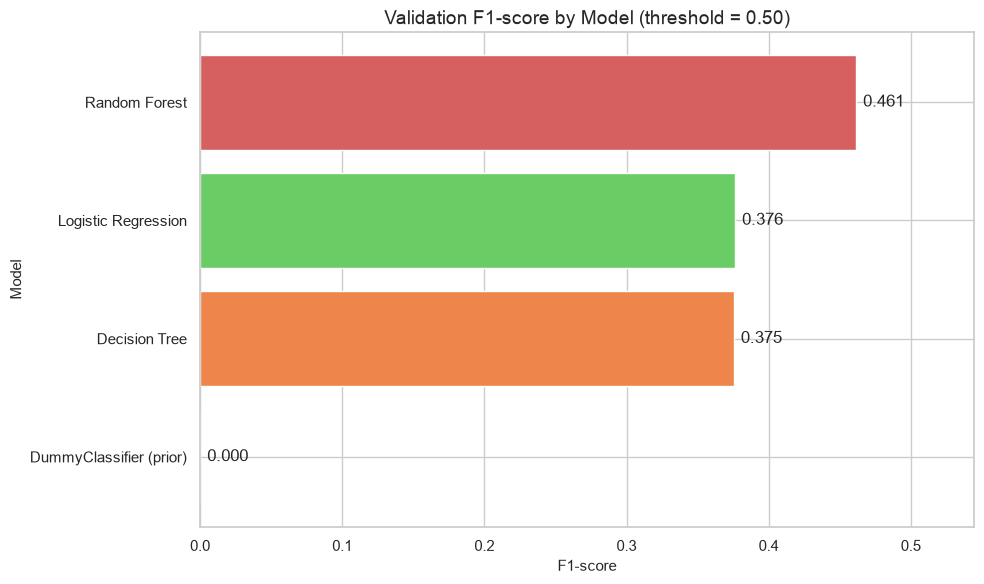

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/validation_f1_comparison.png


In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
f1_plot_data = validation_metrics["F1-score"].sort_values()
bars = ax.barh(f1_plot_data.index, f1_plot_data.values, color=sns.color_palette("muted", len(f1_plot_data)))
ax.set_title(f"Validation F1-score by Model (threshold = {CLASSIFICATION_THRESHOLD:.2f})")
ax.set_xlabel("F1-score")
ax.set_ylabel("Model")
ax.set_xlim(0, min(1.0, max(0.2, float(f1_plot_data.max()) * 1.18)))
for bar, value in zip(bars, f1_plot_data.values):
    ax.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
fig.tight_layout()
validation_f1_plot_path = PHASE5_FIGURES_DIR / "validation_f1_comparison.png"
fig.savefig(validation_f1_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {validation_f1_plot_path}")

### Figure 11 — Validation ROC Curves

The ROC curve plots true-positive rate against false-positive rate over score thresholds. ROC-AUC summarizes ranking performance across thresholds; 0.5 is the expected reference for random ranking. With substantial class imbalance, ROC-AUC should be read alongside Average Precision because it can appear favorable even when precision on the rare positive class is modest.

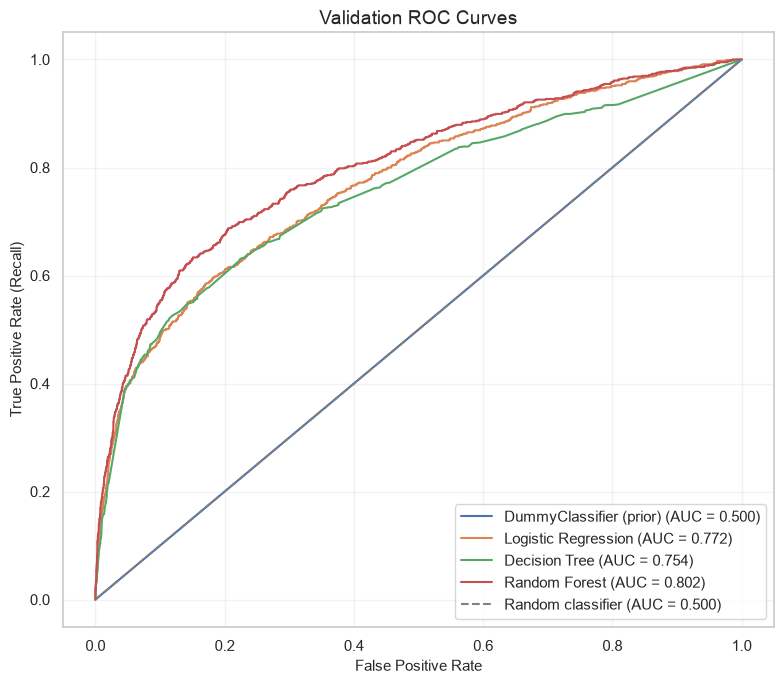

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/validation_roc_curves.png


In [30]:
fig, ax = plt.subplots(figsize=(8, 7))
for model_name, scores in validation_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_val_array, scores, pos_label=POSITIVE_CLASS)
    model_auc = validation_metrics.loc[model_name, "ROC-AUC"]
    ax.plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC = {model_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier (AUC = 0.500)")
ax.set_title("Validation ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
validation_roc_plot_path = PHASE5_FIGURES_DIR / "validation_roc_curves.png"
fig.savefig(validation_roc_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {validation_roc_plot_path}")

### Figure 12 — Validation Precision-Recall Curves

Precision-recall curves show precision versus recall at different score thresholds. They focus on retrieval of the positive subscription class and are especially informative under class imbalance. The horizontal reference is positive-class prevalence in the validation set; random ranking has expected AP near this prevalence. Legend values use sklearn's **Average Precision (AP)**, not trapezoidal PR area.

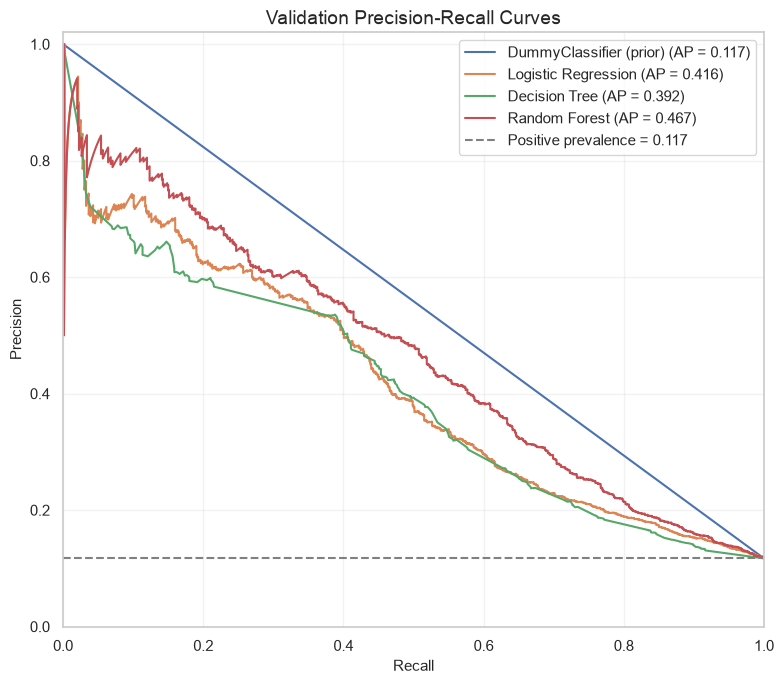

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/validation_precision_recall_curves.png


In [31]:
validation_positive_prevalence = float(np.mean(y_val_array == POSITIVE_CLASS))
fig, ax = plt.subplots(figsize=(8, 7))
for model_name, scores in validation_scores.items():
    precision_values, recall_values, _ = precision_recall_curve(y_val_array, scores, pos_label=POSITIVE_CLASS)
    model_ap = validation_metrics.loc[model_name, "Average Precision (AP)"]
    ax.plot(recall_values, precision_values, label=f"{model_name} (AP = {model_ap:.3f})")
ax.axhline(validation_positive_prevalence, linestyle="--", color="gray", label=f"Positive prevalence = {validation_positive_prevalence:.3f}")
ax.set_title("Validation Precision-Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
validation_pr_plot_path = PHASE5_FIGURES_DIR / "validation_precision_recall_curves.png"
fig.savefig(validation_pr_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {validation_pr_plot_path}")

### Figure 13 — Validation Confusion Matrices

Each matrix uses validation predictions at threshold 0.50. Rows are actual classes and columns are predicted classes, with readable labels for `No Subscription` and `Subscription`. These counts make false positives and missed subscriptions visible; they complement, rather than replace, precision, recall, F1, and score-based metrics.

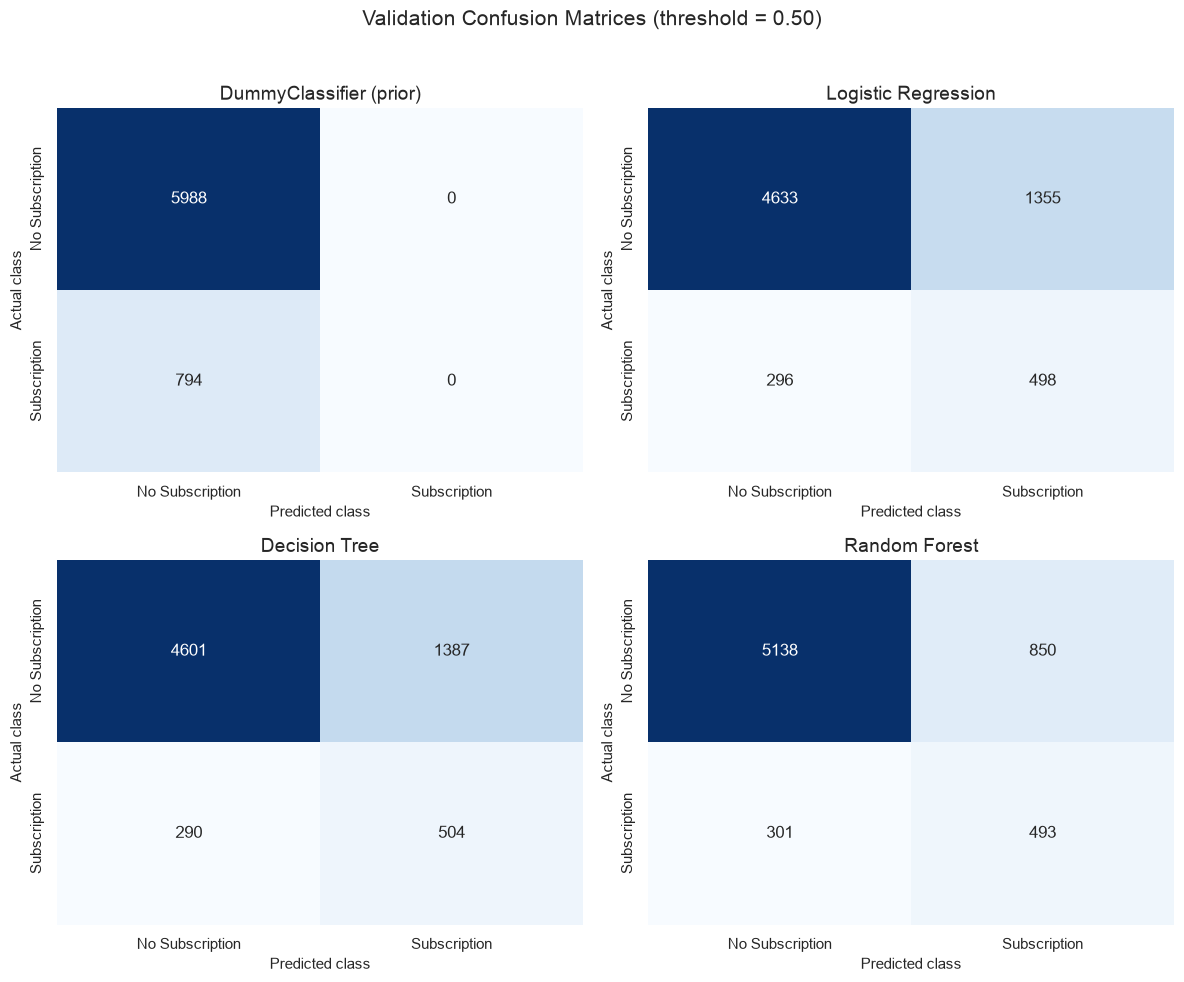

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/validation_confusion_matrices.png


In [32]:
class_display_labels = ["No Subscription", "Subscription"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for axis, (model_name, predicted_labels) in zip(axes.flat, validation_predictions.items()):
    matrix = confusion_matrix(y_val_array, predicted_labels, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_display_labels, yticklabels=class_display_labels, ax=axis)
    axis.set_title(model_name)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
for axis in axes.flat[len(validation_predictions):]:
    axis.remove()
fig.suptitle(f"Validation Confusion Matrices (threshold = {CLASSIFICATION_THRESHOLD:.2f})", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.96])
validation_cm_plot_path = PHASE5_FIGURES_DIR / "validation_confusion_matrices.png"
fig.savefig(validation_cm_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {validation_cm_plot_path}")

## Section 32: Select a Model Using Validation Average Precision

Average Precision is the primary selection metric because only about 11.7% of the records belong to the positive subscription class. It summarizes how well a model ranks true subscribers while tracking precision as recall increases; the positive prevalence provides a useful baseline. We select the highest measured validation AP. The test set is not used for this decision, and the 0.50 classification threshold remains unchanged in this phase.

In [33]:
selected_model_name = validation_metrics["Average Precision (AP)"].idxmax()
selected_validation_row = validation_metrics.loc[selected_model_name]
selected_classifier = validation_models[selected_model_name]
print("Validation-based model selection (test set not used):")
print(f"Selected model: {selected_model_name}")
print(f"Validation Average Precision (AP): {selected_validation_row['Average Precision (AP)']:.4f}")
print(f"Validation ROC-AUC: {selected_validation_row['ROC-AUC']:.4f}")
print(f"Validation precision at threshold {CLASSIFICATION_THRESHOLD:.2f}: {selected_validation_row['Precision']:.4f}")
print(f"Validation recall at threshold {CLASSIFICATION_THRESHOLD:.2f}: {selected_validation_row['Recall']:.4f}")
print(f"Validation F1-score at threshold {CLASSIFICATION_THRESHOLD:.2f}: {selected_validation_row['F1-score']:.4f}")
print("The selected classifier is chosen by validation AP only; test metrics will not change the selection.")

Validation-based model selection (test set not used):
Selected model: Random Forest
Validation Average Precision (AP): 0.4667
Validation ROC-AUC: 0.8016
Validation precision at threshold 0.50: 0.3671
Validation recall at threshold 0.50: 0.6209
Validation F1-score at threshold 0.50: 0.4614
The selected classifier is chosen by validation AP only; test metrics will not change the selection.


## Section 33: Build and Save the Combined Preprocessing-and-Model Pipeline

The validation comparison used already transformed arrays. For future inference from raw customer rows, the saved model must contain both preprocessing and the selected classifier. We therefore create a scikit-learn `Pipeline` with a fresh clone of the Phase 4 preprocessor followed by a clone of the selected classifier, and fit the combined pipeline on **raw `X_train` only**. This applies preprocessing exactly once within the pipeline; we do not pass already transformed arrays into it.

After fitting, validation predictions from the combined pipeline are checked against the selected validation model to confirm the raw-input pipeline reproduces the same fitted workflow. The model artifact includes the raw feature order expected by the fitted transformer.

In [34]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline

best_model_pipeline = SklearnPipeline([
    ("preprocessor", clone(phase4_preprocessor)),
    ("classifier", clone(selected_classifier)),
])
best_model_pipeline.fit(X_train, y_train_array)
combined_validation_scores = get_positive_class_scores(best_model_pipeline, X_val)
standalone_validation_scores = get_positive_class_scores(selected_classifier, X_val_transformed)
if not np.allclose(combined_validation_scores, standalone_validation_scores, rtol=1e-10, atol=1e-12):
    raise AssertionError("Combined pipeline validation scores differ from the selected fitted classifier.")

BEST_MODEL_PATH = PROJECT_ROOT / "models" / "bank_marketing_best_model.joblib"
joblib.dump(best_model_pipeline, BEST_MODEL_PATH)
print(f"Saved preprocessing-plus-classifier pipeline to: {BEST_MODEL_PATH}")
print(f"Expected raw model feature columns: {best_model_pipeline.feature_names_in_.tolist()}")
print("The pipeline was fitted on training rows only and applies preprocessing once.")

Saved preprocessing-plus-classifier pipeline to: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_best_model.joblib
Expected raw model feature columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
The pipeline was fitted on training rows only and applies preprocessing once.


## Section 34: Final Test-Set Evaluation

Only after selecting the model using validation AP do we evaluate it on the held-out test set. The selected pipeline is unchanged, and the initial threshold remains 0.50; the test set does not determine a new model or threshold. Test metrics estimate performance on this held-out sample, not guaranteed performance in a real bank campaign.

The pipeline generates probabilities once on raw `X_test`; the 0.50 hard labels are derived from those scores for classification metrics and the confusion matrix. Average Precision is again calculated with `average_precision_score`, while the report provides class-wise precision, recall, F1 and support.

In [35]:
test_positive_scores = get_positive_class_scores(best_model_pipeline, X_test)
test_predictions = (test_positive_scores >= CLASSIFICATION_THRESHOLD).astype(np.int64)
if not np.isfinite(test_positive_scores).all():
    raise ValueError("Non-finite positive-class scores were produced for the test set.")
if ((test_positive_scores < 0) | (test_positive_scores > 1)).any():
    raise ValueError("The selected pipeline did not return valid probabilities in [0, 1].")

test_metrics = pd.DataFrame([{
    "Selected model": selected_model_name,
    "Accuracy": accuracy_score(y_test_array, test_predictions),
    "Precision": precision_score(y_test_array, test_predictions, pos_label=POSITIVE_CLASS, zero_division=0),
    "Recall": recall_score(y_test_array, test_predictions, pos_label=POSITIVE_CLASS, zero_division=0),
    "F1-score": f1_score(y_test_array, test_predictions, pos_label=POSITIVE_CLASS, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_array, test_positive_scores),
    "Average Precision (AP)": average_precision_score(y_test_array, test_positive_scores),
    "Classification threshold": CLASSIFICATION_THRESHOLD,
}])
test_metrics_path = RESULTS_DIR / "phase5_test_metrics.csv"
test_metrics.to_csv(test_metrics_path, index=False)

report_values = classification_report(
    y_test_array, test_predictions, labels=[0, 1], target_names=class_display_labels,
    output_dict=True, zero_division=0,
)
classification_report_table = pd.DataFrame(report_values).transpose()
classification_report_path = RESULTS_DIR / "phase5_classification_report.csv"
classification_report_table.to_csv(classification_report_path, index=True)
final_test_confusion_matrix = confusion_matrix(y_test_array, test_predictions, labels=[0, 1])
print(f"Final test metrics for {selected_model_name} (threshold = {CLASSIFICATION_THRESHOLD:.2f}):")
display(test_metrics.set_index("Selected model").round(4))
print("Test classification report:")
display(classification_report_table.round(4))
print("Test confusion matrix (rows=actual, columns=predicted; labels 0, 1):")
display(pd.DataFrame(final_test_confusion_matrix, index=class_display_labels, columns=class_display_labels))
print(f"Saved final test metrics to: {test_metrics_path}")
print(f"Saved classification report to: {classification_report_path}")

Final test metrics for Random Forest (threshold = 0.50):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP),Classification threshold
Selected model,,,,,,,
Random Forest,0.8297,0.3625,0.6015,0.4523,0.7919,0.4544,0.5


Test classification report:


,precision,recall,f1-score,support
No Subscription,0.9422,0.8599,0.8992,5989.0000
Subscription,0.3625,0.6015,0.4523,793.0000
accuracy,0.8297,0.8297,0.8297,0.8297
macro avg,0.6523,0.7307,0.6758,6782.0000
weighted avg,0.8744,0.8297,0.8469,6782.0000


Test confusion matrix (rows=actual, columns=predicted; labels 0, 1):


,No Subscription,Subscription
No Subscription,5150,839
Subscription,316,477


Saved final test metrics to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase5_test_metrics.csv
Saved classification report to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase5_classification_report.csv


### Figure 14 — Final Test Confusion Matrix

This is the selected model's confusion matrix on the held-out test set at threshold 0.50. Rows represent actual classes and columns predicted classes. It is shown only after model selection and does not feed back into model choice or tuning.

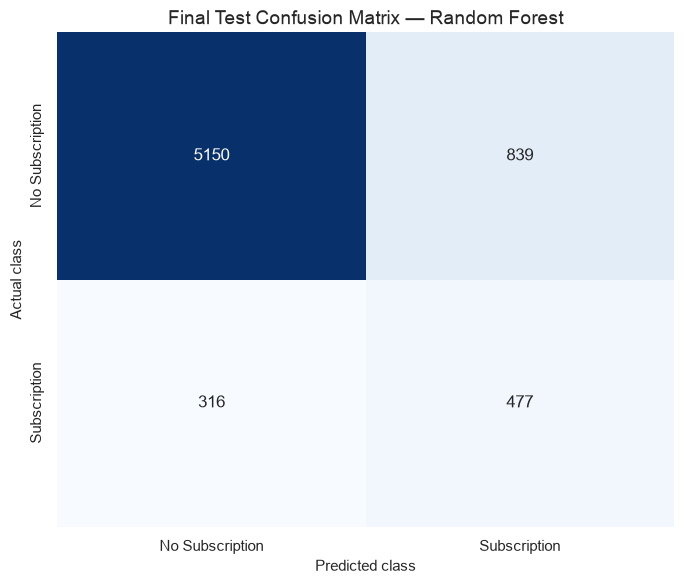

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase5/final_test_confusion_matrix.png


In [36]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(final_test_confusion_matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_display_labels, yticklabels=class_display_labels, ax=ax)
ax.set_title(f"Final Test Confusion Matrix — {selected_model_name}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
fig.tight_layout()
final_test_cm_path = PHASE5_FIGURES_DIR / "final_test_confusion_matrix.png"
fig.savefig(final_test_cm_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {final_test_cm_path}")

## Section 35: Load the Saved Pipeline and Demonstrate Inference

The saved pipeline accepts a pandas DataFrame in the original feature format. The helper below checks for required columns, drops `y` if supplied, excludes `duration` (if a caller includes it), and orders the remaining 15 model features as expected. It then applies the saved preprocessing pipeline and returns the predicted class and probability of subscription.

The example uses two held-out test feature rows and does not use their target labels to change predictions or the model. This is a small inference smoke test, not an actual bank recommendation system.

In [37]:
loaded_best_model = joblib.load(BEST_MODEL_PATH)
expected_raw_feature_columns = list(loaded_best_model.feature_names_in_)


def predict_subscription(new_customer_rows):
    # Predict a binary label and probability from raw customer features.
    if not isinstance(new_customer_rows, pd.DataFrame):
        raise TypeError("new_customer_rows must be a pandas DataFrame.")
    model_inputs = new_customer_rows.drop(columns=["y", "duration"], errors="ignore")
    missing_columns = [column for column in expected_raw_feature_columns if column not in model_inputs.columns]
    if missing_columns:
        raise ValueError(f"Missing required model input columns: {missing_columns}")
    model_inputs = model_inputs.loc[:, expected_raw_feature_columns]
    probabilities = loaded_best_model.predict_proba(model_inputs)
    positive_class_index = list(loaded_best_model.classes_).index(POSITIVE_CLASS)
    subscription_probabilities = probabilities[:, positive_class_index]
    predicted_labels = (subscription_probabilities >= CLASSIFICATION_THRESHOLD).astype(np.int64)
    return pd.DataFrame({
        "predicted_class": np.where(predicted_labels == 1, "yes", "no"),
        "subscription_probability": subscription_probabilities,
        "subscription_probability_percent": subscription_probabilities * 100,
    }, index=new_customer_rows.index)


inference_sample = df.loc[X_test.index[:2], [*expected_raw_feature_columns, "duration"]].copy()
inference_predictions = predict_subscription(inference_sample)
assert inference_sample.index.equals(inference_predictions.index)
assert set(inference_predictions["predicted_class"]).issubset({"no", "yes"})
assert np.isfinite(inference_predictions["subscription_probability"]).all()
assert inference_predictions["subscription_probability"].between(0, 1).all()
print("Inference sample input columns:", inference_sample.columns.tolist())
print("Model input columns after excluding duration:", expected_raw_feature_columns)
print("Predictions for held-out feature rows (labels were not supplied to the function):")
display(inference_predictions)
print("This example demonstrates model inference only; it is not a bank recommendation system.")

Inference sample input columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'duration']
Model input columns after excluding duration: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Predictions for held-out feature rows (labels were not supplied to the function):


,predicted_class,subscription_probability,subscription_probability_percent
8984,no,0.253328,25.332834
19279,no,0.268229,26.822874


This example demonstrates model inference only; it is not a bank recommendation system.


## PHASE 5 SUMMARY AND CONCLUSION

Phase 5 establishes a simple baseline, trains three traditional machine-learning classifiers, compares their validation performance, selects one model using validation Average Precision, and reports a single final evaluation on the held-out test set. Average Precision is emphasized because the positive subscription class is a minority; accuracy alone can hide poor detection of subscribers.

The fitted raw-input pipeline and metrics/report/figures are saved for later phases. The results estimate performance on this particular held-out dataset and do not guarantee identical results in a real campaign. Future work in Phase 6 can examine validation-based threshold selection, hyperparameter tuning, class-imbalance strategies, model interpretation, and probability calibration; additional or real-world data would also be useful. These improvements have not been applied here.

In [38]:
print("PHASE 5 SUMMARY AND CONCLUSION")
print(f"Models compared: {', '.join(validation_metrics.index.tolist())}.")
print("Baseline (DummyClassifier, prior) validation metrics:")
display(validation_metrics.loc[["DummyClassifier (prior)"], ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Average Precision (AP)"]].round(4))
print("Complete validation comparison (sorted by AP):")
display(validation_metrics.round(4))
print(f"Selected model: {selected_model_name}, chosen by validation AP = {selected_validation_row['Average Precision (AP)']:.4f}.")
print("Final held-out test metrics:")
display(test_metrics.set_index("Selected model").round(4))
print("Class imbalance matters: approximately 11.7% of examples are subscriptions; Average Precision makes the positive-class precision/recall trade-off visible.")
print("Limitations: this is a single historical dataset split; threshold is 0.50; no hyperparameter tuning, calibration, or real-world validation was performed.")
print("Next: Phase 6 hyperparameter tuning and other validation-only improvements; keep the test set untouched for final evaluation.")

PHASE 5 SUMMARY AND CONCLUSION
Models compared: Random Forest, Logistic Regression, Decision Tree, DummyClassifier (prior).
Baseline (DummyClassifier, prior) validation metrics:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP)
Model,,,,,,
DummyClassifier (prior),0.8829,0.0,0.0,0.0,0.5,0.1171


Complete validation comparison (sorted by AP):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP),Classification threshold
Model,,,,,,,
Random Forest,0.8303,0.3671,0.6209,0.4614,0.8016,0.4667,0.5
Logistic Regression,0.7566,0.2688,0.6272,0.3763,0.7720,0.4162,0.5
Decision Tree,0.7527,0.2665,0.6348,0.3754,0.7542,0.3917,0.5
DummyClassifier (prior),0.8829,0.0000,0.0000,0.0000,0.5000,0.1171,0.5


Selected model: Random Forest, chosen by validation AP = 0.4667.
Final held-out test metrics:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP),Classification threshold
Selected model,,,,,,,
Random Forest,0.8297,0.3625,0.6015,0.4523,0.7919,0.4544,0.5


Class imbalance matters: approximately 11.7% of examples are subscriptions; Average Precision makes the positive-class precision/recall trade-off visible.
Limitations: this is a single historical dataset split; threshold is 0.50; no hyperparameter tuning, calibration, or real-world validation was performed.
Next: Phase 6 hyperparameter tuning and other validation-only improvements; keep the test set untouched for final evaluation.


# PHASE 6: MODEL IMPROVEMENT AND INTERPRETATION

Phase 5 established a validation-selected Random Forest baseline. Here, we check that saved model and preprocessing, explain the fitted forest with native and permutation importance, tune a leakage-safe Random Forest pipeline using training-only cross-validation, compare it on validation data, and select a decision threshold from validation probabilities. Only after model and threshold selection do we make one Phase 6 evaluation on the existing held-out test set. The original CSV and Phase 5 result files remain unchanged.

## Section 36: Verify Saved Phase 5 Model, Splits, and Metrics

The Phase 4 splits and `random_state=42` are reused exactly. The saved Phase 5 best-model artifact must contain both the fitted preprocessor and classifier and accept the same 15 raw feature columns (`y` and post-call `duration` excluded). We recompute the Phase 5 model's validation metrics at threshold 0.50 and save them separately as the Phase 6 baseline; the earlier Phase 5 CSV remains the historical record.

In [39]:
import json
import time
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

PHASE6_RESULTS_DIR = PROJECT_ROOT / "results"
PHASE6_FIGURES_DIR = PHASE6_RESULTS_DIR / "figures" / "phase6"
PHASE6_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PHASE6_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PHASE5_MODEL_PATH = PROJECT_ROOT / "models" / "bank_marketing_best_model.joblib"

if not PHASE5_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Saved Phase 5 model was not found: {PHASE5_MODEL_PATH}")
phase5_model = joblib.load(PHASE5_MODEL_PATH)
if not isinstance(phase5_model, SklearnPipeline):
    raise TypeError("The Phase 5 best-model artifact is not a scikit-learn Pipeline.")
if not {"preprocessor", "classifier"}.issubset(phase5_model.named_steps):
    raise ValueError("The Phase 5 pipeline must contain preprocessor and classifier steps.")
if list(phase5_model.feature_names_in_) != model_feature_columns:
    raise ValueError("Saved Phase 5 pipeline feature columns do not match the Phase 4 model features.")
if "duration" in phase5_model.feature_names_in_ or "y" in phase5_model.feature_names_in_:
    raise ValueError("The Phase 5 model includes a forbidden target or post-call duration feature.")

phase5_classifier = phase5_model.named_steps["classifier"]
if not hasattr(phase5_classifier, "feature_importances_"):
    raise TypeError("The saved Phase 5 classifier does not expose native tree feature importances.")
phase5_transformed_names = phase5_model.named_steps["preprocessor"].get_feature_names_out()
if len(phase5_transformed_names) != len(phase5_classifier.feature_importances_):
    raise ValueError("Transformed feature names and Random Forest importance values do not match.")

# Check each split is disjoint and that Phase 5 transformed arrays are finite/aligned.
assert (len(X_train), len(X_val), len(X_test)) == (31647, 6782, 6782)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns) == model_feature_columns
assert X_train_transformed.shape[1] == X_val_transformed.shape[1] == X_test_transformed.shape[1] == 50
assert np.isfinite(X_train_transformed).all() and np.isfinite(X_val_transformed).all() and np.isfinite(X_test_transformed).all()
assert set(np.unique(y_train_array)) == {0, 1} and set(np.unique(y_val_array)) == {0, 1} and set(np.unique(y_test_array)) == {0, 1}

phase6_baseline_threshold = 0.50
phase5_val_probability = get_positive_class_scores(phase5_model, X_val)
phase5_val_prediction = (phase5_val_probability >= phase6_baseline_threshold).astype(np.int64)
phase6_baseline_metrics = {
    "Model": "Phase 5 Random Forest",
    "Accuracy": accuracy_score(y_val_array, phase5_val_prediction),
    "Precision": precision_score(y_val_array, phase5_val_prediction, zero_division=0),
    "Recall": recall_score(y_val_array, phase5_val_prediction, zero_division=0),
    "F1-score": f1_score(y_val_array, phase5_val_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_array, phase5_val_probability),
    "Average Precision": average_precision_score(y_val_array, phase5_val_probability),
    "Threshold": phase6_baseline_threshold,
}
phase6_baseline_metrics_df = pd.DataFrame([phase6_baseline_metrics]).set_index("Model")
phase6_baseline_metrics_path = PHASE6_RESULTS_DIR / "phase6_baseline_validation_metrics.csv"
phase6_baseline_metrics_df.to_csv(phase6_baseline_metrics_path)
print("Loaded Phase 5 pipeline:", PHASE5_MODEL_PATH)
print("Pipeline steps:", list(phase5_model.named_steps))
print("Raw model columns:", phase5_model.feature_names_in_.tolist())
print(f"Validation baseline at threshold 0.50; positive prevalence={np.mean(y_val_array):.4f}:")
display(phase6_baseline_metrics_df.round(6))
print(f"Saved Phase 6 baseline validation metrics to: {phase6_baseline_metrics_path}")

Loaded Phase 5 pipeline: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_best_model.joblib
Pipeline steps: ['preprocessor', 'classifier']
Raw model columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Validation baseline at threshold 0.50; positive prevalence=0.1171:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Threshold
Model,,,,,,,
Phase 5 Random Forest,0.830286,0.367089,0.620907,0.461394,0.801578,0.466663,0.5


Saved Phase 6 baseline validation metrics to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_baseline_validation_metrics.csv


## Section 37: Phase 5 Random Forest Feature Importance

A Random Forest's native feature importance summarizes how much its trees used a feature to reduce impurity. Because categorical variables are one-hot encoded, one original variable can appear as several transformed columns. We list transformed names separately and rank them by the saved Phase 5 forest's importance. Importance is a model-specific description, not evidence that a feature causes subscription; correlated inputs can divide or distort importance, and impurity importance can favor some feature types.

In [40]:
phase5_feature_importance = pd.DataFrame({
    "transformed_feature": phase5_transformed_names,
    "importance": phase5_classifier.feature_importances_,
})


def original_feature_from_transformed_name(transformed_name):
    # ColumnTransformer prefixes identify the numerical/categorical branch;
    # match the remaining name back to its longest original input column.
    unprefixed_name = transformed_name.split("__", maxsplit=1)[-1]
    matching_columns = [
        column for column in model_feature_columns
        if unprefixed_name == column or unprefixed_name.startswith(f"{column}_")
    ]
    return max(matching_columns, key=len) if matching_columns else unprefixed_name


phase5_feature_importance["original_feature"] = phase5_feature_importance[
    "transformed_feature"
].map(original_feature_from_transformed_name)
phase5_feature_importance = phase5_feature_importance.sort_values(
    "importance", ascending=False
).reset_index(drop=True)
phase5_feature_importance["rank"] = np.arange(1, len(phase5_feature_importance) + 1)
phase6_feature_importance_path = PHASE6_RESULTS_DIR / "phase6_feature_importance.csv"
phase5_feature_importance[["transformed_feature", "original_feature", "importance", "rank"]].to_csv(
    phase6_feature_importance_path, index=False
)
print("Top 15 transformed Phase 5 Random Forest features:")
display(phase5_feature_importance.head(15)[["rank", "original_feature", "transformed_feature", "importance"]])
print(f"Saved full native feature importance table to: {phase6_feature_importance_path}")

Top 15 transformed Phase 5 Random Forest features:


,rank,original_feature,transformed_feature,importance
0,1,balance,numerical__balance,0.100306
1,2,age,numerical__age,0.094693
2,3,poutcome,categorical__poutcome_success,0.083024
3,4,day,numerical__day,0.081095
4,5,pdays,numerical__pdays,0.060716
5,6,contact,categorical__contact_unknown,0.059511
6,7,campaign,numerical__campaign,0.045848
7,8,contact,categorical__contact_cellular,0.041087
8,9,housing,categorical__housing_yes,0.033681
9,10,housing,categorical__housing_no,0.032591


Saved full native feature importance table to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_feature_importance.csv


### Figure 15 — Top 15 Native Random Forest Feature Importances

The bars show the top 15 transformed columns by native Phase 5 Random Forest impurity importance. A high score indicates the fitted trees relied on that transformed input for impurity reductions. It is not a causal effect, and one-hot category columns should be interpreted in the context of their original field.

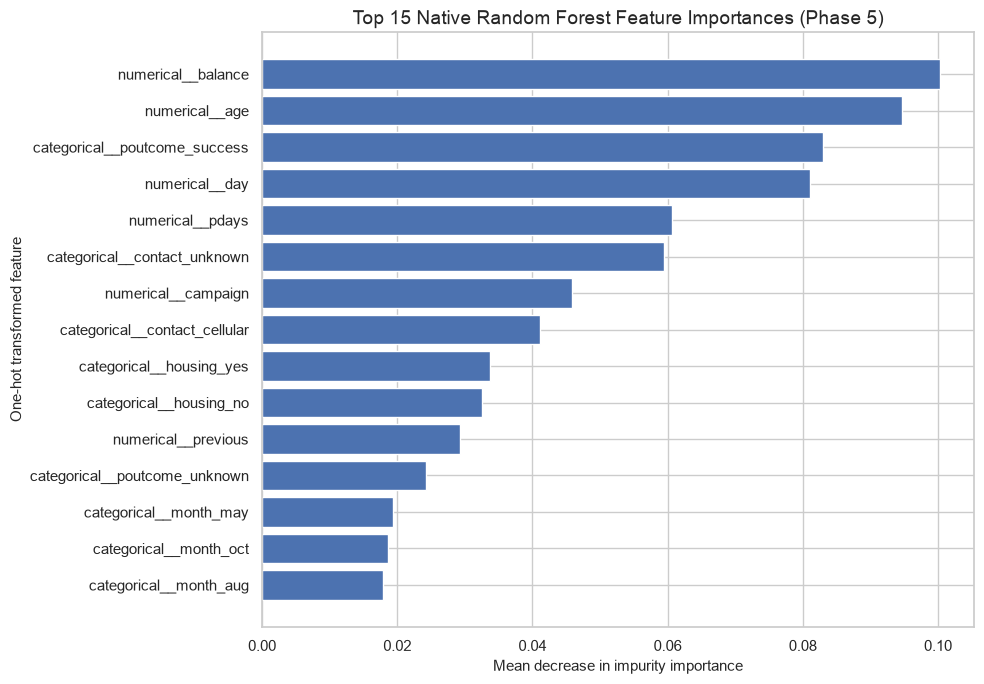

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase6/feature_importance_top15.png


In [41]:
top_native_importance = phase5_feature_importance.head(15).sort_values("importance")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_native_importance["transformed_feature"], top_native_importance["importance"], color=sns.color_palette("deep")[0])
ax.set_title("Top 15 Native Random Forest Feature Importances (Phase 5)")
ax.set_xlabel("Mean decrease in impurity importance")
ax.set_ylabel("One-hot transformed feature")
fig.tight_layout()
phase6_native_importance_plot = PHASE6_FIGURES_DIR / "feature_importance_top15.png"
fig.savefig(phase6_native_importance_plot, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase6_native_importance_plot}")

## Section 38: Permutation Importance on Validation Raw Features

Permutation importance measures how much a chosen score decreases when one original input column is shuffled. Here it evaluates the complete saved preprocessing-plus-model pipeline on the original validation DataFrame and uses Average Precision as the score. Repeating each shuffle three times gives a practical estimate of variability while limiting computation. These validation results help interpret the existing Phase 5 model; they are not used to alter the held-out test set or to tune features.

In [42]:
phase5_permutation = permutation_importance(
    phase5_model,
    X_val,
    y_val_array,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1,
)
phase6_permutation_importance = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": phase5_permutation.importances_mean,
    "importance_std": phase5_permutation.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)
phase6_permutation_importance["rank"] = np.arange(1, len(phase6_permutation_importance) + 1)
phase6_permutation_path = PHASE6_RESULTS_DIR / "phase6_permutation_importance.csv"
phase6_permutation_importance[["feature", "importance_mean", "importance_std", "rank"]].to_csv(
    phase6_permutation_path, index=False
)
print("Top 15 validation permutation importances (scoring = Average Precision):")
display(phase6_permutation_importance.head(15))
print(f"Saved complete permutation importance table to: {phase6_permutation_path}")

Top 15 validation permutation importances (scoring = Average Precision):


,feature,importance_mean,importance_std,rank
0,month,0.089870,0.002415,1
1,poutcome,0.089294,0.001424,2
2,contact,0.078284,0.006736,3
3,housing,0.040942,0.006839,4
4,pdays,0.031860,0.004588,5
5,day,0.013697,0.004678,6
6,campaign,0.012094,0.003432,7
7,balance,0.011161,0.003853,8
8,loan,0.009257,0.002381,9
9,previous,0.006514,0.002652,10


Saved complete permutation importance table to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_permutation_importance.csv


### Figure 16 — Top 15 Validation Permutation Importances

This figure ranks original input columns by the mean decrease in validation Average Precision after shuffling that column. A larger drop means the fitted pipeline's validation ranking relied more on that input in this evaluation. Negative or near-zero values can occur because of sampling variability or redundant features. The values are model- and dataset-specific, not causal.

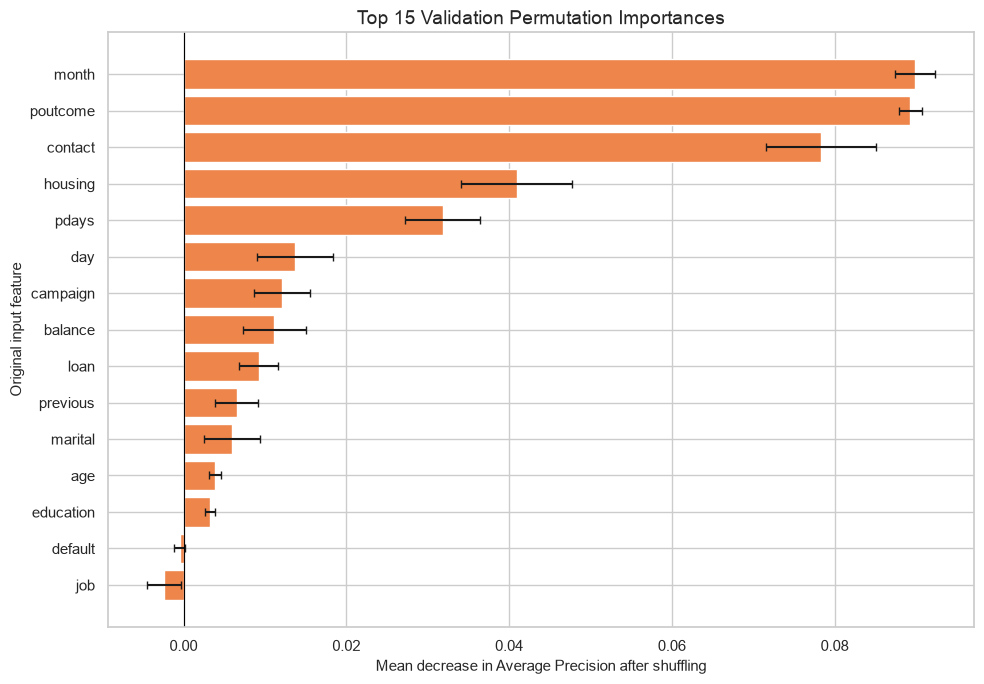

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase6/permutation_importance_top15.png


In [43]:
top_permutation_importance = phase6_permutation_importance.head(15).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    top_permutation_importance["feature"],
    top_permutation_importance["importance_mean"],
    xerr=top_permutation_importance["importance_std"],
    color=sns.color_palette("muted")[1],
    capsize=3,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Validation Permutation Importances")
ax.set_xlabel("Mean decrease in Average Precision after shuffling")
ax.set_ylabel("Original input feature")
fig.tight_layout()
phase6_permutation_plot = PHASE6_FIGURES_DIR / "permutation_importance_top15.png"
fig.savefig(phase6_permutation_plot, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase6_permutation_plot}")

## Section 39: Random Forest Hyperparameter Tuning

Hyperparameter tuning tests selected model settings and compares their cross-validation scores. We use `RandomizedSearchCV` with a compact eight-candidate search and three-fold `StratifiedKFold`, scoring by Average Precision. Cross-validation uses **only raw training rows**. A fresh clone of the Phase 4 preprocessor is part of the searched pipeline, so each fold learns its imputer, scaler, and category vocabulary only from that fold's training portion. Validation and test rows do not enter the search. The three-fold/eight-candidate design is a practical first search for a laptop, not an exhaustive optimization.

In [44]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

phase6_search_pipeline = SklearnPipeline([
    ("preprocessor", clone(phase4_preprocessor)),
    ("classifier", RandomForestClassifier(random_state=42, n_jobs=1)),
])
phase6_parameter_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 12, 18, 24],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": ["balanced", "balanced_subsample"],
}
phase6_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
phase6_search = RandomizedSearchCV(
    estimator=phase6_search_pipeline,
    param_distributions=phase6_parameter_distributions,
    n_iter=8,
    scoring="average_precision",
    cv=phase6_cv,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=False,
    error_score="raise",
)
phase6_search_start = time.perf_counter()
phase6_search.fit(X_train, y_train_array)
phase6_search_elapsed_seconds = time.perf_counter() - phase6_search_start
phase6_tuned_pipeline = phase6_search.best_estimator_

phase6_search_results = pd.DataFrame(phase6_search.cv_results_).sort_values(
    "rank_test_score"
).reset_index(drop=True)
phase6_search_results_path = PHASE6_RESULTS_DIR / "phase6_hyperparameter_search.csv"
phase6_search_results.to_csv(phase6_search_results_path, index=False)
phase6_best_parameters = {
    key.replace("classifier__", ""): (None if value is None else value)
    for key, value in phase6_search.best_params_.items()
}
phase6_best_parameters_path = PHASE6_RESULTS_DIR / "phase6_best_parameters.json"
with phase6_best_parameters_path.open("w", encoding="utf-8") as parameter_file:
    json.dump(phase6_best_parameters, parameter_file, indent=2)

phase6_tuned_model_path = PROJECT_ROOT / "models" / "bank_marketing_phase6_tuned_model.joblib"
joblib.dump(phase6_tuned_pipeline, phase6_tuned_model_path)
print(f"Best training-CV Average Precision: {phase6_search.best_score_:.6f}")
print(f"Best hyperparameters: {phase6_best_parameters}")
print(f"Parameter combinations evaluated: {len(phase6_search_results)}")
print(f"Stratified CV folds: {phase6_cv.n_splits}")
print(f"Elapsed time: {phase6_search_elapsed_seconds:.1f} seconds")
print(f"Saved search results: {phase6_search_results_path}")
print(f"Saved best parameters: {phase6_best_parameters_path}")
print(f"Saved fitted tuned pipeline: {phase6_tuned_model_path}")
display(phase6_search_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]])

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Best training-CV Average Precision: 0.430571
Best hyperparameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 24, 'class_weight': 'balanced_subsample'}
Parameter combinations evaluated: 8
Stratified CV folds: 3
Elapsed time: 19.1 seconds
Saved search results: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_hyperparameter_search.csv
Saved best parameters: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_best_parameters.json
Saved fitted tuned pipeline: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_phase6_tuned_model.joblib


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.430571,0.014290,"{'classifier__n_estimators': 300, 'classifier_..."
1,2,0.427815,0.016843,"{'classifier__n_estimators': 100, 'classifier_..."
2,3,0.427057,0.018296,"{'classifier__n_estimators': 200, 'classifier_..."
3,4,0.426368,0.017886,"{'classifier__n_estimators': 200, 'classifier_..."
4,5,0.426025,0.014036,"{'classifier__n_estimators': 100, 'classifier_..."
5,6,0.423808,0.021436,"{'classifier__n_estimators': 100, 'classifier_..."
6,7,0.422228,0.011872,"{'classifier__n_estimators': 100, 'classifier_..."
7,8,0.420949,0.016847,"{'classifier__n_estimators': 300, 'classifier_..."


## Section 40: Compare Tuned and Phase 5 Models on Validation Data

The tuned Random Forest is evaluated on validation rows at the initial 0.50 threshold. We compare its classification metrics and score-based ranking with the independently recomputed Phase 5 Random Forest baseline. Tuning improvement is claimed only if the measured validation Average Precision supports it. The Phase 5 historical metrics and outputs are not overwritten.

In [45]:
phase6_tuned_val_probability = get_positive_class_scores(phase6_tuned_pipeline, X_val)
phase6_tuned_val_prediction = (phase6_tuned_val_probability >= 0.50).astype(np.int64)
phase6_tuned_metrics = {
    "Model": "Phase 6 Tuned Random Forest",
    "Accuracy": accuracy_score(y_val_array, phase6_tuned_val_prediction),
    "Precision": precision_score(y_val_array, phase6_tuned_val_prediction, zero_division=0),
    "Recall": recall_score(y_val_array, phase6_tuned_val_prediction, zero_division=0),
    "F1-score": f1_score(y_val_array, phase6_tuned_val_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_array, phase6_tuned_val_probability),
    "Average Precision": average_precision_score(y_val_array, phase6_tuned_val_probability),
    "Threshold": 0.50,
}
phase6_tuned_metrics_df = pd.DataFrame([phase6_tuned_metrics]).set_index("Model")
phase6_model_comparison = pd.concat([phase6_baseline_metrics_df, phase6_tuned_metrics_df])
phase6_model_comparison_path = PHASE6_RESULTS_DIR / "phase6_model_comparison.csv"
phase6_model_comparison.to_csv(phase6_model_comparison_path)
print("Phase 5 baseline vs Phase 6 tuned Random Forest on validation data (threshold 0.50):")
display(phase6_model_comparison.round(6))
phase6_tuning_improved_ap = (
    phase6_tuned_metrics["Average Precision"] > phase6_baseline_metrics["Average Precision"]
)
print("Tuning improved validation Average Precision:", bool(phase6_tuning_improved_ap))
print(f"Saved comparison to: {phase6_model_comparison_path}")

Phase 5 baseline vs Phase 6 tuned Random Forest on validation data (threshold 0.50):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Threshold
Model,,,,,,,
Phase 5 Random Forest,0.830286,0.367089,0.620907,0.461394,0.801578,0.466663,0.5
Phase 6 Tuned Random Forest,0.866853,0.444331,0.547859,0.490694,0.804051,0.466343,0.5


Tuning improved validation Average Precision: False
Saved comparison to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_model_comparison.csv


### Figure 17 — Validation Comparison: Average Precision and F1-score

The grouped bars compare Average Precision (continuous score ranking) and F1-score at threshold 0.50 for the Phase 5 baseline forest and the Phase 6 tuned forest. F1 is threshold-specific; Average Precision is not changed by selecting a classification threshold.

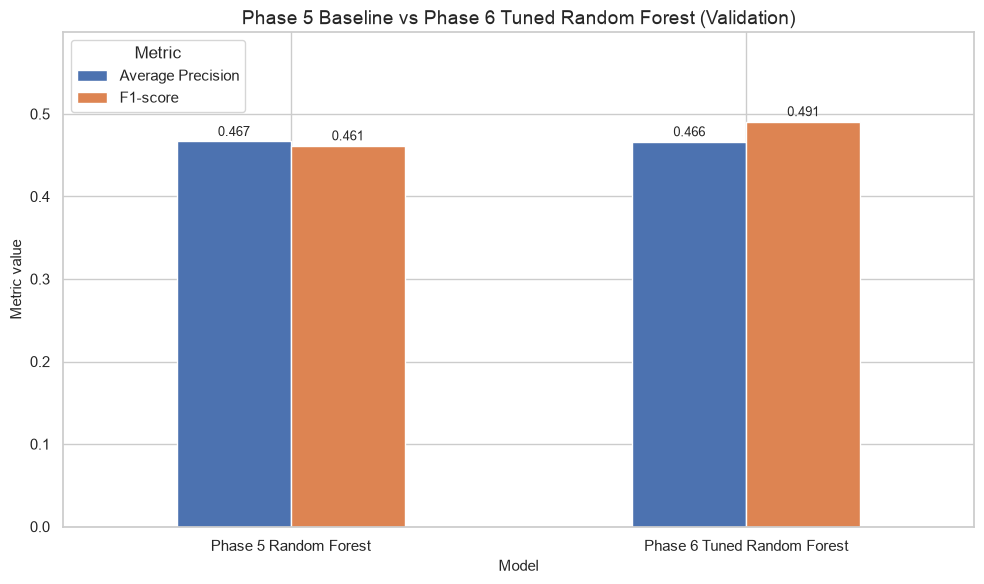

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase6/model_comparison.png


In [46]:
comparison_plot_data = phase6_model_comparison[["Average Precision", "F1-score"]]
fig, ax = plt.subplots(figsize=(10, 6))
comparison_plot_data.plot(kind="bar", ax=ax, color=[sns.color_palette("deep")[0], sns.color_palette("deep")[1]])
ax.set_title("Phase 5 Baseline vs Phase 6 Tuned Random Forest (Validation)")
ax.set_xlabel("Model")
ax.set_ylabel("Metric value")
ax.set_ylim(0, min(1.0, float(comparison_plot_data.max().max()) * 1.22))
ax.legend(title="Metric")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=9)
fig.tight_layout()
phase6_comparison_plot = PHASE6_FIGURES_DIR / "model_comparison.png"
fig.savefig(phase6_comparison_plot, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase6_comparison_plot}")

## Section 41: Select the Model and Optimize the Decision Threshold

A classification threshold turns a model probability into a class: at threshold 0.50, scores at or above 0.50 are labeled subscription. Lower thresholds often increase recall while reducing precision; higher thresholds often do the reverse. We test values from 0.10 through 0.90 in increments of 0.01 using validation predictions only.

Model choice is based on validation Average Precision between the Phase 5 forest and Phase 6 tuned forest. If the tuned forest has a higher AP it is selected; otherwise, we retain the Phase 5 forest. Then the primary threshold maximizes validation F1. For ties, select the threshold nearest 0.50, then higher precision, then the larger threshold. A separate analysis reports the best-F1 threshold among those with validation precision at least 0.40, if one exists. That precision constraint is an additional exploratory criterion, not a promised business requirement. Threshold tuning does not change probabilities, ROC-AUC, or Average Precision.

In [47]:
if phase6_tuning_improved_ap:
    phase6_selected_model_name = "Phase 6 Tuned Random Forest"
    phase6_selected_pipeline = phase6_tuned_pipeline
    phase6_selected_validation_probability = phase6_tuned_val_probability
else:
    phase6_selected_model_name = "Phase 5 Random Forest (retained)"
    phase6_selected_pipeline = phase5_model
    phase6_selected_validation_probability = phase5_val_probability

phase6_threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.901, 0.01), 2):
    predicted_at_threshold = (phase6_selected_validation_probability >= threshold).astype(np.int64)
    phase6_threshold_rows.append({
        "threshold": float(threshold),
        "precision": precision_score(y_val_array, predicted_at_threshold, zero_division=0),
        "recall": recall_score(y_val_array, predicted_at_threshold, zero_division=0),
        "f1_score": f1_score(y_val_array, predicted_at_threshold, zero_division=0),
        "accuracy": accuracy_score(y_val_array, predicted_at_threshold),
        "positive_predictions": int(predicted_at_threshold.sum()),
    })
phase6_threshold_analysis = pd.DataFrame(phase6_threshold_rows)
phase6_threshold_analysis_path = PHASE6_RESULTS_DIR / "phase6_threshold_analysis.csv"
phase6_threshold_analysis.to_csv(phase6_threshold_analysis_path, index=False)

max_validation_f1 = phase6_threshold_analysis["f1_score"].max()
primary_threshold_candidates = phase6_threshold_analysis[
    np.isclose(phase6_threshold_analysis["f1_score"], max_validation_f1)
].copy()
primary_threshold_candidates["distance_from_0_50"] = (primary_threshold_candidates["threshold"] - 0.50).abs()
phase6_primary_threshold_row = primary_threshold_candidates.sort_values(
    ["distance_from_0_50", "precision", "threshold"],
    ascending=[True, False, False],
).iloc[0]
phase6_selected_threshold = float(phase6_primary_threshold_row["threshold"])

precision_constraint_candidates = phase6_threshold_analysis[
    phase6_threshold_analysis["precision"] >= 0.40
].copy()
if precision_constraint_candidates.empty:
    phase6_precision_constrained_row = None
    phase6_precision_constrained_threshold = None
else:
    constrained_max_f1 = precision_constraint_candidates["f1_score"].max()
    constrained_candidates = precision_constraint_candidates[
        np.isclose(precision_constraint_candidates["f1_score"], constrained_max_f1)
    ].copy()
    constrained_candidates["distance_from_0_50"] = (constrained_candidates["threshold"] - 0.50).abs()
    phase6_precision_constrained_row = constrained_candidates.sort_values(
        ["distance_from_0_50", "precision", "threshold"],
        ascending=[True, False, False],
    ).iloc[0]
    phase6_precision_constrained_threshold = float(phase6_precision_constrained_row["threshold"])

phase6_selected_threshold_json = {
    "selected_model": phase6_selected_model_name,
    "primary_threshold": phase6_selected_threshold,
    "selection_metric": "validation F1-score",
    "tie_breaking": "closest to 0.50, then higher precision, then larger threshold",
    "original_threshold": 0.50,
    "precision_at_least_0_40_threshold": phase6_precision_constrained_threshold,
    "precision_constraint_met": phase6_precision_constrained_threshold is not None,
}
phase6_selected_threshold_path = PHASE6_RESULTS_DIR / "phase6_selected_threshold.json"
with phase6_selected_threshold_path.open("w", encoding="utf-8") as threshold_file:
    json.dump(phase6_selected_threshold_json, threshold_file, indent=2)
phase6_primary_predictions = (phase6_selected_validation_probability >= phase6_selected_threshold).astype(np.int64)
phase6_primary_validation_metrics = {
    "precision": precision_score(y_val_array, phase6_primary_predictions, zero_division=0),
    "recall": recall_score(y_val_array, phase6_primary_predictions, zero_division=0),
    "f1_score": f1_score(y_val_array, phase6_primary_predictions, zero_division=0),
    "accuracy": accuracy_score(y_val_array, phase6_primary_predictions),
    "positive_predictions": int(phase6_primary_predictions.sum()),
}
print(f"Selected model by validation AP: {phase6_selected_model_name}")
print("Original threshold: 0.50")
print(f"Selected F1-optimizing validation threshold: {phase6_selected_threshold:.2f}")
print(f"Validation precision: {phase6_primary_validation_metrics['precision']:.4f}")
print(f"Validation recall: {phase6_primary_validation_metrics['recall']:.4f}")
print(f"Validation F1-score: {phase6_primary_validation_metrics['f1_score']:.4f}")
print(f"Positive predictions at selected threshold: {phase6_primary_validation_metrics['positive_predictions']:,}")
if phase6_precision_constrained_row is None:
    print("No tested threshold achieved validation precision >= 0.40.")
else:
    print(
        f"Best-F1 threshold subject to precision >= 0.40: {phase6_precision_constrained_threshold:.2f}; "
        f"precision={phase6_precision_constrained_row['precision']:.4f}, "
        f"recall={phase6_precision_constrained_row['recall']:.4f}, "
        f"F1={phase6_precision_constrained_row['f1_score']:.4f}."
    )
print(f"Saved all threshold results to: {phase6_threshold_analysis_path}")
print(f"Saved selected threshold to: {phase6_selected_threshold_path}")

Selected model by validation AP: Phase 5 Random Forest (retained)
Original threshold: 0.50
Selected F1-optimizing validation threshold: 0.62
Validation precision: 0.4829
Validation recall: 0.4975
Validation F1-score: 0.4901
Positive predictions at selected threshold: 818
Best-F1 threshold subject to precision >= 0.40: 0.62; precision=0.4829, recall=0.4975, F1=0.4901.
Saved all threshold results to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_threshold_analysis.csv
Saved selected threshold to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_selected_threshold.json


### Figure 18 — Validation Precision, Recall, and F1 Across Thresholds

The chart shows how the three threshold-dependent metrics change over validation thresholds. Precision measures how many predicted subscribers actually subscribed; recall measures how many subscribers were found; F1 balances the two. The chosen point maximizes F1 under the documented tie-breaking rule. The curve is based only on validation data.

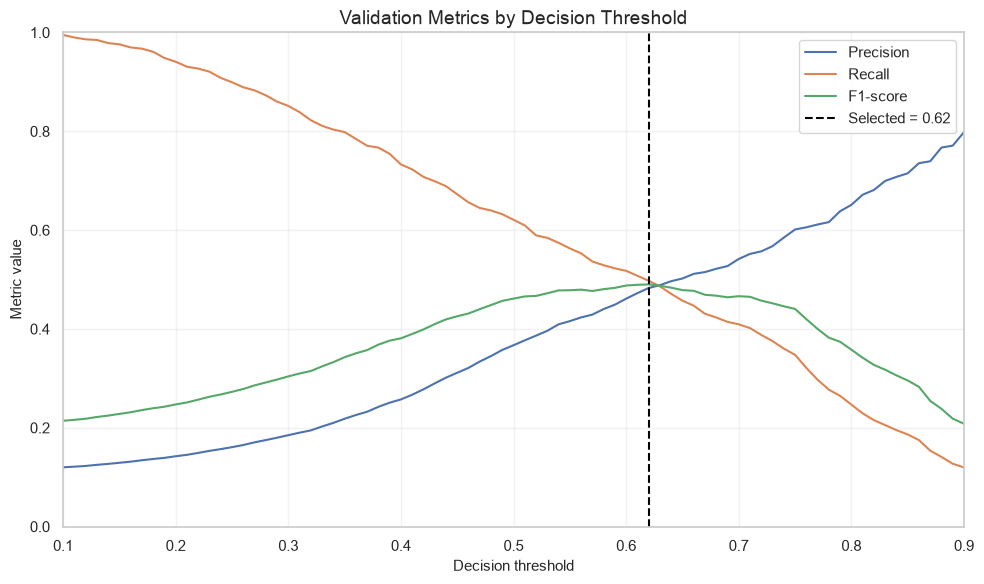

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase6/threshold_analysis.png


In [48]:
fig, ax = plt.subplots(figsize=(10, 6))
for metric_name, column_name in [("Precision", "precision"), ("Recall", "recall"), ("F1-score", "f1_score")]:
    ax.plot(phase6_threshold_analysis["threshold"], phase6_threshold_analysis[column_name], label=metric_name)
ax.axvline(phase6_selected_threshold, color="black", linestyle="--", label=f"Selected = {phase6_selected_threshold:.2f}")
ax.set_title("Validation Metrics by Decision Threshold")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Metric value")
ax.set_xlim(0.10, 0.90)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
phase6_threshold_plot = PHASE6_FIGURES_DIR / "threshold_analysis.png"
fig.savefig(phase6_threshold_plot, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase6_threshold_plot}")

## Section 42: SHAP Interpretation Availability

SHAP can explain how model features contribute to individual and overall predictions, but it is an optional dependency. It is not installed in the project's current virtual environment, and the inspected project has no dependency manifest to update. To avoid an unapproved dependency change, this notebook does not install SHAP. Native Random Forest feature importance and validation permutation importance provide the documented fallback; neither is causal. If SHAP is added to the project environment later, a TreeExplainer on a small training/validation sample can be used, with class-1 SHAP values interpreted as contributions to the model output rather than causes.

In [49]:
import importlib.util

SHAP_AVAILABLE = importlib.util.find_spec("shap") is not None
if SHAP_AVAILABLE:
    print("SHAP is installed; this notebook's optional SHAP plots may be run with a compatible TreeExplainer.")
else:
    print("SHAP is not installed. No installation was attempted; native and permutation importance are the Phase 6 interpretation outputs.")

SHAP is not installed. No installation was attempted; native and permutation importance are the Phase 6 interpretation outputs.


## Section 43: Save the Final Phase 6 Pipeline

Model selection above used validation Average Precision only. The selected threshold is separately chosen using validation F1 only. Save the selected raw-input pipeline under a Phase 6-specific name so Phase 5's model artifact remains intact. This final pipeline includes its own fitted preprocessing step and excludes both `y` and `duration`; inference must pass raw columns and must not preprocess them a second time.

In [50]:
PHASE6_BEST_MODEL_PATH = PROJECT_ROOT / "models" / "bank_marketing_best_model_phase6.joblib"
if list(phase6_selected_pipeline.feature_names_in_) != model_feature_columns:
    raise ValueError("Selected Phase 6 pipeline does not expect the Phase 4 raw model columns.")
if "duration" in phase6_selected_pipeline.feature_names_in_ or "y" in phase6_selected_pipeline.feature_names_in_:
    raise ValueError("Selected Phase 6 pipeline contains duration or target leakage.")
joblib.dump(phase6_selected_pipeline, PHASE6_BEST_MODEL_PATH)
phase6_loaded_pipeline = joblib.load(PHASE6_BEST_MODEL_PATH)
if list(phase6_loaded_pipeline.feature_names_in_) != model_feature_columns:
    raise ValueError("Reloaded Phase 6 pipeline feature names do not match expected raw input columns.")
print(f"Saved and reloaded selected Phase 6 raw-input pipeline: {PHASE6_BEST_MODEL_PATH}")
print(f"Selected model label: {phase6_selected_model_name}")
print(f"Selected threshold: {phase6_selected_threshold:.2f}")

Saved and reloaded selected Phase 6 raw-input pipeline: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_best_model_phase6.joblib
Selected model label: Phase 5 Random Forest (retained)
Selected threshold: 0.62


## Section 44: Final Phase 6 Test Evaluation

Phase 5's test metrics have already been observed, and repeated experimentation based on test results can introduce selection bias. We therefore make no further model or threshold choices from them. After selecting the Phase 6 model and threshold using validation data, evaluate the selected pipeline once on the same held-out test split. This is a new evaluation of the selected Phase 6 model, not a new independent test dataset. These test metrics are a held-out estimate and do not guarantee identical outcomes on future customers.

In [51]:
# Final test evaluation: one set of scores from the selected model, threshold fixed from validation.
phase6_test_probabilities = get_positive_class_scores(phase6_loaded_pipeline, X_test)
if not np.isfinite(phase6_test_probabilities).all() or ((phase6_test_probabilities < 0) | (phase6_test_probabilities > 1)).any():
    raise ValueError("Final Phase 6 test probabilities are non-finite or outside [0, 1].")
phase6_test_predictions = (phase6_test_probabilities >= phase6_selected_threshold).astype(np.int64)
phase6_test_metrics = pd.DataFrame([{
    "Selected model": phase6_selected_model_name,
    "Threshold selected on validation": phase6_selected_threshold,
    "Accuracy": accuracy_score(y_test_array, phase6_test_predictions),
    "Precision": precision_score(y_test_array, phase6_test_predictions, zero_division=0),
    "Recall": recall_score(y_test_array, phase6_test_predictions, zero_division=0),
    "F1-score": f1_score(y_test_array, phase6_test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_array, phase6_test_probabilities),
    "Average Precision": average_precision_score(y_test_array, phase6_test_probabilities),
}])
phase6_test_metrics_path = PHASE6_RESULTS_DIR / "phase6_test_metrics.csv"
phase6_test_metrics.to_csv(phase6_test_metrics_path, index=False)
phase6_test_confusion = confusion_matrix(y_test_array, phase6_test_predictions, labels=[0, 1])
phase6_test_report = pd.DataFrame(classification_report(
    y_test_array, phase6_test_predictions, labels=[0, 1],
    target_names=["No Subscription", "Subscription"], output_dict=True, zero_division=0,
)).transpose()
phase6_test_report_path = PHASE6_RESULTS_DIR / "phase6_classification_report.csv"
phase6_test_report.to_csv(phase6_test_report_path)

# Load Phase 5's already-recorded test result only to provide transparent historical context.
phase5_historical_test_path = PROJECT_ROOT / "results" / "phase5_test_metrics.csv"
phase5_historical_test = pd.read_csv(phase5_historical_test_path)
phase5_historical_test = phase5_historical_test.rename(columns={"Selected model": "Model"})
phase5_historical_test.insert(0, "Evaluation", "Phase 5 historical (already observed)")
phase6_test_for_comparison = phase6_test_metrics.rename(columns={
    "Selected model": "Model",
    "Threshold selected on validation": "Classification threshold",
    "Average Precision": "Average Precision (AP)",
}).copy()
phase6_test_for_comparison.insert(0, "Evaluation", "Phase 6 selected model (new evaluation on same test split)")
phase5_historical_test_for_comparison = phase5_historical_test
phase6_test_comparison = pd.concat(
    [phase5_historical_test_for_comparison, phase6_test_for_comparison],
    ignore_index=True,
    sort=False,
)
phase6_test_comparison_path = PHASE6_RESULTS_DIR / "phase6_test_comparison.csv"
phase6_test_comparison.to_csv(phase6_test_comparison_path, index=False)

print(f"Phase 6 final held-out test metrics at validation-selected threshold {phase6_selected_threshold:.2f}:")
display(phase6_test_metrics.round(6))
print("Phase 6 classification report:")
display(phase6_test_report.round(4))
print("Phase 6 test confusion matrix (rows=actual, columns=predicted):")
display(pd.DataFrame(phase6_test_confusion, index=["No Subscription", "Subscription"], columns=["No Subscription", "Subscription"]))
print("Historical Phase 5 vs Phase 6 test comparison (Phase 5 test was already observed):")
display(phase6_test_comparison.round(6))
print(f"Saved Phase 6 test metrics: {phase6_test_metrics_path}")
print(f"Saved Phase 6 classification report: {phase6_test_report_path}")
print(f"Saved Phase 5/6 test comparison: {phase6_test_comparison_path}")

Phase 6 final held-out test metrics at validation-selected threshold 0.62:


,Selected model,Threshold selected on validation,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Phase 5 Random Forest (retained),0.62,0.877027,0.47503,0.491803,0.483271,0.791923,0.454367


Phase 6 classification report:


,precision,recall,f1-score,support
No Subscription,0.9324,0.9280,0.9302,5989.000
Subscription,0.4750,0.4918,0.4833,793.000
accuracy,0.8770,0.8770,0.8770,0.877
macro avg,0.7037,0.7099,0.7067,6782.000
weighted avg,0.8789,0.8770,0.8780,6782.000


Phase 6 test confusion matrix (rows=actual, columns=predicted):


,No Subscription,Subscription
No Subscription,5558,431
Subscription,403,390


Historical Phase 5 vs Phase 6 test comparison (Phase 5 test was already observed):


,Evaluation,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision (AP),Classification threshold
0,Phase 5 historical (already observed),Random Forest,0.829696,0.362462,0.601513,0.452347,0.791923,0.454367,0.50
1,Phase 6 selected model (new evaluation on same...,Phase 5 Random Forest (retained),0.877027,0.475030,0.491803,0.483271,0.791923,0.454367,0.62


Saved Phase 6 test metrics: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_test_metrics.csv
Saved Phase 6 classification report: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_classification_report.csv
Saved Phase 5/6 test comparison: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase6_test_comparison.csv


### Figure 19 — Final Phase 6 Test Confusion Matrix

This matrix shows the Phase 6 selected pipeline's final test predictions at the threshold chosen from validation data. It is an evaluation summary only; its results do not feed back into model, feature, or threshold selection.

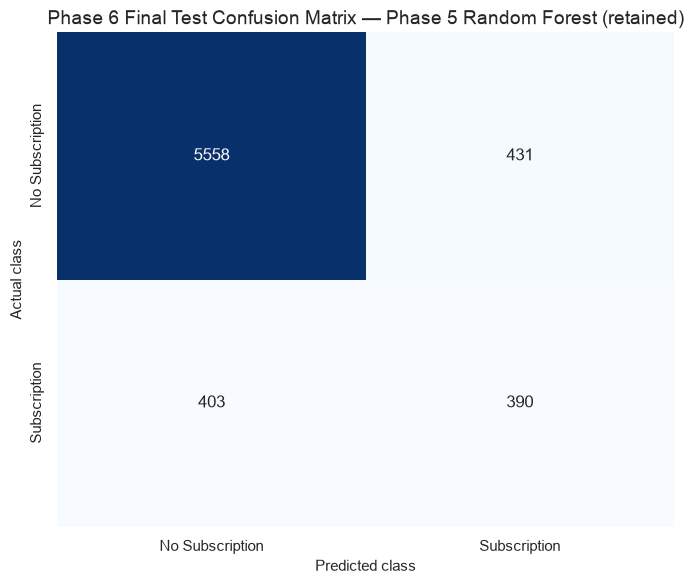

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/figures/phase6/final_test_confusion_matrix.png


In [52]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(phase6_test_confusion, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No Subscription", "Subscription"],
            yticklabels=["No Subscription", "Subscription"], ax=ax)
ax.set_title(f"Phase 6 Final Test Confusion Matrix — {phase6_selected_model_name}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
fig.tight_layout()
phase6_test_cm_path = PHASE6_FIGURES_DIR / "final_test_confusion_matrix.png"
fig.savefig(phase6_test_cm_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase6_test_cm_path}")

## Section 45: Raw-Feature Prediction Example

The loaded Phase 6 pipeline performs preprocessing automatically. The helper accepts original raw feature columns, drops `y` and `duration` if present, checks and orders the expected 15 model inputs, and applies the validation-selected threshold. Two feature rows from the held-out test set demonstrate inference without consulting their target labels. Predicted probabilities are model estimates and are not guaranteed to be perfectly calibrated.

In [53]:
loaded_phase6_model = joblib.load(PHASE6_BEST_MODEL_PATH)
phase6_expected_features = list(loaded_phase6_model.feature_names_in_)

def predict_with_phase6_model(raw_customer_features):
    if not isinstance(raw_customer_features, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame of raw features.")
    raw_model_inputs = raw_customer_features.drop(columns=["y", "duration"], errors="ignore")
    missing_expected = [column for column in phase6_expected_features if column not in raw_model_inputs.columns]
    if missing_expected:
        raise ValueError(f"Missing expected raw feature columns: {missing_expected}")
    raw_model_inputs = raw_model_inputs.loc[:, phase6_expected_features]
    probabilities = loaded_phase6_model.predict_proba(raw_model_inputs)
    positive_index = list(loaded_phase6_model.classes_).index(1)
    subscription_probability = probabilities[:, positive_index]
    predicted_binary = (subscription_probability >= phase6_selected_threshold).astype(np.int64)
    if not np.isfinite(subscription_probability).all() or ((subscription_probability < 0) | (subscription_probability > 1)).any():
        raise ValueError("Inference returned invalid subscription probabilities.")
    if not set(np.unique(predicted_binary)).issubset({0, 1}):
        raise ValueError("Inference returned a non-binary predicted label.")
    return pd.DataFrame({
        "predicted_binary_label": predicted_binary,
        "predicted_class": np.where(predicted_binary == 1, "yes", "no"),
        "subscription_probability": subscription_probability,
        "subscription_probability_percent": subscription_probability * 100,
        "threshold": phase6_selected_threshold,
    }, index=raw_customer_features.index)

phase6_inference_examples = df.loc[X_test.index[:2], [*phase6_expected_features, "duration"]].copy()
phase6_inference_predictions = predict_with_phase6_model(phase6_inference_examples)
assert phase6_inference_examples.index.equals(phase6_inference_predictions.index)
assert "duration" not in phase6_expected_features and "y" not in phase6_expected_features
print("Expected raw model features:", phase6_expected_features)
print("Input demonstration includes duration but helper excludes it; no target labels are passed.")
display(phase6_inference_predictions)
print("Predicted probabilities are model estimates, not guaranteed perfectly calibrated probabilities.")

Expected raw model features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Input demonstration includes duration but helper excludes it; no target labels are passed.


,predicted_binary_label,predicted_class,subscription_probability,subscription_probability_percent,threshold
8984,0,no,0.253328,25.332834,0.62
19279,0,no,0.268229,26.822874,0.62


Predicted probabilities are model estimates, not guaranteed perfectly calibrated probabilities.


## PHASE 6 SUMMARY AND CONCLUSION

This phase uses training-only cross-validation to tune a Random Forest within a pipeline that refits preprocessing separately inside each fold. Validation Average Precision selects between the original Phase 5 forest and the tuned forest; validation F1 selects the decision threshold. The held-out test set is evaluated once after these choices, but the Phase 5 test result was already observed in the prior phase, so repeated comparisons on it carry selection-bias risk.

Native impurity importance and permutation importance describe model behavior, not causation. SHAP is unavailable in the current environment, so interpretation uses those two methods. The results are an educational experiment, not a production-ready bank decision system. Future work could include a broader but controlled hyperparameter search, validation-based cost-sensitive threshold criteria, calibration, robustness checks, and evaluation on additional or real-world data.

In [54]:
print("PHASE 6 SUMMARY AND CONCLUSION")
print(f"Phase 5 baseline validation AP: {phase6_baseline_metrics['Average Precision']:.6f}")
print(f"Phase 6 tuned validation AP: {phase6_tuned_metrics['Average Precision']:.6f}")
print(f"Tuning changed validation AP by {phase6_tuned_metrics['Average Precision'] - phase6_baseline_metrics['Average Precision']:+.6f}; improved: {bool(phase6_tuning_improved_ap)}")
print(f"Selected model: {phase6_selected_model_name}")
print("Top native Phase 5 transformed features:")
display(phase5_feature_importance.head(15)[["rank", "transformed_feature", "importance"]])
print("Top validation permutation features:")
display(phase6_permutation_importance.head(10)[["rank", "feature", "importance_mean", "importance_std"]])
print(f"Best CV Average Precision: {phase6_search.best_score_:.6f}; hyperparameters: {phase6_best_parameters}")
print(f"Selected validation threshold: {phase6_selected_threshold:.2f}; precision={phase6_primary_validation_metrics['precision']:.4f}, recall={phase6_primary_validation_metrics['recall']:.4f}, F1={phase6_primary_validation_metrics['f1_score']:.4f}")
print("SHAP available:", SHAP_AVAILABLE)
print("Final Phase 6 test metrics:")
display(phase6_test_metrics.round(6))
print("The Phase 5 test results are historical and already observed; the new Phase 6 test run uses the same holdout and is not independent.")
print("This remains an educational prediction experiment. Threshold, probability calibration, distribution shift, and external validation remain limitations.")

PHASE 6 SUMMARY AND CONCLUSION
Phase 5 baseline validation AP: 0.466663
Phase 6 tuned validation AP: 0.466343
Tuning changed validation AP by -0.000320; improved: False
Selected model: Phase 5 Random Forest (retained)
Top native Phase 5 transformed features:


,rank,transformed_feature,importance
0,1,numerical__balance,0.100306
1,2,numerical__age,0.094693
2,3,categorical__poutcome_success,0.083024
3,4,numerical__day,0.081095
4,5,numerical__pdays,0.060716
5,6,categorical__contact_unknown,0.059511
6,7,numerical__campaign,0.045848
7,8,categorical__contact_cellular,0.041087
8,9,categorical__housing_yes,0.033681
9,10,categorical__housing_no,0.032591


Top validation permutation features:


,rank,feature,importance_mean,importance_std
0,1,month,0.089870,0.002415
1,2,poutcome,0.089294,0.001424
2,3,contact,0.078284,0.006736
3,4,housing,0.040942,0.006839
4,5,pdays,0.031860,0.004588
5,6,day,0.013697,0.004678
6,7,campaign,0.012094,0.003432
7,8,balance,0.011161,0.003853
8,9,loan,0.009257,0.002381
9,10,previous,0.006514,0.002652


Best CV Average Precision: 0.430571; hyperparameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 24, 'class_weight': 'balanced_subsample'}
Selected validation threshold: 0.62; precision=0.4829, recall=0.4975, F1=0.4901
SHAP available: False
Final Phase 6 test metrics:


,Selected model,Threshold selected on validation,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Phase 5 Random Forest (retained),0.62,0.877027,0.47503,0.491803,0.483271,0.791923,0.454367


The Phase 5 test results are historical and already observed; the new Phase 6 test run uses the same holdout and is not independent.
This remains an educational prediction experiment. Threshold, probability calibration, distribution shift, and external validation remain limitations.


# Phase 7: Business Insights, Explainability, and Responsible Use

This phase translates the completed EDA and model results into cautious, practical observations. It uses the selected Phase 6 pipeline and threshold, which were selected using validation data. It does not tune from the test set or present associations as causes. Prediction examples pass feature columns only and do not reveal their held-out test labels.

## 7.1 Category-Level Subscription Patterns

The tables calculate each category's subscription rate as positive cases divided by all records in that category. Counts are included so high rates from small groups can be recognized. These are historical observational patterns, not causal effects or guarantees for future campaigns.

In [55]:
PHASE7_RESULTS_DIR = PROJECT_ROOT / "results" / "phase7"
PHASE7_FIGURES_DIR = PHASE7_RESULTS_DIR / "figures"
PHASE7_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PHASE7_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

phase7_category_features = ["job", "education", "marital", "housing", "loan", "poutcome", "contact", "month"]
phase7_category_rows = []
for feature in phase7_category_features:
    if feature not in df.columns:
        raise KeyError(f"Required category feature is absent: {feature}")
    grouped = df.groupby(feature, dropna=False, observed=True)["y"].agg(
        total_count="size",
        positive_count=lambda values: (values == "yes").sum(),
    )
    grouped["subscription_rate"] = grouped["positive_count"] / grouped["total_count"]
    grouped["subscription_rate_percent"] = grouped["subscription_rate"] * 100
    for category, row in grouped.iterrows():
        phase7_category_rows.append({
            "feature": feature, "category": str(category),
            "total_count": int(row["total_count"]), "positive_count": int(row["positive_count"]),
            "subscription_rate": float(row["subscription_rate"]),
            "subscription_rate_percent": float(row["subscription_rate_percent"]),
        })
phase7_category_rates = pd.DataFrame(phase7_category_rows)
phase7_category_rates_path = PHASE7_RESULTS_DIR / "category_subscription_rates.csv"
phase7_category_rates.to_csv(phase7_category_rates_path, index=False)
display(phase7_category_rates.sort_values(["feature", "subscription_rate"], ascending=[True, False]))
print(f"Saved category counts and rates to: {phase7_category_rates_path}")

,feature,category,total_count,positive_count,subscription_rate,subscription_rate_percent
27,contact,cellular,29285,4369,0.149189,14.918900
28,contact,telephone,2906,390,0.134205,13.420509
29,contact,unknown,13020,530,0.040707,4.070661
14,education,tertiary,13301,1996,0.150064,15.006390
15,education,unknown,1857,252,0.135703,13.570275
13,education,secondary,23202,2450,0.105594,10.559435
12,education,primary,6851,591,0.086265,8.626478
19,housing,no,20081,3354,0.167024,16.702355
20,housing,yes,25130,1935,0.077000,7.699960
8,job,student,938,269,0.286780,28.678038


Saved category counts and rates to: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/category_subscription_rates.csv


### Figure 20 — Observed Subscription Rates Across Selected Categories

This five-panel chart compares subscription rates for job, education, contact, month, and previous-campaign outcome categories. It makes differences visible while annotating each bar with its group size. Read rates alongside counts: small groups are less stable, and contact-history or timing patterns may reflect campaign selection rather than a category effect.

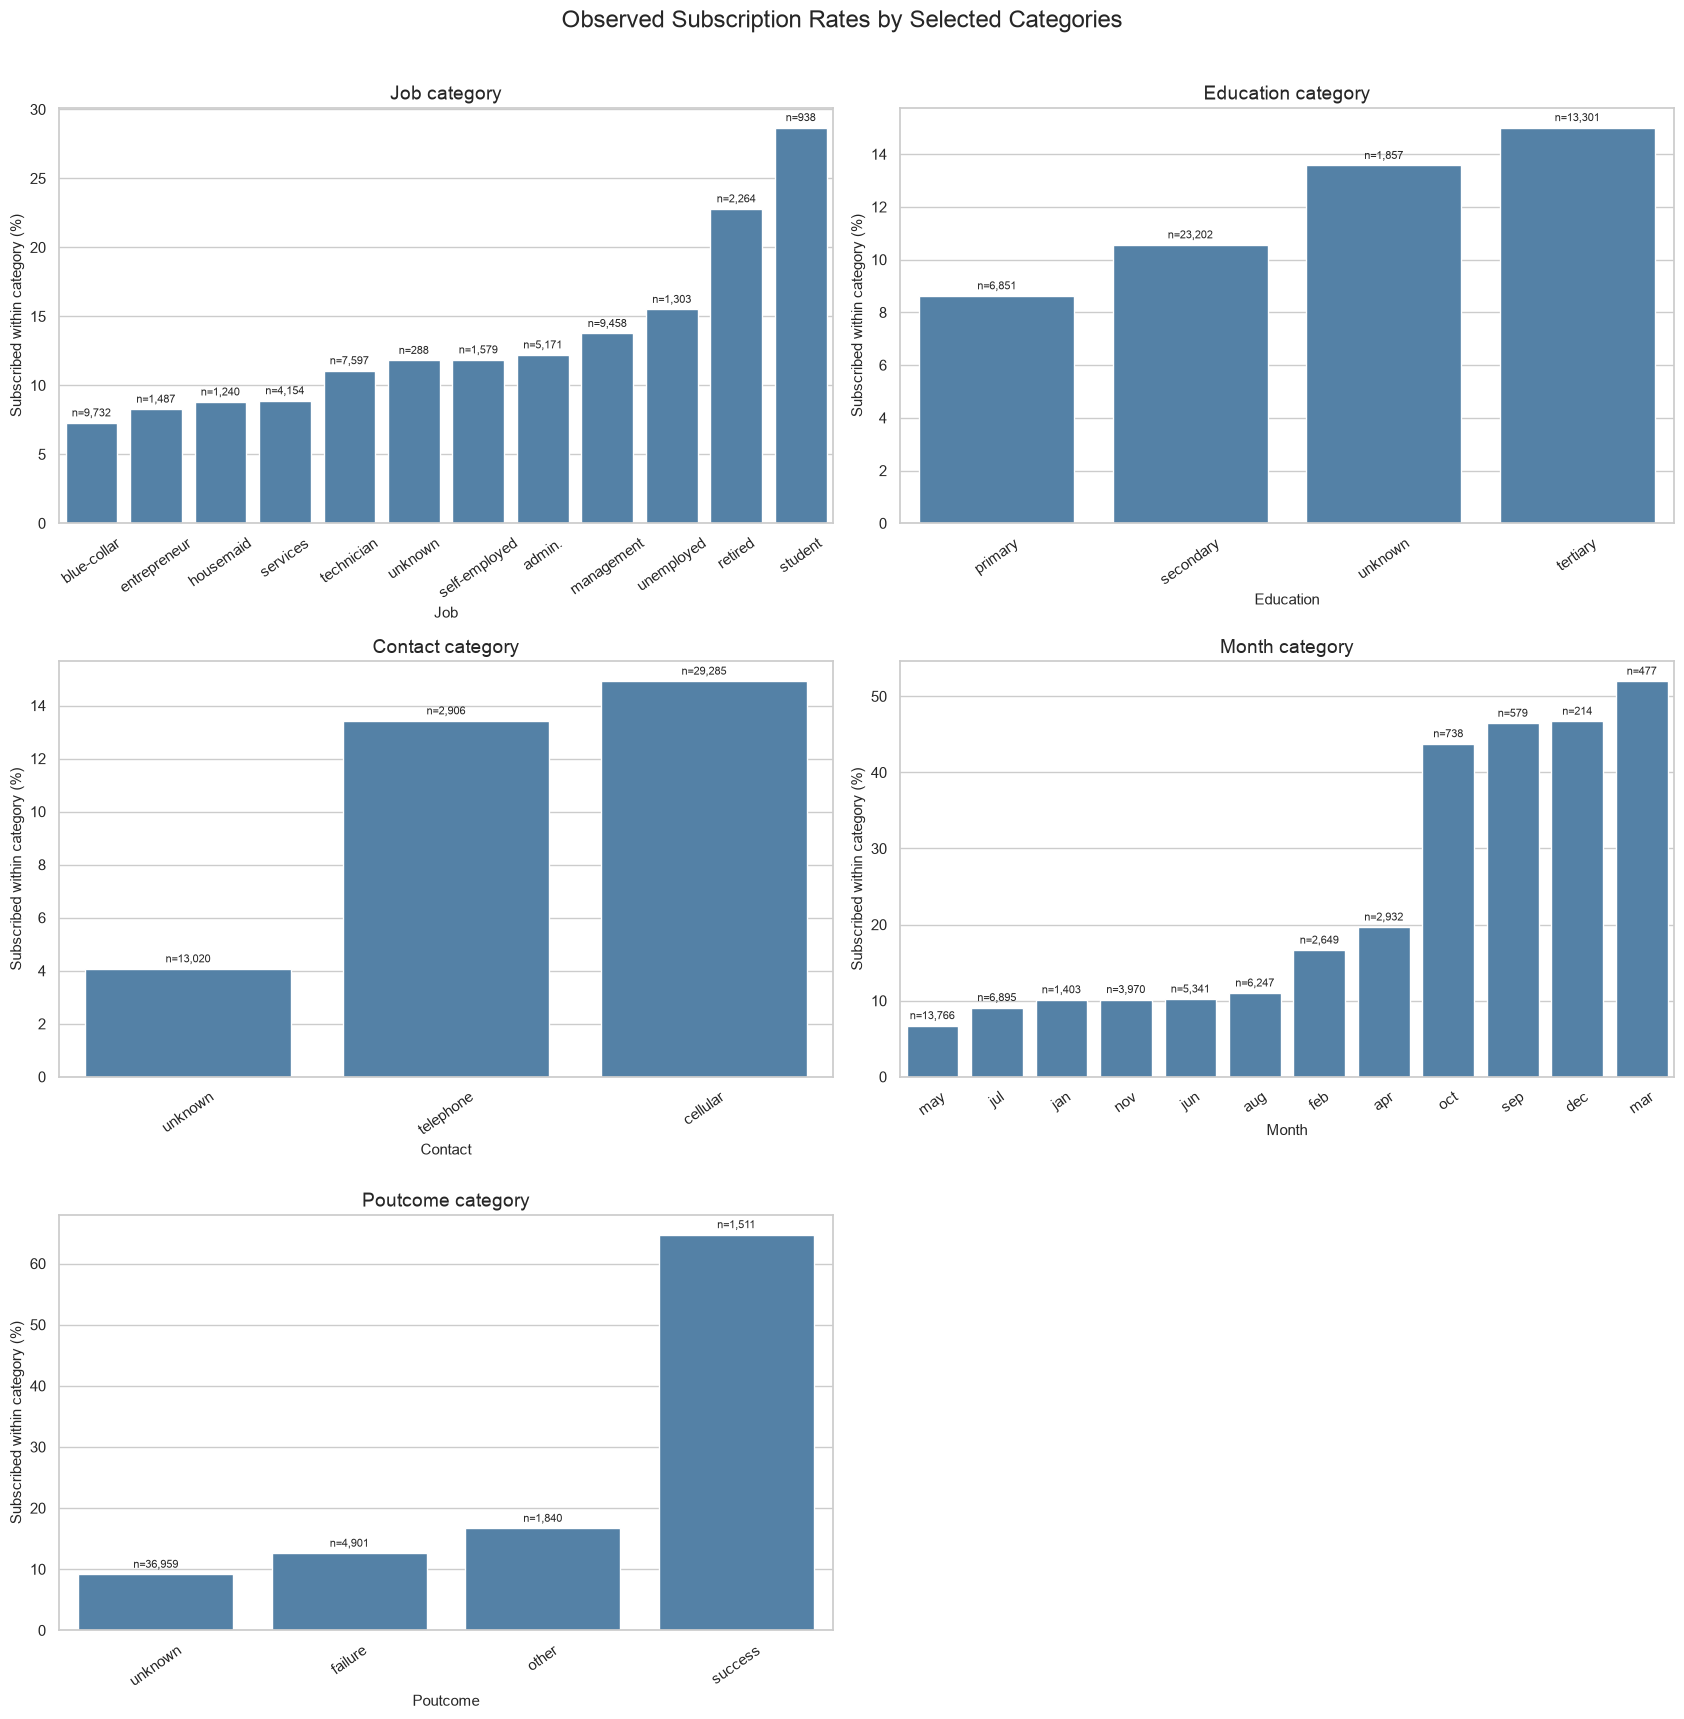

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/figures/category_subscription_patterns.png


In [56]:
phase7_plot_features = ["job", "education", "contact", "month", "poutcome"]
fig, axes = plt.subplots(3, 2, figsize=(17, 17))
for ax, feature in zip(axes.flat, phase7_plot_features):
    feature_rates = phase7_category_rates.loc[phase7_category_rates["feature"] == feature].sort_values("subscription_rate")
    sns.barplot(data=feature_rates, x="category", y="subscription_rate_percent", color="steelblue", ax=ax)
    ax.set_title(f"{feature.title()} category")
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Subscribed within category (%)")
    ax.tick_params(axis="x", rotation=35)
    for patch, (_, row) in zip(ax.patches, feature_rates.iterrows()):
        ax.annotate(f"n={int(row['total_count']):,}", (patch.get_x()+patch.get_width()/2, patch.get_height()),
                    ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
axes.flat[-1].axis("off")
fig.suptitle("Observed Subscription Rates by Selected Categories", fontsize=17, y=1.01)
fig.tight_layout()
phase7_category_plot_path = PHASE7_FIGURES_DIR / "category_subscription_patterns.png"
fig.savefig(phase7_category_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase7_category_plot_path}")

## 7.2 Model Explainability: Native and Permutation Importance

Native Random Forest importance is summed across one-hot transformed columns to compare original input features. Permutation importance measures the change in validation Average Precision after shuffling one raw feature. These methods answer different questions and may disagree. Neither shows a causal effect or the direction of a feature's effect on probability. SHAP was unavailable in the inspected environment, so it is not claimed here.

,feature,native_importance,permutation_importance_mean,native_rank,permutation_rank
11,month,0.153163,0.089870,1,1
13,poutcome,0.120608,0.089294,2,2
3,contact,0.106016,0.078284,3,3
7,housing,0.066272,0.040942,7,4
12,pdays,0.060716,0.031860,8,5
4,day,0.081095,0.013697,6,6
2,campaign,0.045848,0.012094,10,7
1,balance,0.100306,0.011161,4,8
9,loan,0.021479,0.009257,14,9
14,previous,0.029245,0.006514,12,10


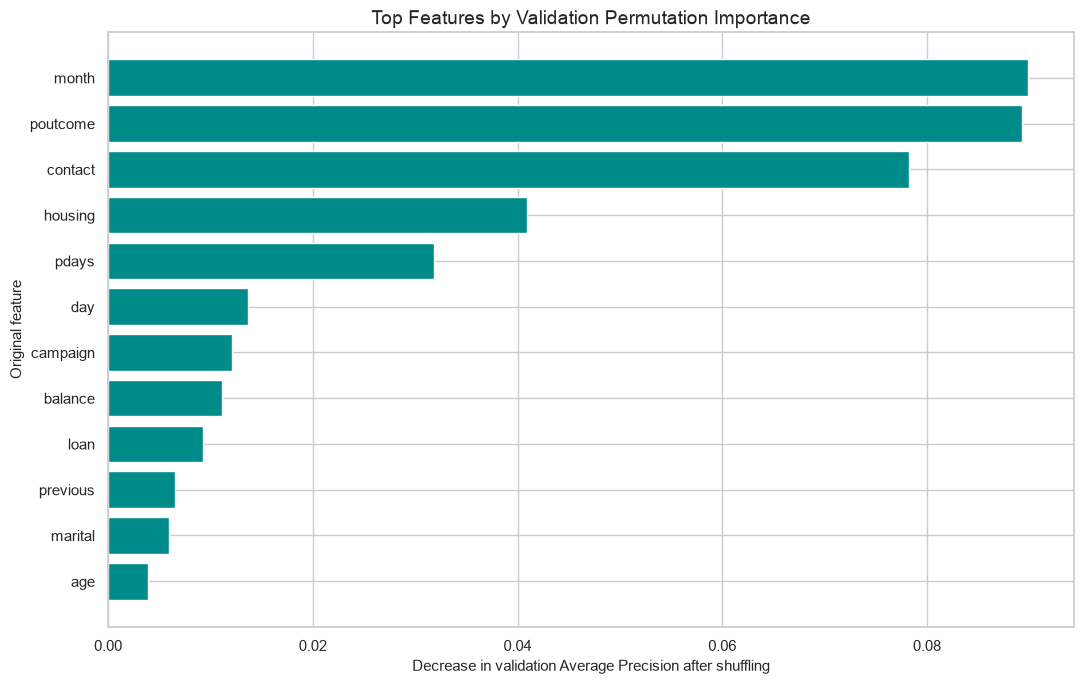

Saved importance comparison: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/aggregated_feature_importance_comparison.csv
Saved figure: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/figures/feature_importance_comparison.png


In [57]:
phase7_native_raw = pd.read_csv(PROJECT_ROOT / "results" / "phase6_feature_importance.csv")
phase7_permutation_raw = pd.read_csv(PROJECT_ROOT / "results" / "phase6_permutation_importance.csv")
if not {"original_feature", "importance"}.issubset(phase7_native_raw.columns):
    raise ValueError("Phase 6 native importance CSV is missing expected columns.")
if not {"feature", "importance_mean"}.issubset(phase7_permutation_raw.columns):
    raise ValueError("Phase 6 permutation importance CSV is missing expected columns.")
phase7_native_by_feature = (phase7_native_raw.groupby("original_feature", as_index=False)["importance"]
    .sum().rename(columns={"original_feature":"feature", "importance":"native_importance"}))
phase7_importance_comparison = phase7_native_by_feature.merge(
    phase7_permutation_raw[["feature", "importance_mean"]].rename(columns={"importance_mean":"permutation_importance_mean"}),
    on="feature", how="outer", validate="one_to_one").fillna(0)
phase7_importance_comparison["native_rank"] = phase7_importance_comparison["native_importance"].rank(ascending=False, method="min").astype(int)
phase7_importance_comparison["permutation_rank"] = phase7_importance_comparison["permutation_importance_mean"].rank(ascending=False, method="min").astype(int)
phase7_importance_comparison = phase7_importance_comparison.sort_values("permutation_rank")
phase7_importance_path = PHASE7_RESULTS_DIR / "aggregated_feature_importance_comparison.csv"
phase7_importance_comparison.to_csv(phase7_importance_path, index=False)
display(phase7_importance_comparison)
phase7_top_importance = phase7_importance_comparison.head(12).sort_values("permutation_importance_mean")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(phase7_top_importance["feature"], phase7_top_importance["permutation_importance_mean"], color="darkcyan")
ax.set_title("Top Features by Validation Permutation Importance")
ax.set_xlabel("Decrease in validation Average Precision after shuffling")
ax.set_ylabel("Original feature")
fig.tight_layout()
phase7_importance_plot_path = PHASE7_FIGURES_DIR / "feature_importance_comparison.png"
fig.savefig(phase7_importance_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved importance comparison: {phase7_importance_path}")
print(f"Saved figure: {phase7_importance_plot_path}")

## 7.3 Individual Prediction Demonstrations

These three examples use raw input columns from held-out test records. Their actual target labels are never selected, joined, printed, or used. The table reports probability and predicted class at 0.50 and the validation-selected threshold of 0.62. Probabilities are model estimates and are not guaranteed to be calibrated; these are demonstrations, not customer-level recommendations.

In [58]:
phase7_example_features = X_test.iloc[:3].copy()
if len(phase7_example_features) != 3:
    raise ValueError("Three test examples are required for the inference demonstration.")
phase7_example_probabilities = get_positive_class_scores(phase6_loaded_pipeline, phase7_example_features)
phase7_prediction_examples = pd.DataFrame([{
    "example": f"Example {number}", "subscription_probability": float(probability),
    "probability_percent": float(probability * 100),
    "class_at_0.50": "yes" if probability >= 0.50 else "no",
    "class_at_0.62": "yes" if probability >= 0.62 else "no",
} for number, probability in enumerate(phase7_example_probabilities, start=1)])
phase7_prediction_path = PHASE7_RESULTS_DIR / "three_feature_only_prediction_examples.csv"
phase7_prediction_examples.to_csv(phase7_prediction_path, index=False)
display(phase7_prediction_examples.round(4))
print("Only X_test feature rows were passed to the model; y_test labels were not used or displayed.")
print(f"Saved: {phase7_prediction_path}")

,example,subscription_probability,probability_percent,class_at_0.50,class_at_0.62
0,Example 1,0.2533,25.3328,no,no
1,Example 2,0.2682,26.8229,no,no
2,Example 3,0.3923,39.2325,no,no


Only X_test feature rows were passed to the model; y_test labels were not used or displayed.
Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/three_feature_only_prediction_examples.csv


## 7.4 Validation Probabilities and Threshold Trade-Offs

The following predicted-positive counts and classification trade-offs use validation data only at thresholds 0.50 and 0.62. A higher threshold can reduce the number flagged positive at the cost of recall. These sample-specific results do not encode real outreach costs, capacity, consent, or calibration. The test set remains untouched for threshold decisions.

,threshold,predicted_positive_count,true_positive_count,false_positive_count,false_negative_count,true_negative_count,precision,recall,f1_score
0,0.50,1343,493,850,301,5138,0.3671,0.6209,0.4614
1,0.62,818,395,423,399,5565,0.4829,0.4975,0.4901


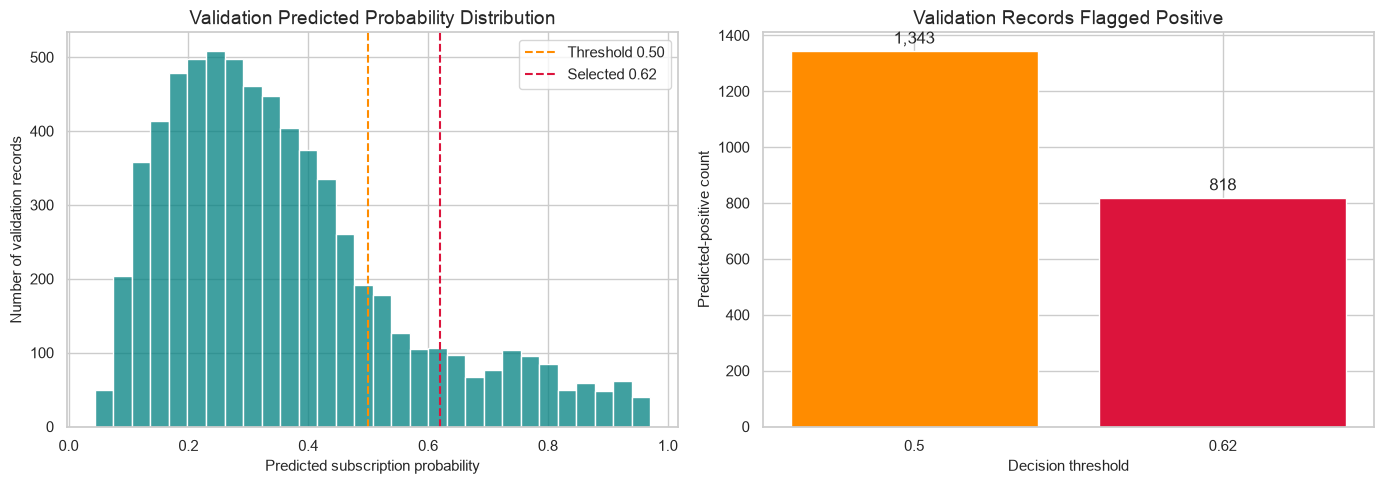

Saved validation-only data and figure: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/validation_probability_summary.csv, /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/figures/validation_probability_thresholds.png


In [59]:
phase7_validation_probabilities = get_positive_class_scores(phase6_loaded_pipeline, X_val)
if not np.isfinite(phase7_validation_probabilities).all():
    raise ValueError("Validation probabilities contain non-finite values.")
phase7_thresholds = [0.50, float(phase6_selected_threshold)]
phase7_validation_threshold_rows = []
phase7_confusion_matrices = {}
for threshold in phase7_thresholds:
    predictions = (phase7_validation_probabilities >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_val_array, predictions, labels=[0, 1]).ravel()
    phase7_confusion_matrices[threshold] = np.array([[tn, fp], [fn, tp]])
    phase7_validation_threshold_rows.append({
        "threshold": threshold, "predicted_positive_count": int(predictions.sum()),
        "true_positive_count": int(tp), "false_positive_count": int(fp),
        "false_negative_count": int(fn), "true_negative_count": int(tn),
        "precision": float(precision_score(y_val_array, predictions, zero_division=0)),
        "recall": float(recall_score(y_val_array, predictions, zero_division=0)),
        "f1_score": float(f1_score(y_val_array, predictions, zero_division=0)),
    })
phase7_validation_threshold_summary = pd.DataFrame(phase7_validation_threshold_rows)
phase7_validation_threshold_path = PHASE7_RESULTS_DIR / "validation_threshold_tradeoffs.csv"
phase7_validation_threshold_summary.to_csv(phase7_validation_threshold_path, index=False)
display(phase7_validation_threshold_summary.round(4))
phase7_probability_summary_path = PHASE7_RESULTS_DIR / "validation_probability_summary.csv"
pd.DataFrame({"subscription_probability":phase7_validation_probabilities}).to_csv(phase7_probability_summary_path, index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(phase7_validation_probabilities, bins=30, ax=axes[0], color="teal")
axes[0].axvline(0.50, color="darkorange", linestyle="--", label="Threshold 0.50")
axes[0].axvline(phase6_selected_threshold, color="crimson", linestyle="--", label=f"Selected {phase6_selected_threshold:.2f}")
axes[0].set(title="Validation Predicted Probability Distribution", xlabel="Predicted subscription probability", ylabel="Number of validation records")
axes[0].legend()
axes[1].bar(phase7_validation_threshold_summary["threshold"].astype(str), phase7_validation_threshold_summary["predicted_positive_count"], color=["darkorange", "crimson"])
axes[1].set(title="Validation Records Flagged Positive", xlabel="Decision threshold", ylabel="Predicted-positive count")
for bar, count in zip(axes[1].patches, phase7_validation_threshold_summary["predicted_positive_count"]):
    axes[1].annotate(f"{int(count):,}", (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
fig.tight_layout()
phase7_validation_plot_path = PHASE7_FIGURES_DIR / "validation_probability_thresholds.png"
fig.savefig(phase7_validation_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved validation-only data and figure: {phase7_probability_summary_path}, {phase7_validation_plot_path}")

### Figure 21 — Validation Threshold Confusion Matrices

The matrices show validation true/false positive and negative counts at 0.50 and 0.62. False positives can spend outreach effort on people who did not subscribe in this historical sample; false negatives miss historical subscribers. Real costs are not in the dataset, so neither threshold is universally best. These validation results explain trade-offs, not independent performance.

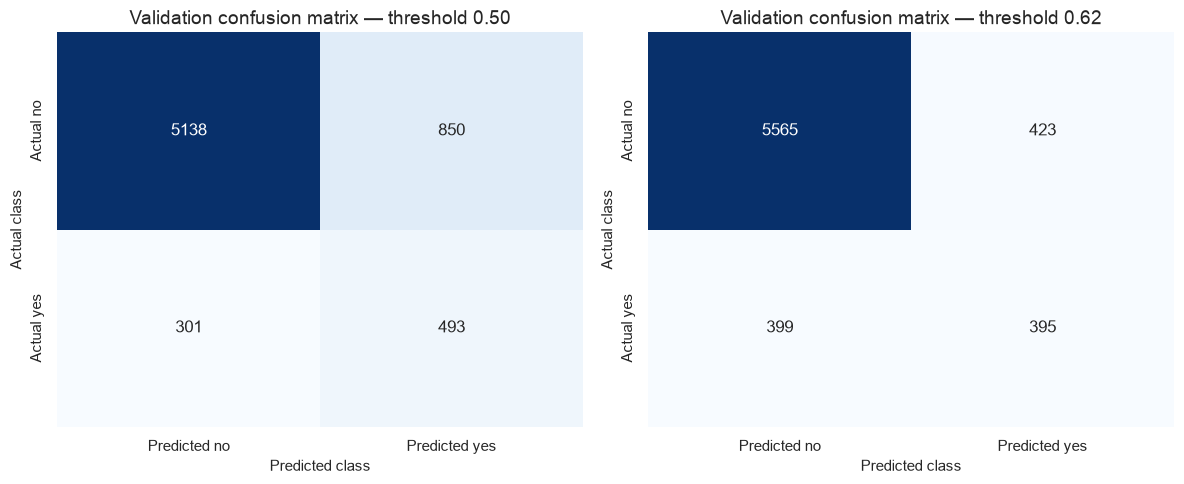

Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/figures/validation_confusion_threshold_comparison.png


In [60]:
fig, axes = plt.subplots(1, len(phase7_thresholds), figsize=(12, 5))
for ax, threshold in zip(np.atleast_1d(axes), phase7_thresholds):
    sns.heatmap(phase7_confusion_matrices[threshold], annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Predicted no", "Predicted yes"], yticklabels=["Actual no", "Actual yes"], ax=ax)
    ax.set_title(f"Validation confusion matrix — threshold {threshold:.2f}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
fig.tight_layout()
phase7_confusion_plot_path = PHASE7_FIGURES_DIR / "validation_confusion_threshold_comparison.png"
fig.savefig(phase7_confusion_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {phase7_confusion_plot_path}")

## 7.5 Cautious Business Recommendations

These are hypotheses for controlled, consent-aware testing—not instructions to deny service, exclude groups, or assume a category causes subscription. Any campaign should comply with applicable privacy, consumer-protection, and marketing-contact rules.

In [61]:
phase7_recommendations = pd.DataFrame([
    {"recommendation":"Test tailored, voluntary messaging with contact-history segments, especially previous successful campaign outcomes.","caveat":"This subgroup is comparatively small and may reflect prior campaign selection."},
    {"recommendation":"Evaluate contact channel and timing in a randomized, consent-aware pilot.","caveat":"Observed differences can reflect seasonality, channel availability, and selection."},
    {"recommendation":"Review housing- and loan-related message relevance without denying access or service based on debt status.","caveat":"Historical rates are observational and do not establish customer need or a causal effect."},
    {"recommendation":"Monitor contact frequency and provide clear opt-out safeguards; test whether additional attempts are worthwhile.","caveat":"High-contact groups are uneven and sparse; repeated contact may burden customers."},
    {"recommendation":"Use model scores only as a human-reviewed prioritization aid after calibration, fairness, privacy, and drift checks.","caveat":"This is an educational experiment and is not validated for deployment."},
    {"recommendation":"Compare interventions against randomized controls and track incremental outcomes and costs.","caveat":"EDA associations and predictive metrics do not show causal impact or profit."},
])
phase7_recommendations_path = PHASE7_RESULTS_DIR / "cautious_business_recommendations.csv"
phase7_recommendations.to_csv(phase7_recommendations_path, index=False)
display(phase7_recommendations)
print(f"Saved: {phase7_recommendations_path}")

,recommendation,caveat
0,"Test tailored, voluntary messaging with contac...",This subgroup is comparatively small and may r...
1,Evaluate contact channel and timing in a rando...,"Observed differences can reflect seasonality, ..."
2,Review housing- and loan-related message relev...,Historical rates are observational and do not ...
3,Monitor contact frequency and provide clear op...,High-contact groups are uneven and sparse; rep...
4,Use model scores only as a human-reviewed prio...,This is an educational experiment and is not v...
5,Compare interventions against randomized contr...,EDA associations and predictive metrics do not...


Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/cautious_business_recommendations.csv


## 7.6 Limitations, Responsible Use, and Interpretation

- This is historical data from a specific institution, period, and campaign context; future patterns may differ.
- Category rates, correlations, and feature importance are observational and do not prove causation.
- The target is imbalanced; accuracy alone can obscure minority-class performance.
- Predicted probabilities may be miscalibrated. The 0.62 threshold was chosen by validation criteria, not known campaign economics.
- Phase 5 test results were already observed; Phase 6 reused that same holdout. Repeated comparisons are not independent and risk selection bias.
- Duration is excluded because it is known only after the call; using it for pre-call targeting would leak post-contact information.
- Age, job, marital status, and financial fields can be sensitive or proxies. Do not use scores for eligibility, pricing, denial, or other consequential decisions without appropriate legal and fairness review.
- The data lacks costs, consent, contact preferences, profitability, and causal campaign outcomes.
- Individual examples are demonstrations with hidden labels, not recommendations about actual people.

## 7.7 Seven-Phase Project Summary

In [62]:
phase7_project_summary = pd.DataFrame([
    {"phase":1,"title":"Initial data loading and EDA","summary":"Loaded bank-full.csv and documented schema, target, data quality, and initial plots."},
    {"phase":2,"title":"Data quality and preprocessing preparation","summary":"Reviewed unknown categories, outliers, category patterns, and leakage-aware preprocessing plans."},
    {"phase":3,"title":"Advanced EDA and visualization","summary":"Added correlation, age and campaign-contact analysis, and the seven visualization stages."},
    {"phase":4,"title":"Feature engineering and preprocessing","summary":"Encoded target, excluded duration, split stratified data, and fitted training-only preprocessing."},
    {"phase":5,"title":"Baseline model experiments","summary":"Compared dummy, logistic regression, decision tree, and random forest baselines."},
    {"phase":6,"title":"Model tuning and evaluation","summary":"Tuned Random Forest with training-only CV, selected model and threshold on validation, and evaluated the reused test holdout."},
    {"phase":7,"title":"Business insights and responsible interpretation","summary":"Compared category rates and feature importance, demonstrated feature-only predictions, and documented limitations and cautious recommendations."},
])
phase7_project_summary_path = PHASE7_RESULTS_DIR / "seven_phase_project_summary.csv"
phase7_project_summary.to_csv(phase7_project_summary_path, index=False)
display(phase7_project_summary)
print(f"Saved: {phase7_project_summary_path}")

,phase,title,summary
0,1,Initial data loading and EDA,"Loaded bank-full.csv and documented schema, ta..."
1,2,Data quality and preprocessing preparation,"Reviewed unknown categories, outliers, categor..."
2,3,Advanced EDA and visualization,"Added correlation, age and campaign-contact an..."
3,4,Feature engineering and preprocessing,"Encoded target, excluded duration, split strat..."
4,5,Baseline model experiments,"Compared dummy, logistic regression, decision ..."
5,6,Model tuning and evaluation,"Tuned Random Forest with training-only CV, sel..."
6,7,Business insights and responsible interpretation,Compared category rates and feature importance...


Saved: /Users/dhananjaymandal/EDA-Bank-Marketing/results/phase7/seven_phase_project_summary.csv


## Phase 7 Conclusion

The completed project demonstrates how EDA, validation-based model selection, feature interpretation, and threshold comparisons can inform cautious hypotheses. Findings are specific to this historical dataset and do not establish causal impact, guaranteed response, calibrated probability, fairness, or business value. Real use would require consent-aware experimentation, cost-sensitive evaluation, independent external validation, privacy and fairness review, and ongoing monitoring.

In [63]:
# Generate project documentation from the computed notebook values.
phase7_yes_count = int((df["y"] == "yes").sum())
phase7_no_count = int((df["y"] == "no").sum())
phase7_top_native = phase7_importance_comparison.sort_values("native_importance", ascending=False).head(3)["feature"].tolist()
phase7_top_permutation = phase7_importance_comparison.sort_values("permutation_importance_mean", ascending=False).head(3)["feature"].tolist()
phase7_report_lines = [
    "# Bank Marketing EDA and Subscription Prediction — Phase 7 Summary", "",
    "## Project overview",
    "This student project explores the UCI Bank Marketing dataset, performs EDA and preprocessing, compares baseline models, tunes a Random Forest, and discusses cautious business implications. The target records whether a client subscribed to a term deposit.", "",
    "## Verified data",
    f"- Dataset: data/bank/bank-full.csv (semicolon-delimited).",
    f"- Shape: {len(df):,} rows x {len(df.columns)} columns; 16 input features and target y.",
    f"- Target: yes = {phase7_yes_count:,} ({phase7_yes_count/len(df):.2%}); no = {phase7_no_count:,} ({phase7_no_count/len(df):.2%}).",
    "- Earlier checks found no conventional missing values or exact duplicates; unknown category values were retained.",
    "- pdays = -1 means the customer had not previously been contacted.", "",
    "## Modeling workflow",
    "- Phase 4 used stratified 70/15/15 train/validation/test splits and 15 primary features; duration was excluded because it is known only after a call.",
    "- Categorical features were one-hot encoded, numerical features scaled, and preprocessing was fitted on training data only.",
    "- Phase 5 compared Dummy, Logistic Regression, Decision Tree, and Random Forest baselines. Phase 6 tuning did not improve validation Average Precision, so the Phase 5 Random Forest was retained.",
    f"- Selected threshold: {phase6_selected_threshold:.2f}, chosen on validation. Phase 6 reused the already-observed Phase 5 test holdout; it is not independent.", "",
    "## Phase 7 findings",
    f"- Top aggregated native importance features: {', '.join(phase7_top_native)}.",
    f"- Top validation permutation importance features: {', '.join(phase7_top_permutation)}.",
    "- The methods measure different properties; neither proves causation or effect direction.",
    "- Category rates include denominators; validation threshold analysis uses validation data only.",
    "- Three held-out inference examples use feature rows only; their labels are not shown or used.", "",
    "## Limitations and responsible use",
    "Results are observational, historical, campaign-specific, and subject to target imbalance and distribution shift. Probabilities may be miscalibrated, and the selected threshold does not encode real campaign costs. The reused test holdout is not independent. Duration is excluded to prevent post-contact leakage. Some demographic and financial fields can be sensitive or proxy variables. This is an educational experiment, not a production decision system.", "",
    "## Generated deliverables",
    "- Category rates: results/phase7/category_subscription_rates.csv",
    "- Importance comparison: results/phase7/aggregated_feature_importance_comparison.csv",
    "- Validation threshold trade-offs: results/phase7/validation_threshold_tradeoffs.csv",
    "- Feature-only prediction examples: results/phase7/three_feature_only_prediction_examples.csv",
    "- Seven-phase summary: results/phase7/seven_phase_project_summary.csv",
    "- Figures: results/phase7/figures/"
]
phase7_report_path = PROJECT_ROOT / "PHASE7_PROJECT_SUMMARY.md"
phase7_report_path.write_text("\n".join(phase7_report_lines) + "\n", encoding="utf-8")
print(f"Wrote documentation from computed values: {phase7_report_path}")
print("Validation threshold trade-offs:")
display(phase7_validation_threshold_summary.round(4))

Wrote documentation from computed values: /Users/dhananjaymandal/EDA-Bank-Marketing/PHASE7_PROJECT_SUMMARY.md
Validation threshold trade-offs:


,threshold,predicted_positive_count,true_positive_count,false_positive_count,false_negative_count,true_negative_count,precision,recall,f1_score
0,0.50,1343,493,850,301,5138,0.3671,0.6209,0.4614
1,0.62,818,395,423,399,5565,0.4829,0.4975,0.4901


### Computed findings added to the Phase 7 documentation

The notebook computes category-rate examples, threshold trade-offs, and selected-model test metrics directly from the loaded data and saved Phase 6 evaluation. These examples make the project summary evidence-based; all category patterns remain observational.

In [64]:
def phase7_rate_line(feature, category):
    selected = phase7_category_rates.loc[
        (phase7_category_rates["feature"] == feature) &
        (phase7_category_rates["category"] == category)
    ]
    if selected.empty:
        raise ValueError(f"Missing expected category result for {feature}={category}.")
    row = selected.iloc[0]
    return f"- {feature} = {category}: {int(row['positive_count']):,}/{int(row['total_count']):,} subscribed ({row['subscription_rate_percent']:.2f}%)."

phase7_threshold_050 = phase7_validation_threshold_summary.loc[phase7_validation_threshold_summary["threshold"] == 0.50].iloc[0]
phase7_threshold_selected = phase7_validation_threshold_summary.loc[
    np.isclose(phase7_validation_threshold_summary["threshold"], phase6_selected_threshold)
].iloc[0]
phase7_test_result = phase6_test_metrics.iloc[0]
phase7_report_supplement = [
    "",
    "## Computed category and model findings",
    "The following observed rates are calculated from the loaded dataset:",
    phase7_rate_line("job", "student"),
    phase7_rate_line("job", "retired"),
    phase7_rate_line("housing", "no"),
    phase7_rate_line("housing", "yes"),
    phase7_rate_line("loan", "no"),
    phase7_rate_line("loan", "yes"),
    phase7_rate_line("poutcome", "success"),
    f"- On validation, threshold 0.50 flagged {int(phase7_threshold_050['predicted_positive_count']):,} records positive (precision {phase7_threshold_050['precision']:.2%}, recall {phase7_threshold_050['recall']:.2%}).",
    f"- On validation, selected threshold {phase6_selected_threshold:.2f} flagged {int(phase7_threshold_selected['predicted_positive_count']):,} records positive (precision {phase7_threshold_selected['precision']:.2%}, recall {phase7_threshold_selected['recall']:.2%}).",
    f"- Phase 6 selected-model result on the reused test holdout at threshold {phase6_selected_threshold:.2f}: precision {phase7_test_result['Precision']:.2%}, recall {phase7_test_result['Recall']:.2%}, F1 {phase7_test_result['F1-score']:.4f}, Average Precision {phase7_test_result['Average Precision']:.4f}.",
    "- The high poutcome=success rate represents prior campaign history and a limited subgroup; it should not be interpreted as a causal lift.",
    "",
    "## Practical follow-up",
    "1. Run randomized, consent-aware pilots to test messaging and timing; compare incremental outcomes rather than raw historical rates.",
    "2. Use category rates as hypotheses only, retaining counts and uncertainty checks for small groups.",
    "3. Protect customers with frequency caps and opt-out handling; do not infer that repeated contact is beneficial from sparse groups.",
    "4. Do not use demographic or financial inputs for eligibility, denial, pricing, or other consequential decisions without legal and fairness review.",
    "5. Before operational use, evaluate calibration, fairness, distribution shift, external validity, privacy, and campaign economics."
]
phase7_report_path.write_text(phase7_report_path.read_text(encoding="utf-8") + "\n".join(phase7_report_supplement) + "\n", encoding="utf-8")
print("Computed Phase 7 findings:")
for line in phase7_report_supplement:
    if line.startswith("- "):
        print(line)
print(f"Updated project report: {phase7_report_path}")

Computed Phase 7 findings:
- job = student: 269/938 subscribed (28.68%).
- job = retired: 516/2,264 subscribed (22.79%).
- housing = no: 3,354/20,081 subscribed (16.70%).
- housing = yes: 1,935/25,130 subscribed (7.70%).
- loan = no: 4,805/37,967 subscribed (12.66%).
- loan = yes: 484/7,244 subscribed (6.68%).
- poutcome = success: 978/1,511 subscribed (64.73%).
- On validation, threshold 0.50 flagged 1,343 records positive (precision 36.71%, recall 62.09%).
- On validation, selected threshold 0.62 flagged 818 records positive (precision 48.29%, recall 49.75%).
- Phase 6 selected-model result on the reused test holdout at threshold 0.62: precision 47.50%, recall 49.18%, F1 0.4833, Average Precision 0.4544.
- The high poutcome=success rate represents prior campaign history and a limited subgroup; it should not be interpreted as a causal lift.
Updated project report: /Users/dhananjaymandal/EDA-Bank-Marketing/PHASE7_PROJECT_SUMMARY.md


## PHASE 8: DEEP LEARNING USING MULTILAYER PERCEPTRON (MLP)

### 8.1 Phase 8 Objectives
This section adds a simple neural network to the existing bank-marketing project. The goal is to satisfy the deep-learning requirement while preserving the earlier EDA, preprocessing, and Random Forest work already completed in this notebook.

### 8.2 Dataset and Preprocessing Verification
The original dataset is still loaded from `data/bank/bank-full.csv` and the existing stratified train/validation/test split is reused. The target column is kept as `y`, and the `duration` field remains excluded because it is only known after a call and could leak information if used before subscription decisions.

### 8.3 MLP Model Architecture
An MLP (Multilayer Perceptron) is a feed-forward neural network made of layers of neurons. Each hidden layer transforms the input data and learns nonlinear patterns. ReLU means the model keeps positive values and sets negative values to zero, making it easy to train and useful for tabular data such as this bank dataset. Because the target is imbalanced, the training procedure uses sample weights to increase the influence of the positive class without changing the natural class distribution in validation or test data.

### 8.4 Hyperparameter Tuning
A small validation-only search compares a few MLP architectures, regularization strengths, and learning rates. Average precision is used as the primary metric because the positive class is rare.

### 8.5 Training and Validation Learning Curves
The learning curves below show the training loss and the training/validation accuracy over repeated epochs. The diagnostic curve is created with a warm-start training loop and is kept separate from the final selected model configuration.

### 8.6 Validation Evaluation
The selected MLP is evaluated on the validation set with a 0.50 decision threshold. Metrics include accuracy, precision, recall, F1-score, ROC-AUC, average precision, and the confusion matrix.

### 8.7 Final Test Evaluation
After fixing the architecture and hyperparameters, the final model is evaluated once on the existing test set. The test set is not used for tuning or model selection.

### 8.8 Random Forest vs MLP Comparison
The existing Random Forest remains the benchmark. Validation metrics are used for model comparison and selection. The final test comparison is kept descriptive and is not used to revise the model.

### 8.9 MLP Feature Analysis
Permutation importance is calculated on the validation set. This measures how much average precision changes when a feature is randomly shuffled, which helps indicate model reliance without implying causation.

### 8.10 Limitations
The MLP is useful as a baseline deep-learning model for tabular data, but it does not automatically outperform tree-based models. In this dataset, MLP is benchmarked fairly against the existing Random Forest and the comparison is honest.

### 8.11 Phase 8 Conclusion
The objective is to add a beginner-friendly MLP while preserving the earlier work. The notebook saves a new Phase 8 model and figures without overwriting the original project artifacts.


In [65]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=ConvergenceWarning)

PROJECT_ROOT = globals().get("PROJECT_ROOT", Path.cwd().resolve())
if "find_project_root" in globals():
    PROJECT_ROOT = find_project_root(Path.cwd())
DATA_PATH = PROJECT_ROOT / "data" / "bank" / "bank-full.csv"
PHASE8_RESULTS_DIR = PROJECT_ROOT / "results" / "phase8"
PHASE8_FIGURES_DIR = PROJECT_ROOT / "results" / "figures" / "phase8"
PHASE8_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PHASE8_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

raw_df = pd.read_csv(DATA_PATH, sep=';')
model_feature_columns = [
    "age", "job", "marital", "education", "default", "balance", "housing", "loan",
    "contact", "day", "month", "campaign", "pdays", "previous", "poutcome",
]
X = raw_df[model_feature_columns].copy()
y = raw_df["y"].astype(str)

X_train, X_remaining, y_train, y_remaining = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining, y_remaining, test_size=0.5, stratify=y_remaining, random_state=42
)

preprocessor = joblib.load(PROJECT_ROOT / "models" / "bank_marketing_preprocessor.joblib")
X_train_transformed = preprocessor.transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

train_sample_weight = np.ones(len(y_train), dtype=float)
class_counts = y_train.value_counts()
positive_weight = class_counts.max() / class_counts.min()
train_sample_weight[y_train.eq("yes")] = positive_weight

train_binary = (y_train == "yes").astype(int)
val_binary = (y_val == "yes").astype(int)
test_binary = (y_test == "yes").astype(int)


def compute_metrics(y_true, probs):
    pred = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1_score": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probs),
        "average_precision": average_precision_score(y_true, probs),
    }

param_grid = [
    {"hidden_layer_sizes": (32,), "alpha": 1e-4, "learning_rate_init": 1e-3, "max_iter": 300},
    {"hidden_layer_sizes": (64, 32), "alpha": 1e-4, "learning_rate_init": 1e-3, "max_iter": 300},
    {"hidden_layer_sizes": (32,), "alpha": 1e-3, "learning_rate_init": 1e-3, "max_iter": 300},
    {"hidden_layer_sizes": (64, 32), "alpha": 1e-3, "learning_rate_init": 5e-4, "max_iter": 500},
    {"hidden_layer_sizes": (64, 32), "alpha": 5e-4, "learning_rate_init": 1e-3, "max_iter": 500},
    {"hidden_layer_sizes": (32, 16), "alpha": 1e-4, "learning_rate_init": 5e-4, "max_iter": 400},
]

hyperparameter_rows = []
for params in param_grid:
    model = MLPClassifier(
        hidden_layer_sizes=params["hidden_layer_sizes"],
        activation="relu",
        solver="adam",
        alpha=params["alpha"],
        learning_rate_init=params["learning_rate_init"],
        max_iter=params["max_iter"],
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
    )
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        model.fit(X_train_transformed, y_train, sample_weight=train_sample_weight)
    pos_index = list(model.classes_).index("yes")
    val_prob = model.predict_proba(X_val_transformed)[:, pos_index]
    val_pred = (val_prob >= 0.5).astype(int)
    hyperparameter_rows.append({
        "hidden_layer_sizes": str(params["hidden_layer_sizes"]),
        "alpha": params["alpha"],
        "learning_rate_init": params["learning_rate_init"],
        "max_iter": params["max_iter"],
        "accuracy": accuracy_score(val_binary, val_pred),
        "precision": precision_score(val_binary, val_pred, zero_division=0),
        "recall": recall_score(val_binary, val_pred, zero_division=0),
        "f1_score": f1_score(val_binary, val_pred, zero_division=0),
        "roc_auc": roc_auc_score(val_binary, val_prob),
        "average_precision": average_precision_score(val_binary, val_prob),
        "convergence_warning": bool(caught_warnings),
        "warning_count": len(caught_warnings),
        "warning_messages": " | ".join(str(w.message) for w in caught_warnings),
        "iterations_completed": len(model.loss_curve_),
    })

hyperparameter_df = pd.DataFrame(hyperparameter_rows).sort_values("average_precision", ascending=False).reset_index(drop=True)
hyperparameter_df.to_csv(PHASE8_RESULTS_DIR / "mlp_hyperparameter_results.csv", index=False)
selected = {
    "hidden_layer_sizes": tuple(eval(hyperparameter_df.loc[0, "hidden_layer_sizes"])),
    "alpha": float(hyperparameter_df.loc[0, "alpha"]),
    "learning_rate_init": float(hyperparameter_df.loc[0, "learning_rate_init"]),
    "max_iter": int(hyperparameter_df.loc[0, "max_iter"]),
}

history_model = MLPClassifier(
    hidden_layer_sizes=selected["hidden_layer_sizes"],
    activation="relu",
    solver="adam",
    alpha=selected["alpha"],
    learning_rate_init=selected["learning_rate_init"],
    max_iter=1,
    warm_start=True,
    random_state=42,
    early_stopping=False,
)
history_rows = []
for epoch in range(1, 81):
    history_model.fit(X_train_transformed, y_train, sample_weight=train_sample_weight)
    train_pred = history_model.predict(X_train_transformed)
    val_pred = history_model.predict(X_val_transformed)
    history_rows.append({
        "epoch": epoch,
        "loss": float(history_model.loss_),
        "train_accuracy": float(accuracy_score(train_binary, (train_pred == "yes").astype(int))),
        "validation_accuracy": float(accuracy_score(val_binary, (val_pred == "yes").astype(int))),
    })
training_history = pd.DataFrame(history_rows)
training_history.to_csv(PHASE8_RESULTS_DIR / "mlp_training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(training_history["epoch"], training_history["loss"], color="tab:blue", linewidth=2)
axes[0].set_title("MLP Training Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.25)
axes[1].plot(training_history["epoch"], training_history["train_accuracy"], label="Training accuracy", color="tab:green", linewidth=2)
axes[1].plot(training_history["epoch"], training_history["validation_accuracy"], label="Validation accuracy", color="tab:orange", linewidth=2)
axes[1].set_title("MLP Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.25)
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_training_loss.png", dpi=200); plt.close(fig)

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(training_history["epoch"], training_history["train_accuracy"], label="Training accuracy", color="tab:green", linewidth=2)
ax2.plot(training_history["epoch"], training_history["validation_accuracy"], label="Validation accuracy", color="tab:orange", linewidth=2)
ax2.set_title("MLP Accuracy vs Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend(); ax2.grid(True, alpha=0.25)
fig2.tight_layout(); fig2.savefig(PHASE8_FIGURES_DIR / "mlp_training_accuracy.png", dpi=200); plt.close(fig2)

final_model = MLPClassifier(
    hidden_layer_sizes=selected["hidden_layer_sizes"],
    activation="relu",
    solver="adam",
    alpha=selected["alpha"],
    learning_rate_init=selected["learning_rate_init"],
    max_iter=selected["max_iter"],
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
)
final_model.fit(X_train_transformed, y_train, sample_weight=train_sample_weight)

val_positive_index = list(final_model.classes_).index("yes")
val_probs = final_model.predict_proba(X_val_transformed)[:, val_positive_index]
val_pred = (val_probs >= 0.5).astype(int)
val_metrics = compute_metrics(val_binary, val_probs)
pd.DataFrame([val_metrics]).to_csv(PHASE8_RESULTS_DIR / "mlp_validation_metrics.csv", index=False)

final_positive_index = list(final_model.classes_).index("yes")
test_probs = final_model.predict_proba(X_test_transformed)[:, final_positive_index]
test_metrics = compute_metrics(test_binary, test_probs)
pd.DataFrame([test_metrics]).to_csv(PHASE8_RESULTS_DIR / "mlp_test_metrics.csv", index=False)

val_cm = confusion_matrix(val_binary, val_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"], ax=ax)
ax.set_title("MLP Confusion Matrix (Validation)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_confusion_matrix.png", dpi=200); plt.close(fig)

fpr, tpr, _ = roc_curve(val_binary, val_probs)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc_score(val_binary, val_probs):.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_title("MLP ROC Curve")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(); ax.grid(True, alpha=0.25)
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_roc_curve.png", dpi=200); plt.close(fig)

precision_curve, recall_curve, _ = precision_recall_curve(val_binary, val_probs)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_curve, precision_curve, label=f"PR curve (AP = {average_precision_score(val_binary, val_probs):.3f})", linewidth=2)
ax.set_title("MLP Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(); ax.grid(True, alpha=0.25)
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_precision_recall_curve.png", dpi=200); plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(val_probs[val_binary == 0], bins=25, alpha=0.7, label="Negative class", color="tab:blue")
ax.hist(val_probs[val_binary == 1], bins=25, alpha=0.7, label="Positive class", color="tab:orange")
ax.set_title("MLP Predicted Probability Distribution (Validation)")
ax.set_xlabel("Predicted probability of subscription")
ax.set_ylabel("Count")
ax.legend(); ax.grid(True, alpha=0.25)
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_probability_distribution.png", dpi=200); plt.close(fig)

report = classification_report(y_val, np.where(val_probs >= 0.5, "yes", "no"), labels=["no", "yes"], output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.reset_index().rename(columns={"index": "class"})
report_df.to_csv(PHASE8_RESULTS_DIR / "mlp_classification_report.csv", index=False)

rf_model = joblib.load(PROJECT_ROOT / "models" / "bank_marketing_best_model.joblib")
rf_val_probs = rf_model.predict_proba(X_val)[:, 1]
rf_val_metrics = compute_metrics(val_binary, rf_val_probs)
rf_test_probs = rf_model.predict_proba(X_test)[:, 1]
rf_test_metrics = compute_metrics(test_binary, rf_test_probs)
comparison_df = pd.DataFrame([
    {"Model": "Random Forest", "Dataset": "Validation", **rf_val_metrics},
    {"Model": "MLP", "Dataset": "Validation", **val_metrics},
    {"Model": "Random Forest", "Dataset": "Test", **rf_test_metrics},
    {"Model": "MLP", "Dataset": "Test", **test_metrics},
])
comparison_df.to_csv(PHASE8_RESULTS_DIR / "mlp_random_forest_comparison.csv", index=False)

feature_names = np.asarray(preprocessor.get_feature_names_out())
base_score = average_precision_score(val_binary, val_probs)
rng = np.random.default_rng(42)
feature_importance_rows = []
for idx, feature_name in enumerate(feature_names):
    for repeat in range(10):
        permuted = X_val_transformed.copy()
        permuted[:, idx] = rng.permutation(permuted[:, idx])
        permuted_probs = final_model.predict_proba(permuted)[:, val_positive_index]
        score = average_precision_score(val_binary, permuted_probs)
        feature_importance_rows.append({
            "feature": feature_name,
            "importance": base_score - score,
            "repeat": repeat,
        })
feature_importance_df = pd.DataFrame(feature_importance_rows).groupby("feature", as_index=False).agg(
    importance_mean=("importance", "mean"),
    importance_std=("importance", "std"),
)
feature_importance_df = feature_importance_df.sort_values("importance_mean", ascending=False).reset_index(drop=True)
feature_importance_df.to_csv(PHASE8_RESULTS_DIR / "mlp_feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
selected_top = feature_importance_df.head(12).copy().iloc[::-1]
ax.barh(selected_top["feature"], selected_top["importance_mean"], xerr=selected_top["importance_std"])
ax.set_title("MLP Permutation Importance on Validation Data")
ax.set_xlabel("Mean decrease in average precision")
ax.set_ylabel("Feature")
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_feature_importance.png", dpi=200); plt.close(fig)

plot_df = comparison_df[comparison_df["Dataset"] == "Validation"].copy()
fig, ax = plt.subplots(figsize=(7, 5))
metrics_list = ["accuracy", "precision", "recall", "f1_score", "roc_auc", "average_precision"]
x = np.arange(len(plot_df))
width = 0.12
for idx, metric in enumerate(metrics_list):
    values = [plot_df.loc[plot_df["Model"] == model, metric].iloc[0] for model in plot_df["Model"]]
    ax.bar(x + (idx - 2.5) * width, values, width=width, label=metric)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"])
ax.set_title("Validation metric comparison: Random Forest vs MLP")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
fig.tight_layout(); fig.savefig(PHASE8_FIGURES_DIR / "mlp_random_forest_comparison.png", dpi=200); plt.close(fig)

mlp_pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", final_model)])
mlp_pipeline.fit(X_train, y_train)
joblib.dump(mlp_pipeline, PROJECT_ROOT / "models" / "bank_marketing_mlp_phase8.joblib")

smoke_probabilities = mlp_pipeline.predict_proba(X_test.iloc[:5])
print("Selected hyperparameters:", selected)
print("Best validation average precision:", hyperparameter_df.loc[0, "average_precision"])
print("Validation metrics:", val_metrics)
print("Test metrics:", test_metrics)
print("Random Forest validation average precision:", rf_val_metrics["average_precision"])
print("Random Forest test average precision:", rf_test_metrics["average_precision"])
print("Saved MLP pipeline:", PROJECT_ROOT / "models" / "bank_marketing_mlp_phase8.joblib")
print("Finite smoke probabilities:", np.isfinite(smoke_probabilities).all(), smoke_probabilities.min(), smoke_probabilities.max())


Selected hyperparameters: {'hidden_layer_sizes': (32, 16), 'alpha': 0.0001, 'learning_rate_init': 0.0005, 'max_iter': 400}
Best validation average precision: 0.4424881062675599
Validation metrics: {'accuracy': 0.7904747861987614, 'precision': 0.3103448275862069, 'recall': 0.646095717884131, 'f1_score': 0.4192889252145484, 'roc_auc': 0.7877108120523162, 'average_precision': 0.4424881062675599}
Test metrics: {'accuracy': 0.7929814214096137, 'precision': 0.3079824010056568, 'recall': 0.617906683480454, 'f1_score': 0.4110738255033557, 'roc_auc': 0.7768045536194247, 'average_precision': 0.42516643754384736}
Random Forest validation average precision: 0.46666314004395903
Random Forest test average precision: 0.4543667779527912
Saved MLP pipeline: /Users/dhananjaymandal/EDA-Bank-Marketing/models/bank_marketing_mlp_phase8.joblib
Finite smoke probabilities: True 0.02915693586274896 0.9708430641372511


## References and Literature Review

The bank-marketing dataset used in this project is the public dataset described by S. Moro, R. Laureano, and P. Cortez. Their work applied the CRISP-DM methodology to a direct-marketing problem and established the business context for predicting term-deposit subscriptions from customer and campaign features. This project follows the same overall objective of using historical campaign data to understand customer response patterns and assess model performance under class imbalance.

The problem is also shaped by class imbalance. H. He and E. A. Garcia showed that imbalanced-class learning requires careful attention to evaluation metrics, sampling strategy, and error analysis because standard accuracy can be misleading when the minority class is rare. This is directly relevant here, where only about 11.7% of records belong to the positive class.

For model comparison, the project also relies on tree-based ensemble methods. L. Breiman's Random Forest work introduced a highly effective ensemble learner that is strong on many tabular datasets and often remains competitive with more complex models. The comparison in this notebook therefore uses Random Forest as a fair benchmark against the MLP.

Finally, deep learning on tabular data is still relevant when the feature space is moderate and the objective is to test a neural-network baseline. Y. LeCun, Y. Bengio, and G. Hinton discuss the broader role of deep learning in learning hierarchical representations from data, which motivates the use of a simple MLP in this academic project.

### References
[1] S. Moro, R. Laureano, and P. Cortez, "Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology," in Proc. European Simulation and Modelling Conference (ESM), Guimarães, Portugal, Oct. 2011, pp. 117–121.
[2] H. He and E. A. Garcia, "Learning from imbalanced data," IEEE Transactions on Knowledge and Data Engineering, vol. 21, no. 9, pp. 1263–1284, Sep. 2009.
[3] L. Breiman, "Random forests," Machine Learning, vol. 45, no. 1, pp. 5–32, 2001.
[4] Y. LeCun, Y. Bengio, and G. Hinton, "Deep learning," Nature, vol. 521, no. 7553, pp. 436–444, May 2015.
